# Notebook 05 — Classificação supervisionada: o modelo acerta janelas que nunca viu? (coleta intercalada NOVOS_2.0)

**O que buscamos aqui:** treinar modelos **com rótulos** e medir, de forma honesta, o quanto eles acertam janelas que não viram no treino. Quatro tarefas, as mesmas da coleta anterior:

| Tarefa | Pergunta | Classes |
| --- | --- | --- |
| **A** | Qual é a velocidade? | V1, V2, V3 |
| **B** | Normal ou anomalia? (o **detector**) | normal, anomalia |
| **C** | Qual é a falha? (o **diagnóstico**, só com janelas de falha) | as falhas |
| **D** | Qual é a condição? (com três arquiteturas) | normal + as falhas |

**O que há de novo nesta versão:**

1. **O calço sai dos modelos e fica só como estudo (decisão do grupo, 13 nov).** Na primeira versão deste notebook, ele passou na regra combinada (Passo 7), mas ensiná-lo ao detector fez o falso alarme em outra sessão ir para 69% a 90% (contra 0% a 4% sem ele). Os Passos 7, 12.3, 13.3 e 14.2 continuam mostrando o calço, como estudo.
2. **Modelos mais fortes (pedido do orientador):** além da regressão logística, KNN, SVM e Random Forest, entram **HistGradientBoosting** e **XGBoost**, com uma grade de parâmetros fixada antes de ver os resultados, na **mesma esteira, nos mesmos folds e com a mesma regra de escolha**.
3. **Teste trancado adaptado às gravações de 3 min:** blocos de 30 s, guarda de 5 s e 2 blocos trancados por gravação (confirmado pelo Notebook 03).
4. **Testes pensados para esta coleta:** um **lote normal deixado de fora** (o detector reconhece como normal um momento da sessão que nunca viu?), uma **falha deixada de fora** e um **placebo** (um lote normal tratado como se fosse falha).
5. **Outra sessão:** a coleta anterior (NOVOS_DADOS: normal, fita 1 g, papel e porca, com motor frio) serve de teste em outra sessão. Ela **nunca** entra no treino nem na escolha de modelo.
6. **Por que o XGBoost fica atrás? (Passo 12.6):** uma grade ampliada de profundidade, taxa de aprendizado e número de árvores, e uma análise de onde ele erra.
7. **Mais gráficos e menos tabelas:** as comparações de modelos viram mapas de cor e as porcentagens por condição viram mapas e barras.

### Duas ressalvas desta segunda versão

* **O teste trancado já tinha sido aberto uma vez**, na primeira versão (com o calço). As escolhas desta versão continuam vindo **só da validação cruzada**, mas o trancado não é mais "virgem": os números dele aqui são uma segunda leitura.
* **A decisão de tirar o calço veio do resultado em outra sessão.** Por isso, o bom resultado em outra sessão **sem** o calço não é uma prova independente: em parte, ele é o motivo da decisão. A prova independente só virá de uma sessão nova.

| Passo | O que fazemos |
| --- | --- |
| 1 | Configuração |
| 2 | Carregar as bases, calcular as 109 features e montar os rótulos |
| 3 | Cortar em blocos e separar o teste trancado |
| 4 | Validação cruzada por blocos |
| 5 | Pipeline (log → scaler → modelo) e as três arquiteturas |
| 6 | Métricas, modelos e a regra de escolha |
| 7 | **O calço como estudo:** o que a regra combinada diria, e o placebo |
| 8 a 11 | Tarefas A, B, C e D |
| 12 | Testes anti-ilusão e o estudo do XGBoost |
| 13 | Escolha final e abertura do teste trancado |
| 14 | Teste em outra sessão |

## Ressalvas que valem para todo o notebook

* **Uma gravação por anomalia e velocidade.** Os blocos de validação e os trancados vêm **das mesmas gravações** do treino. Um modelo pode acertar porque aprendeu a falha **ou** porque aprendeu a "cara" daquela gravação (Notebook 04, Passo 8). Os Passos 7.1, 12 e 14 existem para medir isso.
* **Poucas janelas:** cada gravação tem de 33 a 43 janelas. No teste trancado, cada combinação de condição e velocidade tem cerca de 12 janelas, então **uma janela errada vale cerca de 8 pontos de recall** naquela combinação.
* **A posição na sessão nunca é feature.** Ela só serve para montar os testes.

**Convenção das células:** cada função fica numa célula e a sua execução fica na célula seguinte. Precisa de `scikit-learn` e de `xgboost` (`pip install xgboost`).

## Passo 1 — Configuração

**O que buscamos:** concentrar num só lugar tudo o que muda de um experimento para outro. Os blocos "REGRA DO CALÇO" e "MODELOS MAIS FORTES" guardam o que foi combinado **antes** de rodar.

In [1]:
from pathlib import Path
import re
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy.stats import kurtosis
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from IPython.display import display

try:
    from xgboost import XGBClassifier
except ImportError as erro:
    raise ImportError("Falta o XGBoost. Rode no terminal:  pip install xgboost  e execute o notebook de novo.") from erro

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.linestyle": "--", "grid.alpha": 0.4})
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 200)

In [2]:
# ----------------------------------------------------------------------
# ONDE ESTÃO OS DADOS
# ----------------------------------------------------------------------
PASTA_BASES = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\NOVOS_DADOS\NOVOS_2.0")
DESCARTAR_INICIO_S = 5            # segundos descartados no começo de cada base (Notebook 01)
DESCARTAR_FIM_S = 5               # segundos descartados no fim de cada base

# Outra sessão de gravação (a coleta anterior), usada SÓ no Passo 14. Nunca entra em treino nem em escolha.
PASTA_NOVOS_DADOS = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\NOVOS_DADOS")
PASTAS_OUTRA_SESSAO = [PASTA_NOVOS_DADOS / "NORMAL", PASTA_NOVOS_DADOS / "ANOMALIA"]

# ----------------------------------------------------------------------
# ORDEM DA SESSÃO (a mesma dos Notebooks 01 a 04)
# ATENÇÃO: a ordem entre fita_1g e fita_05g NÃO foi anotada; aqui está assumida (1 g antes de 0,5 g).
# ----------------------------------------------------------------------
ORDEM_SESSAO = [
    "ventilador_normal", "calco", "ventilador_normal", "fita_1g", "ventilador_normal",
    "fita_05g", "ventilador_normal", "papel", "ventilador_normal",
]
CONDICAO_NORMAL = "ventilador_normal"
NOME_NORMAL = "normal"
NOME_ANOMALIA = "anomalia"

# ----------------------------------------------------------------------
# COMO OS DADOS FORAM COLETADOS, JANELAS E FEATURES (a mesma receita dos Notebooks 02 a 04)
# ----------------------------------------------------------------------
TAXA_AMOSTRAGEM_HZ = 1000
EIXOS = ["x", "y", "z"]
JANELA_S = 5
FAIXA_FFT_HZ = (5, 305)
LARGURA_FAIXA_HZ = 10
FAIXA_BUSCA_1X_HZ = (8, 30)
DESVIO_MAX_1X_HZ = 2.0
N_HARMONICAS = 3
TOLERANCIA_HARMONICA_HZ = 0.6
COLUNAS_SEM_LOG = ["kurt_x", "kurt_y", "kurt_z"]   # a curtose pode ser negativa: não aceita log
FAIXAS_ELETRICAS_HZ = [(115, 125), (235, 245)]     # faixas que contêm as linhas elétricas de 120 e 240 Hz (Passo 12.5)

# ----------------------------------------------------------------------
# DIVISÃO EM BLOCOS E TESTE TRANCADO (Passo 3; desenho aprovado e confirmado pelo Notebook 03)
# ----------------------------------------------------------------------
BLOCO_JANELAS = 6                 # 6 janelas de 5 s = blocos de 30 s
GUARDA_JANELAS = 1                # 1 janela (5 s) descartada de cada lado da fronteira treino/teste
BLOCOS_TRANCADOS_POR_BASE = 2     # um bloco sorteado em cada metade de cada gravação

# ----------------------------------------------------------------------
# VALIDAÇÃO CRUZADA E REGRA DE ESCOLHA (Passos 4 e 6)
# ----------------------------------------------------------------------
N_FOLDS = 5
SEMENTE = 42                      # fixa todos os sorteios: o resultado é sempre o mesmo
CONJUNTO_PRINCIPAL = "todas"      # conjunto de features mostrado nas matrizes
EMPATE_PP = 0.5                   # diferença (pontos percentuais) abaixo da qual dois modelos empatam
N_EMBARALHAMENTOS = 20            # repetições do teste de rótulos embaralhados (Passo 12.1)

# ----------------------------------------------------------------------
# CONDIÇÕES SÓ DE ESTUDO (decisão do grupo, 13 nov): ficam fora das Tarefas A a D, mas continuam
# aparecendo nos Passos 7, 12.3, 13.3 e 14.2. Para voltar a usar o calço nos modelos, deixe a lista vazia.
# ----------------------------------------------------------------------
CONDICOES_SO_ESTUDO = ["calco"]

# ----------------------------------------------------------------------
# REGRA DO CALÇO (Passo 7) — combinada em 12 nov, ANTES de qualquer resultado (agora é só estudo)
# ----------------------------------------------------------------------
CONDICAO_EM_AVALIACAO = "calco"
RECALL_MINIMO = 85.0              # % mínimo das janelas do calço acusadas como anomalia, em cada velocidade
FALSO_ALARME_MAXIMO = 5.0         # % máximo das janelas dos normais vizinhos acusadas, em cada velocidade
VELOCIDADES_MINIMAS = 2           # em quantas das 3 velocidades as duas condições acima precisam valer

# ----------------------------------------------------------------------
# MODELOS MAIS FORTES (Passo 6) — grade fixada em 12 nov, ANTES de qualquer resultado
# ----------------------------------------------------------------------
GRADE_PROFUNDIDADE = [2, 4]       # max_depth
GRADE_ARVORES = [100, 300]        # n_estimators (XGBoost) / max_iter (HistGradientBoosting)
TAXA_APRENDIZADO = 0.1            # learning_rate
SUBAMOSTRA = 0.8                  # subsample e colsample_bytree do XGBoost

# ----------------------------------------------------------------------
# ESTUDO DO XGBOOST (Passo 12.6) — feito DEPOIS de ver os resultados: explica, não escolhe modelo
# ----------------------------------------------------------------------
GRADE_AMPLIADA_PROFUNDIDADE = [2, 4, 6, 8]
GRADE_AMPLIADA_TAXA = [0.03, 0.1, 0.3]
GRADE_AMPLIADA_ARVORES = [100, 300, 1000]
XGBOOST_REFERENCIA = "XGBoost (prof. 2, 300 árvores)"     # a combinação da grade original usada nas comparações
FEATURE_EXEMPLO_EXTRAPOLACAO = "std_y"                     # feature mostrada no gráfico de onde o XGBoost erra

## Passo 2 — Carregar as bases, calcular as 109 features e montar os rótulos

**O que buscamos:** a mesma tabela de features dos Notebooks 02 a 04 (o código das features é o do Notebook 04). Cada janela leva:

* `gravacao`: o bloco da sessão (N1 a N5 para os normais; o nome da anomalia para as outras). **É só metadado**, usado para montar os testes;
* `rotulo_condicao` (normal, calco, fita_1g, fita_05g, papel), `rotulo_binario` (normal ou anomalia), `rotulo_velocidade` (V1, V2, V3) e `rotulo_classe` (condição + velocidade).

A mesma função prepara a outra sessão no Passo 14, para garantir a mesma receita.

In [3]:
PADRAO_NOME = re.compile(r"^(?P<condicao>.+)_vel_(?P<velocidade>\d+)(?:_lote_(?P<lote>\d+))?$")


def carregar_bases(pastas):
    """Lê todos os CSVs das pastas (e subpastas), corta o começo e o fim e devolve (bases, catalogo)."""
    inicio, fim = int(DESCARTAR_INICIO_S * TAXA_AMOSTRAGEM_HZ), int(DESCARTAR_FIM_S * TAXA_AMOSTRAGEM_HZ)
    bases, linhas = {}, []
    for pasta in pastas:
        for arquivo in sorted(Path(pasta).rglob("*.csv")):
            encontrado = PADRAO_NOME.match(arquivo.stem)
            if encontrado is None:
                raise ValueError(f"Nome fora do padrão: '{arquivo.stem}'. Use <condicao>_vel_<N> ou <condicao>_vel_<N>_lote_<K>.")
            df = pd.read_csv(arquivo)[EIXOS].astype(float)
            bases[arquivo.stem] = df.iloc[inicio: len(df) - fim].reset_index(drop=True)
            linhas.append({"base": arquivo.stem, "condicao": encontrado["condicao"],
                           "velocidade": int(encontrado["velocidade"]), "lote": int(encontrado["lote"] or 0)})
    if not linhas:
        raise FileNotFoundError(f"Nenhum CSV em {[str(p) for p in pastas]}. Confira as pastas do Passo 1.")
    return bases, pd.DataFrame(linhas).set_index("base")


def adicionar_gravacao(catalogo, ordem_sessao=None):
    """Acrescenta posicao_sessao e gravacao (N1..N5 ou o nome da condição) e ordena o catálogo.

    Com ordem_sessao=None (outra sessão), a gravação é o próprio nome da condição, em ordem alfabética.
    """
    catalogo = catalogo.copy()
    eh_normal = catalogo["condicao"] == CONDICAO_NORMAL
    if ordem_sessao is None:
        catalogo["gravacao"] = np.where(eh_normal, NOME_NORMAL, catalogo["condicao"])
        ordem = {gravacao: i for i, gravacao in enumerate(sorted(catalogo["gravacao"].unique()), start=1)}
        catalogo["posicao_sessao"] = catalogo["gravacao"].map(ordem)
    else:
        posicao, lote_atual = {}, 0
        for i, condicao in enumerate(ordem_sessao, start=1):
            if condicao == CONDICAO_NORMAL:
                lote_atual += 1
                posicao[(condicao, lote_atual)] = i
            else:
                posicao[(condicao, 0)] = i
        sem_posicao = sorted(set(zip(catalogo["condicao"], catalogo["lote"])) - set(posicao))
        if sem_posicao:
            raise ValueError(f"Estas condições/lotes não estão em ORDEM_SESSAO: {sem_posicao}. Ajuste o Passo 1.")
        catalogo["posicao_sessao"] = [posicao[(c, l)] for c, l in zip(catalogo["condicao"], catalogo["lote"])]
        catalogo["gravacao"] = np.where(eh_normal, "N" + catalogo["lote"].astype(str), catalogo["condicao"])
    return catalogo.sort_values(["posicao_sessao", "velocidade"])

In [4]:
def faixas_de_frequencia():
    """Lista de faixas (início, fim) em Hz, como (5, 15), (15, 25), ..., (295, 305)."""
    limites = np.arange(FAIXA_FFT_HZ[0], FAIXA_FFT_HZ[1] + LARGURA_FAIXA_HZ, LARGURA_FAIXA_HZ)
    return [(int(inicio), int(fim)) for inicio, fim in zip(limites[:-1], limites[1:])]


def calcular_features_de_uma_base(df):
    """As 109 features de cada janela de uma base (tempo, FFT por faixa, harmônicas e rotação)."""
    tamanho = int(JANELA_S * TAXA_AMOSTRAGEM_HZ)
    n_janelas = len(df) // tamanho
    janelas = df[EIXOS].to_numpy()[: n_janelas * tamanho].reshape(n_janelas, tamanho, len(EIXOS))
    janelas = janelas - janelas.mean(axis=1, keepdims=True)                      # remove o componente DC
    colunas = {}
    std, curtose, pico = janelas.std(axis=1, ddof=1), kurtosis(janelas, axis=1, fisher=True), np.abs(janelas).max(axis=1)
    for k, eixo in enumerate(EIXOS):
        colunas[f"std_{eixo}"], colunas[f"kurt_{eixo}"], colunas[f"pico_{eixo}"] = std[:, k], curtose[:, k], pico[:, k]
    magnitude = np.abs(np.fft.rfft(janelas * np.hanning(tamanho)[None, :, None], axis=1)) * (4.0 / tamanho)
    frequencias = np.fft.rfftfreq(tamanho, d=1.0 / TAXA_AMOSTRAGEM_HZ)
    for inicio, fim in faixas_de_frequencia():
        maximo = magnitude[:, (frequencias >= inicio) & (frequencias < fim), :].max(axis=1)
        for k, eixo in enumerate(EIXOS):
            colunas[f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}"] = maximo[:, k]
    soma = magnitude.sum(axis=2)                                                 # rotação 1X em duas passadas
    na_faixa = (frequencias >= FAIXA_BUSCA_1X_HZ[0]) & (frequencias <= FAIXA_BUSCA_1X_HZ[1])
    tipica = np.median(frequencias[na_faixa][soma[:, na_faixa].argmax(axis=1)])
    perto = na_faixa & (np.abs(frequencias - tipica) <= DESVIO_MAX_1X_HZ)
    f1x = frequencias[perto][soma[:, perto].argmax(axis=1)]
    for k in range(1, N_HARMONICAS + 1):
        perto_k = np.abs(frequencias[None, :] - (k * f1x)[:, None]) <= TOLERANCIA_HARMONICA_HZ
        for j, eixo in enumerate(EIXOS):
            colunas[f"amp_{k}x_{eixo}"] = np.where(perto_k, magnitude[:, :, j], 0.0).max(axis=1)
    colunas["f1x_hz"] = f1x
    return pd.DataFrame(colunas)


def montar_tabela(pastas, ordem_sessao=None):
    """Carrega uma sessão e devolve a tabela de janelas: metadados, as 109 features e os rótulos."""
    bases, catalogo = carregar_bases(pastas)
    catalogo = adicionar_gravacao(catalogo, ordem_sessao)
    tabelas = []
    for nome in catalogo.index:
        tabela = calcular_features_de_uma_base(bases[nome])
        tabela.insert(0, "janela", np.arange(len(tabela)))
        for coluna in ("velocidade", "condicao", "gravacao"):
            tabela.insert(0, coluna, catalogo.loc[nome, coluna])
        tabela.insert(0, "base", nome)
        tabelas.append(tabela)
    tabela = pd.concat(tabelas, ignore_index=True)
    eh_normal = tabela["condicao"] == CONDICAO_NORMAL
    tabela["rotulo_condicao"] = np.where(eh_normal, NOME_NORMAL, tabela["condicao"])
    tabela["rotulo_binario"] = np.where(eh_normal, NOME_NORMAL, NOME_ANOMALIA)
    tabela["rotulo_velocidade"] = "V" + tabela["velocidade"].astype(str)
    tabela["rotulo_classe"] = tabela["rotulo_condicao"] + " " + tabela["rotulo_velocidade"]
    return tabela

In [5]:
features = montar_tabela([PASTA_BASES], ORDEM_SESSAO)

ORDEM_GRAVACOES = list(pd.unique(features["gravacao"]))                       # N1, calco, N2, ... na ordem da sessão
GRAVACOES_NORMAIS = list(pd.unique(features.loc[features["rotulo_binario"] == NOME_NORMAL, "gravacao"]))
ORDEM_FALHAS_TODAS = [g for g in ORDEM_GRAVACOES if g not in GRAVACOES_NORMAIS]
ORDEM_VELOCIDADES = sorted(features["rotulo_velocidade"].unique())

COLUNAS_TEMPO = [f"{t}_{e}" for t in ("std", "kurt", "pico") for e in EIXOS]
COLUNAS_FFT = [f"fft_{i:03d}_{f:03d}Hz_{e}" for e in EIXOS for i, f in faixas_de_frequencia()]
COLUNAS_ROTACAO = [f"amp_{k}x_{e}" for k in range(1, N_HARMONICAS + 1) for e in EIXOS] + ["f1x_hz"]
COLUNAS_TODAS = COLUNAS_TEMPO + COLUNAS_FFT + COLUNAS_ROTACAO
COLUNAS_ELETRICAS = [f"fft_{i:03d}_{f:03d}Hz_{e}" for e in EIXOS for i, f in FAIXAS_ELETRICAS_HZ]
CONJUNTOS = {
    "tempo": COLUNAS_TEMPO,
    "FFT": COLUNAS_FFT,
    "rotação": COLUNAS_ROTACAO,
    "todas": COLUNAS_TODAS,
    "todas sem f1x_hz": [c for c in COLUNAS_TODAS if c != "f1x_hz"],
}
CONJUNTOS_TODOS = {**CONJUNTOS, "só f1x_hz": ["f1x_hz"]}                       # "só f1x_hz" entra só na Tarefa A

print(f"{len(features)} janelas, {len(COLUNAS_TODAS)} features. Gravações na ordem da sessão: {ORDEM_GRAVACOES}")
display(features.groupby(["rotulo_velocidade", "rotulo_condicao"]).size().unstack().reindex(columns=[NOME_NORMAL] + ORDEM_FALHAS_TODAS))

1000 janelas, 109 features. Gravações na ordem da sessão: ['N1', 'calco', 'N2', 'fita_1g', 'N3', 'fita_05g', 'N4', 'papel', 'N5']


rotulo_condicao,normal,calco,fita_1g,fita_05g,papel
rotulo_velocidade,,,,,
V1,185,35,33,38,38
V2,182,37,35,38,38
V3,188,43,35,37,38


## Passo 3 — Cortar em blocos e separar o teste trancado

**O que o código faz:**

1. **Corta cada gravação em blocos** de `BLOCO_JANELAS` janelas seguidas (6 janelas = 30 s). Uma sobra no fim menor que meio bloco é juntada ao bloco anterior.
2. **Sorteia 2 blocos de cada gravação para o teste trancado**, um em cada metade. O sorteio é por gravação, para que todas as combinações de condição e velocidade apareçam no trancado. A semente é fixa.
3. **Marca a guarda:** a janela de cada lado de um bloco trancado é descartada (nem treino nem teste).
4. **O resto é o conjunto de desenvolvimento**, onde os modelos são treinados, comparados e escolhidos (Passos 4 a 12).

**Por que um teste trancado, se já existe validação cruzada?** Durante o notebook **escolhemos** modelos olhando a validação cruzada, e cada escolha deixa a validação um pouco otimista. O trancado **não participa de nenhuma escolha**: é a prova final, aberta uma vez só, no Passo 13.

**Por que este desenho e não o da coleta anterior** (blocos de 60 s, 3 trancados por gravação): as gravações aqui têm cerca de 3 min, e o desenho antigo trancaria quase tudo. O Notebook 03 (Passo 7.4) confirmou que a guarda de 1 janela basta: a dependência entre janelas é o ciclo da oscilação, que não diminui com a distância, e cada bloco de 30 s vê todas as fases do ciclo.

In [6]:
def numerar_blocos(tabela, bloco_janelas=BLOCO_JANELAS):
    """Número do bloco de cada janela, dentro da sua gravação. Sobra menor que meio bloco vai para o bloco anterior."""
    blocos = tabela["janela"] // bloco_janelas
    for _, grupo in tabela.groupby("base"):
        ultimo = blocos[grupo.index].max()
        if ultimo > 0 and (blocos[grupo.index] == ultimo).sum() < bloco_janelas / 2:
            blocos[grupo.index[blocos[grupo.index] == ultimo]] = ultimo - 1
    return blocos


def marcar_guarda(tabela, em_teste, guarda=GUARDA_JANELAS):
    """True nas janelas que NÃO estão em teste mas ficam a até 'guarda' janelas de uma janela de teste da mesma gravação."""
    perto = pd.Series(False, index=tabela.index)
    for _, grupo in tabela.groupby("base"):
        janelas_teste = grupo.loc[em_teste[grupo.index], "janela"].to_numpy()
        if len(janelas_teste) == 0:
            continue
        distancia = np.abs(grupo["janela"].to_numpy()[:, None] - janelas_teste[None, :]).min(axis=1)
        perto[grupo.index] = (distancia <= guarda) & ~em_teste[grupo.index].to_numpy()
    return perto


def sortear_teste_trancado(tabela, blocos_por_base=BLOCOS_TRANCADOS_POR_BASE, semente=SEMENTE):
    """Em cada gravação, divide os blocos em 'blocos_por_base' partes seguidas e sorteia um bloco em cada parte.
    Devolve o papel de cada janela: 'trancado', 'guarda' ou 'desenvolvimento'."""
    gerador = np.random.default_rng(semente)
    trancado = pd.Series(False, index=tabela.index)
    for _, grupo in tabela.groupby("base", sort=False):
        blocos_da_base = np.sort(grupo["bloco"].unique())
        escolhidos = [gerador.choice(parte) for parte in np.array_split(blocos_da_base, blocos_por_base)]
        trancado[grupo.index] = grupo["bloco"].isin(escolhidos).to_numpy()
    guarda = marcar_guarda(tabela, trancado)
    return pd.Series(np.select([trancado, guarda], ["trancado", "guarda"], "desenvolvimento"), index=tabela.index)


def plotar_mapa_de_papeis(tabela, papeis, cores, titulo, ax=None, legenda=True):
    """Uma linha por gravação e uma coluna por janela; a cor é o papel da janela. Linhas verticais = fronteiras dos blocos."""
    bases = list(pd.unique(tabela["base"]))
    codigo = {nome: i for i, nome in enumerate(cores)}
    mapa = np.full((len(bases), int(tabela["janela"].max()) + 1), np.nan)
    rotulos = []
    for i, base in enumerate(bases):
        grupo = tabela[tabela["base"] == base]
        mapa[i, grupo["janela"].to_numpy()] = pd.Series(papeis)[grupo.index].map(codigo).to_numpy()
        rotulos.append(f"{grupo['gravacao'].iloc[0]} {grupo['rotulo_velocidade'].iloc[0]}")
    criou = ax is None
    if criou:
        fig, ax = plt.subplots(figsize=(13, 0.27 * len(bases) + 1.6))
    ax.imshow(mapa, cmap=ListedColormap(list(cores.values())), vmin=-0.5, vmax=len(cores) - 0.5, aspect="auto", interpolation="nearest")
    for x in range(BLOCO_JANELAS, mapa.shape[1], BLOCO_JANELAS):
        ax.axvline(x - 0.5, color="white", linewidth=1)
    ax.set_yticks(range(len(bases)))
    ax.set_yticklabels(rotulos, fontsize=7)
    ax.set_xlabel(f"janela dentro da gravação ({JANELA_S} s cada)")
    ax.grid(False)
    ax.set_title(titulo, fontsize=10, fontweight="bold")
    if legenda:
        ax.legend(handles=[Patch(color=cor, label=nome) for nome, cor in cores.items()], loc="upper center",
                  bbox_to_anchor=(0.5, -0.12 if criou else -0.2), ncol=len(cores), fontsize=8)
    if criou:
        plt.tight_layout()
        plt.show()

Janelas por condição e papel:


papel,desenvolvimento,trancado,guarda,% trancado
rotulo_condicao,,,,
normal,323,185,47,33.3
calco,71,36,8,31.3
fita_1g,58,35,10,34.0
fita_05g,68,36,9,31.9
papel,65,40,9,35.1
Total,585,332,83,33.2


Menor número de janelas por combinação de condição e velocidade (uma gravação de anomalia, ou os 5 lotes de normal):


papel,desenvolvimento,trancado,guarda
rotulo_condicao,,,
normal,106,60,15
calco,22,11,2
fita_1g,17,11,2
fita_05g,22,12,2
papel,21,12,2


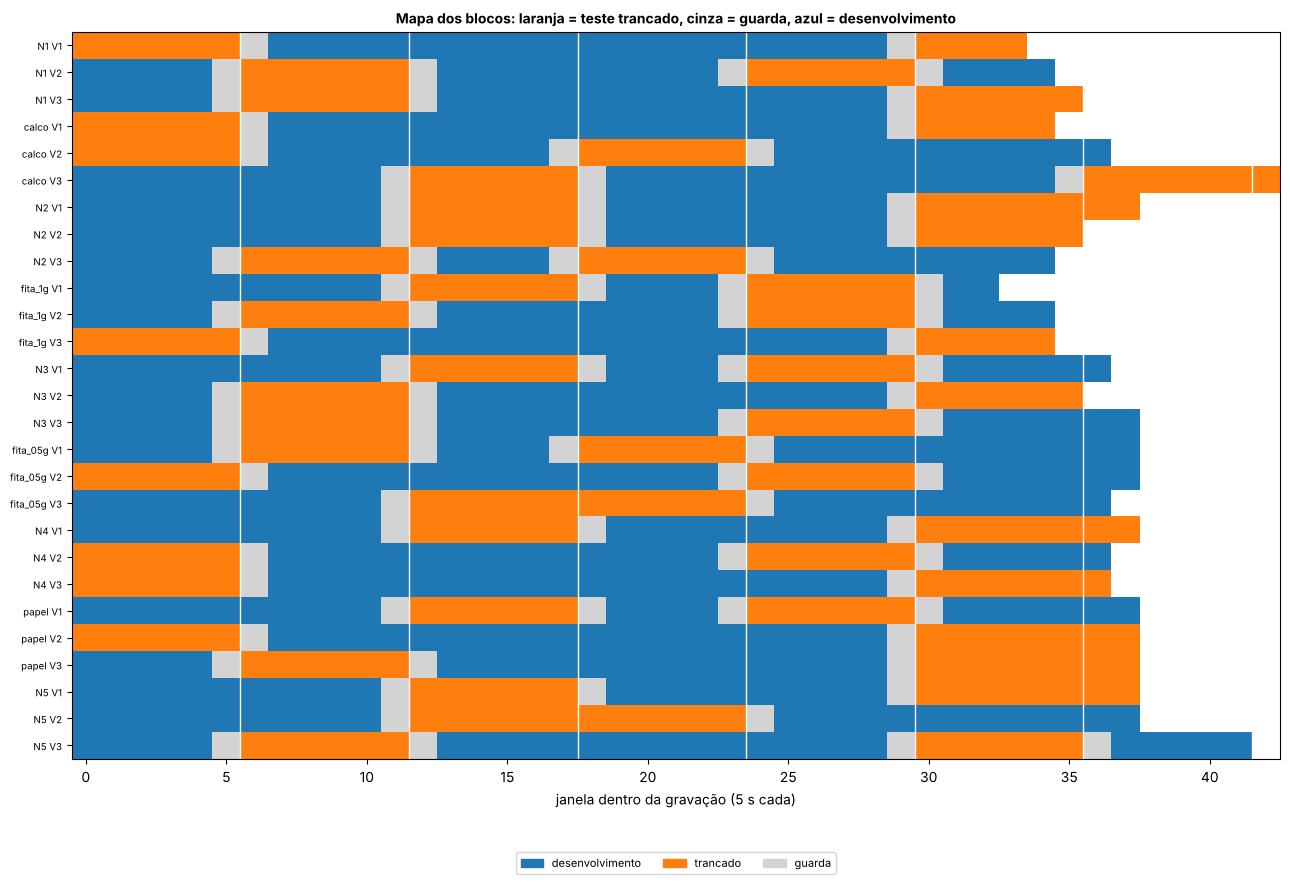

In [7]:
features["bloco"] = numerar_blocos(features)
features["papel"] = sortear_teste_trancado(features)

tabela_papeis = pd.crosstab([features["rotulo_condicao"], features["rotulo_velocidade"]], features["papel"])
tabela_papeis = tabela_papeis[["desenvolvimento", "trancado", "guarda"]]
resumo_papeis = tabela_papeis.groupby("rotulo_condicao").sum().reindex([NOME_NORMAL] + ORDEM_FALHAS_TODAS)
resumo_papeis.loc["Total"] = resumo_papeis.sum()
resumo_papeis["% trancado"] = (100 * resumo_papeis["trancado"] / resumo_papeis.sum(axis=1)).round(1)
print("Janelas por condição e papel:")
display(resumo_papeis)
print("Menor número de janelas por combinação de condição e velocidade (uma gravação de anomalia, ou os 5 lotes de normal):")
display(tabela_papeis.groupby("rotulo_condicao").min().reindex([NOME_NORMAL] + ORDEM_FALHAS_TODAS))

CORES_PAPEL = {"desenvolvimento": "tab:blue", "trancado": "tab:orange", "guarda": "lightgray"}
plotar_mapa_de_papeis(features, features["papel"], CORES_PAPEL, "Mapa dos blocos: laranja = teste trancado, cinza = guarda, azul = desenvolvimento")

### Como ficou a divisão

* **1.000 janelas:** 585 de desenvolvimento (58,5%), **332 trancadas (33,2%)** e 83 de guarda (8,3%).
* **Cada combinação de anomalia e velocidade** fica com pelo menos 17 janelas de desenvolvimento e **pelo menos 11 trancadas**. O normal (5 lotes) fica com pelo menos 106 de desenvolvimento e 60 trancadas por velocidade.
* **No mapa**, cada gravação tem um bloco laranja em cada metade, com uma janela cinza de cada lado.
* **Lembrete:** com cerca de 12 janelas trancadas por combinação, **uma janela errada vale cerca de 8 pontos de recall** naquela combinação.

## Passo 4 — Validação cruzada por blocos: como comparar modelos sem tocar no trancado

**O que é:** dividimos os blocos do desenvolvimento em `N_FOLDS` grupos (folds). Em cada rodada, **um fold é a validação** e os outros são o treino. Assim, **toda janela de desenvolvimento é prevista uma vez por um modelo que não a viu**, e juntamos essas previsões numa única matriz de confusão.

**Três regras para ser honesto:**

1. **Blocos inteiros:** um bloco de 30 s nunca fica dividido entre treino e validação.
2. **Estratificado:** os blocos de cada combinação de condição e velocidade são espalhados pelos folds (`StratifiedGroupKFold`).
3. **Guarda dentro de cada rodada:** a janela vizinha de cada bloco de validação é retirada do **treino daquela rodada**.

**Como ler a figura:** um painel por rodada. **Verde** = validação, **azul** = treino, **cinza** = guarda e **bege** = fora do desenvolvimento (trancado e a sua guarda).

In [8]:
def montar_folds(dev, n_folds=N_FOLDS, semente=SEMENTE):
    """Folds por blocos, estratificados pela classe, com guarda retirada do treino. Os índices são posições em 'dev'."""
    grupos = dev["base"] + "|" + dev["bloco"].astype(str)
    divisor = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=semente)
    folds = []
    for treino, validacao in divisor.split(dev, dev["rotulo_classe"], groups=grupos):
        em_validacao = pd.Series(False, index=dev.index)
        em_validacao.iloc[validacao] = True
        guarda = marcar_guarda(dev, em_validacao).to_numpy()
        folds.append((np.where(~em_validacao.to_numpy() & ~guarda)[0], validacao, np.where(guarda)[0]))
    return folds

Rodada 1: treino 446 janelas | validação 118 | guarda retirada 21 | classes na validação: 12 de 15 | menor classe no treino: 10 janelas
Rodada 2: treino 445 janelas | validação 118 | guarda retirada 22 | classes na validação: 13 de 15 | menor classe no treino: 13 janelas
Rodada 3: treino 454 janelas | validação 114 | guarda retirada 17 | classes na validação: 12 de 15 | menor classe no treino: 11 janelas
Rodada 4: treino 454 janelas | validação 119 | guarda retirada 12 | classes na validação: 14 de 15 | menor classe no treino: 14 janelas
Rodada 5: treino 449 janelas | validação 116 | guarda retirada 20 | classes na validação: 13 de 15 | menor classe no treino: 13 janelas


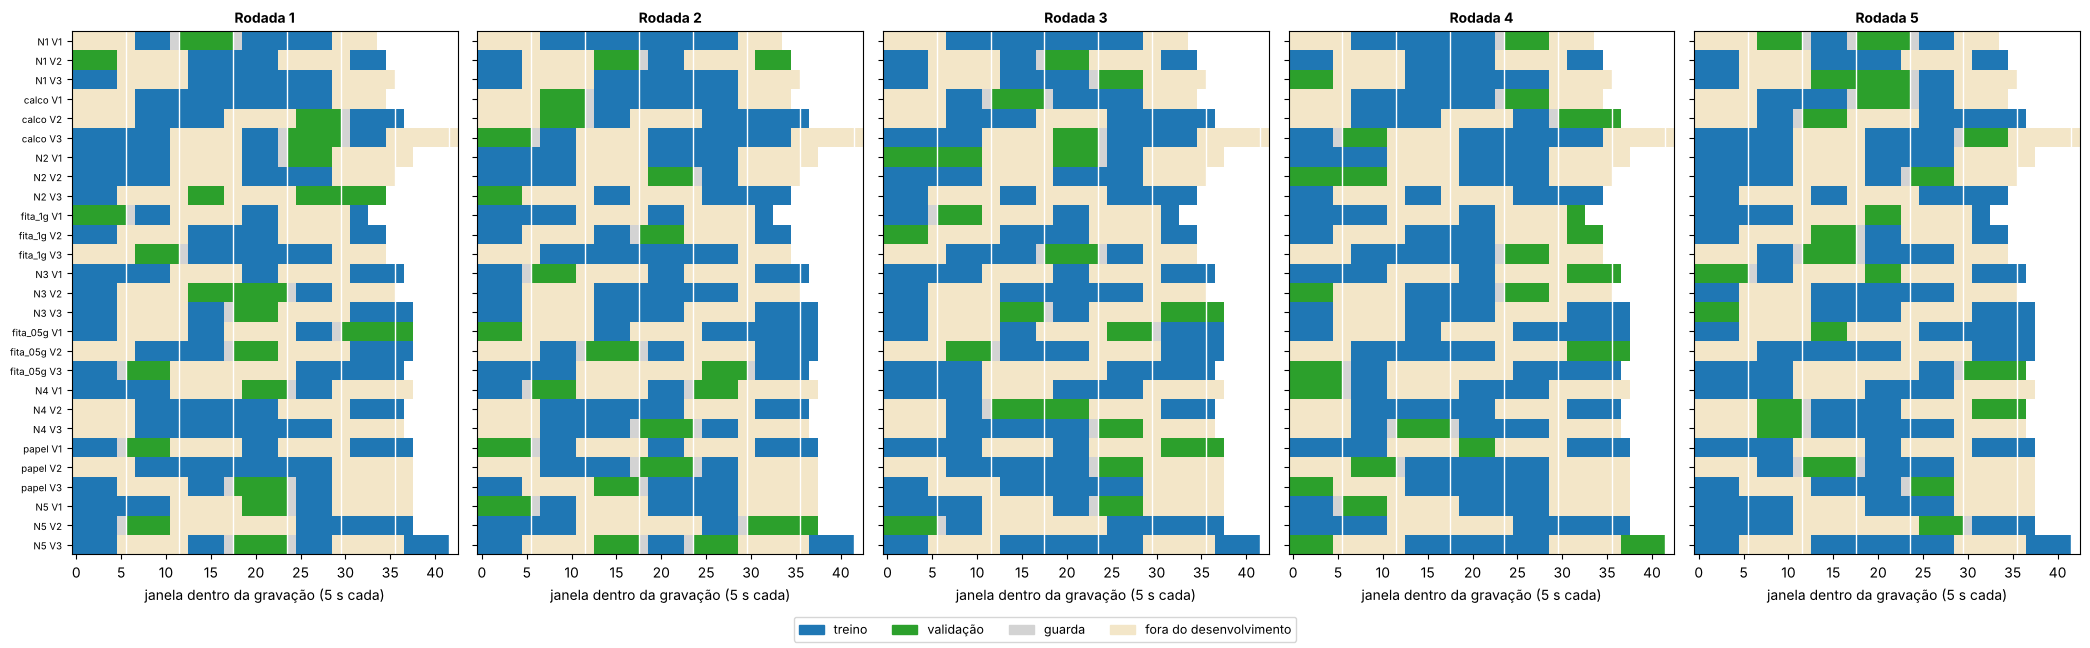

In [9]:
dev_completo = features[features["papel"] == "desenvolvimento"].copy()
trancado_completo = features[features["papel"] == "trancado"].copy()
folds_completo = montar_folds(dev_completo)

for k, (treino, validacao, guarda) in enumerate(folds_completo, start=1):
    por_classe = dev_completo.iloc[treino].groupby("rotulo_classe").size()
    print(f"Rodada {k}: treino {len(treino)} janelas | validação {len(validacao)} | guarda retirada {len(guarda)} | "
          f"classes na validação: {dev_completo.iloc[validacao]['rotulo_classe'].nunique()} de {dev_completo['rotulo_classe'].nunique()} | "
          f"menor classe no treino: {por_classe.min()} janelas")

CORES_RODADA = {"treino": "tab:blue", "validação": "tab:green", "guarda": "lightgray", "fora do desenvolvimento": "#f3e6c8"}
fig, axs = plt.subplots(1, len(folds_completo), figsize=(4.2 * len(folds_completo), 6.5), sharey=True)
for k, (ax, (treino, validacao, guarda)) in enumerate(zip(axs, folds_completo), start=1):
    papeis = pd.Series("fora do desenvolvimento", index=features.index)
    papeis[dev_completo.index[treino]] = "treino"
    papeis[dev_completo.index[validacao]] = "validação"
    papeis[dev_completo.index[guarda]] = "guarda"
    plotar_mapa_de_papeis(features, papeis, CORES_RODADA, f"Rodada {k}", ax=ax, legenda=False)
fig.legend(handles=[Patch(color=cor, label=nome) for nome, cor in CORES_RODADA.items()], loc="lower center", ncol=4, fontsize=9)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

### Como ficaram os folds

* **Cada rodada** treina com 445 a 454 janelas e valida em 114 a 119; a guarda tira de 12 a 22 janelas do treino.
* **Nem toda classe aparece em toda rodada** (12 a 14 das 15 combinações de condição e velocidade). Cada anomalia tem só 3 ou 4 blocos de desenvolvimento por velocidade, e são 5 rodadas. Isso não atrapalha: **toda janela é prevista uma vez**, por um modelo que não a viu, e as métricas juntam as 5 rodadas.
* **A menor classe no treino** tem de 10 a 14 janelas. É pouco, e é mais um motivo para não confiar em diferenças de 1 ou 2 pontos entre modelos.

## Passo 5 — Pipeline: log → scaler → modelo, com o scaler ajustado só no treino

**O vazamento que o K-Means tinha (e que aqui não pode ter):** no Notebook 04 o scaler via todas as janelas. Aqui, **média e desvio vêm só das janelas de treino de cada rodada** e são aplicados, sem recalcular, às de validação. Isso é garantido por um `Pipeline` do scikit-learn, uma "esteira" de três etapas:

1. **Log** nas features (menos a curtose). Não aprende nada: é a mesma conta para todo mundo.
2. **StandardScaler**, que aprende média e desvio **no treino** e só aplica na validação e no teste.
3. **O modelo.**

Os modelos de árvores (Random Forest, HistGradientBoosting e XGBoost) não precisam de log nem de scaler, mas passam pela **mesma esteira** para a comparação ser justa. Para eles, essas duas etapas não mudam o resultado.

### As três arquiteturas da Tarefa D

| Arquitetura | Como funciona |
| --- | --- |
| **1. Classificador único** | Um modelo só escolhe a condição, sem saber a velocidade |
| **2. Por velocidade** | A etapa 1 prevê a velocidade; a etapa 2 é um classificador de condição treinado só com as janelas daquela velocidade |
| **3. Detector → tipo** | O detector decide normal ou anomalia (Tarefa B); só as janelas acusadas vão para o diagnóstico, treinado só com falhas (Tarefa C). É a arquitetura **"um modelo chama o outro"**, planejada para a API |

Cada etapa é uma esteira completa, com o seu próprio scaler.

In [10]:
def criar_pipeline(modelo, colunas):
    """Esteira log -> StandardScaler -> modelo. Log em todas as colunas menos COLUNAS_SEM_LOG."""
    com_log = [c for c in colunas if c not in COLUNAS_SEM_LOG]
    sem_log = [c for c in colunas if c in COLUNAS_SEM_LOG]
    preparo = ColumnTransformer([("log", FunctionTransformer(np.log), com_log), ("sem_log", "passthrough", sem_log)])
    return Pipeline([("log", preparo), ("scaler", StandardScaler()), ("modelo", modelo)])


def separar_rotulo(y):
    """Separa rótulos no formato '<condição> <velocidade>' (ex.: 'papel V2') em (condições, velocidades)."""
    y = pd.Series(np.asarray(y))
    return y.str.rsplit(" ", n=1).str[0].to_numpy(), y.str.rsplit(" ", n=1).str[1].to_numpy()


class ComRotulosNumericos(BaseEstimator, ClassifierMixin):
    """O XGBoost só aceita classes numeradas (0, 1, 2...). Esta capa converte os nomes em números no treino
    e devolve os nomes na previsão, para ele funcionar como os outros modelos."""
    def __init__(self, modelo):
        self.modelo = modelo

    def fit(self, X, y):
        self.codificador_ = LabelEncoder().fit(y)
        self.classes_ = self.codificador_.classes_
        self.modelo_ = clone(self.modelo).fit(X, self.codificador_.transform(y))
        return self

    def predict(self, X):
        return self.codificador_.inverse_transform(self.modelo_.predict(X))


class ClassificadorUnico(BaseEstimator, ClassifierMixin):
    """Arquitetura 1: um modelo só, que escolhe a condição sem saber a velocidade."""
    def __init__(self, pipeline):
        self.pipeline = pipeline

    def fit(self, X, y):
        self.modelo_ = clone(self.pipeline).fit(X, separar_rotulo(y)[0])
        return self

    def predict(self, X):
        return self.modelo_.predict(X)


class PorVelocidade(BaseEstimator, ClassifierMixin):
    """Arquitetura 2: a etapa 1 prevê a velocidade; a etapa 2 é um classificador de condição daquela velocidade."""
    def __init__(self, pipeline_velocidade, pipeline_condicao):
        self.pipeline_velocidade = pipeline_velocidade
        self.pipeline_condicao = pipeline_condicao

    def fit(self, X, y):
        condicao, velocidade = separar_rotulo(y)
        self.etapa1_ = clone(self.pipeline_velocidade).fit(X, velocidade)
        self.etapa2_ = {v: clone(self.pipeline_condicao).fit(X[velocidade == v], condicao[velocidade == v]) for v in np.unique(velocidade)}
        return self

    def predict(self, X):
        velocidade = self.etapa1_.predict(X)
        condicao = np.empty(len(X), dtype=object)
        for v in np.unique(velocidade):
            condicao[velocidade == v] = self.etapa2_[v].predict(X[velocidade == v])
        return condicao


class DetectorDepoisTipo(BaseEstimator, ClassifierMixin):
    """Arquitetura 3 ("um modelo chama o outro"): o detector decide normal ou anomalia; só as janelas acusadas
    vão para o diagnóstico, treinado só com janelas de falha, que diz qual é a falha."""
    def __init__(self, pipeline_detector, pipeline_tipo):
        self.pipeline_detector = pipeline_detector
        self.pipeline_tipo = pipeline_tipo

    def fit(self, X, y):
        condicao = separar_rotulo(y)[0]
        self.detector_ = clone(self.pipeline_detector).fit(X, np.where(condicao == NOME_NORMAL, NOME_NORMAL, NOME_ANOMALIA))
        com_falha = condicao != NOME_NORMAL
        self.tipo_ = clone(self.pipeline_tipo).fit(X[com_falha], condicao[com_falha])
        return self

    def predict(self, X):
        acusadas = self.detector_.predict(X) == NOME_ANOMALIA
        condicao = np.full(len(X), NOME_NORMAL, dtype=object)
        if acusadas.any():
            condicao[acusadas] = self.tipo_.predict(X[acusadas])
        return condicao


ARQUITETURAS = {
    "classificador único": lambda fabrica, colunas: ClassificadorUnico(criar_pipeline(fabrica(), colunas)),
    "detector → tipo": lambda fabrica, colunas: DetectorDepoisTipo(criar_pipeline(fabrica(), colunas), criar_pipeline(fabrica(), colunas)),
    "por velocidade": lambda fabrica, colunas: PorVelocidade(criar_pipeline(fabrica(), colunas), criar_pipeline(fabrica(), colunas)),
}

## Passo 6 — Métricas, modelos e a regra de escolha

### Métricas

* **Acurácia balanceada:** a média dos recalls de todas as classes. Dá o mesmo peso a cada classe, então uma classe mal acertada sempre puxa a nota para baixo.
* **Pior recall:** o recall da classe mais mal acertada. Mostra se uma falha está sendo sacrificada em troca da média.
* **Falso alarme:** das janelas normais, quantas foram acusadas.

### Os modelos

| Modelo | Como funciona (em uma frase) | Por que está aqui |
| --- | --- | --- |
| **Referência: classe mais comum** | Responde sempre a classe com mais janelas | O piso: qualquer modelo útil tem de passar dele |
| **Referência: stump** | Uma árvore com uma pergunta só | Se uma pergunta já acerta quase tudo, o problema é fácil |
| **Regressão logística** | Traça fronteiras retas entre as classes | O mais simples e interpretável; foi o escolhido na coleta anterior |
| **KNN (k=5)** | Olha as 5 janelas de treino mais parecidas e vota | Depende muito da escala (por isso o scaler) |
| **SVM (RBF)** | Procura a fronteira mais afastada das classes, podendo ser curva | Clássico em diagnóstico por vibração |
| **Random Forest** | Centenas de árvores independentes que votam | Aguenta features de escalas diferentes |
| **HistGradientBoosting** | Árvores em sequência, cada uma corrigindo os erros das anteriores (versão do scikit-learn) | **Modelo mais forte**, pedido do orientador |
| **XGBoost** | A mesma ideia, na biblioteca mais usada para dados em tabela | **Modelo mais forte**, pedido do orientador |

**A grade dos modelos mais fortes**, fixada antes de ver qualquer resultado: profundidade das árvores de **2 ou 4** e **100 ou 300** árvores, com taxa de aprendizado de 0,1. No XGBoost, cada árvore vê 80% das janelas e 80% das features (`subsample` e `colsample_bytree`), o que reduz o risco de decorar o treino. São 4 combinações por biblioteca, e **cada combinação entra na tabela como um modelo**, sem ajuste fino depois.

### A regra de escolha (a mesma da coleta anterior, decidida antes dos resultados)

1. Fica o modelo (com o conjunto de features e, na Tarefa D, a arquitetura) com a **maior acurácia balanceada** na validação cruzada.
2. Os que ficarem a menos de `EMPATE_PP` (0,5 ponto) dele **empatam**.
3. Entre os empatados, fica o de **maior pior recall**. Os que ficarem a menos de 0,5 ponto dele continuam empatados.
4. Se ainda houver empate, fica **o mais simples**: regressão logística < KNN < SVM < Random Forest < boosting (menos profundidade e menos árvores primeiro; HistGradientBoosting antes do XGBoost, por não exigir outra biblioteca); classificador único < detector → tipo < por velocidade; menos features < mais features.
5. Os modelos de referência não podem ser escolhidos.

**Consequência importante:** um modelo mais forte só é escolhido se for **melhor** que o simples por mais de 0,5 ponto. Empate favorece o simples.

In [11]:
MODELOS = {
    "referência: classe mais comum": lambda: DummyClassifier(strategy="most_frequent"),
    "referência: stump (1 pergunta)": lambda: DecisionTreeClassifier(max_depth=1, random_state=SEMENTE),
    "regressão logística": lambda: LogisticRegression(max_iter=5000),
    "KNN (k=5)": lambda: KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)": lambda: SVC(kernel="rbf", C=1.0, gamma="scale"),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=300, random_state=SEMENTE, n_jobs=-1),
}
ORDEM_SIMPLICIDADE = ["regressão logística", "KNN (k=5)", "SVM (RBF)", "Random Forest"]
for profundidade in GRADE_PROFUNDIDADE:
    for arvores in GRADE_ARVORES:
        nome_hgb = f"HistGradientBoosting (prof. {profundidade}, {arvores} árvores)"
        nome_xgb = f"XGBoost (prof. {profundidade}, {arvores} árvores)"
        MODELOS[nome_hgb] = lambda p=profundidade, n=arvores: HistGradientBoostingClassifier(
            max_depth=p, max_iter=n, learning_rate=TAXA_APRENDIZADO, early_stopping=False, random_state=SEMENTE)
        MODELOS[nome_xgb] = lambda p=profundidade, n=arvores: ComRotulosNumericos(XGBClassifier(
            max_depth=p, n_estimators=n, learning_rate=TAXA_APRENDIZADO, subsample=SUBAMOSTRA, colsample_bytree=SUBAMOSTRA,
            random_state=SEMENTE, n_jobs=-1))
        ORDEM_SIMPLICIDADE += [nome_hgb, nome_xgb]


def familia_do_modelo(nome):
    """Agrupa as combinações da grade: todas as do XGBoost são a família 'XGBoost', e assim por diante."""
    for familia in ("XGBoost", "HistGradientBoosting"):
        if nome.startswith(familia):
            return familia
    return nome


print(f"{len(MODELOS)} modelos:")
for nome in MODELOS:
    print("  ", nome)

14 modelos:
   referência: classe mais comum
   referência: stump (1 pergunta)
   regressão logística
   KNN (k=5)
   SVM (RBF)
   Random Forest
   HistGradientBoosting (prof. 2, 100 árvores)
   XGBoost (prof. 2, 100 árvores)
   HistGradientBoosting (prof. 2, 300 árvores)
   XGBoost (prof. 2, 300 árvores)
   HistGradientBoosting (prof. 4, 100 árvores)
   XGBoost (prof. 4, 100 árvores)
   HistGradientBoosting (prof. 4, 300 árvores)
   XGBoost (prof. 4, 300 árvores)


In [12]:
def validar(fabrica_modelo, dados, colunas, coluna_rotulo, folds):
    """Validação cruzada por blocos: devolve a previsão de cada janela de 'dados' feita por um modelo que não a viu."""
    previsto = np.empty(len(dados), dtype=object)
    X, y = dados[colunas], dados[coluna_rotulo].to_numpy()
    for treino, validacao, _ in folds:
        previsto[validacao] = fabrica_modelo().fit(X.iloc[treino], y[treino]).predict(X.iloc[validacao])
    return previsto


def metricas(reais, previstos, classes):
    """Acurácia, acurácia balanceada, pior recall e recall de cada classe (só das classes presentes em 'reais')."""
    reais, previstos = np.asarray(reais), np.asarray(previstos)
    recalls = {c: 100 * (previstos[reais == c] == c).mean() for c in classes if (reais == c).any()}
    saida = {"acurácia (%)": 100 * (reais == previstos).mean(), "acurácia balanceada (%)": np.mean(list(recalls.values())),
             "pior recall (%)": min(recalls.values())}
    saida.update({f"recall {c} (%)": r for c, r in recalls.items()})
    return saida


def comparar_modelos(dados, conjuntos, coluna_rotulo, classes, folds, modelos=MODELOS):
    """Valida todos os modelos em todos os conjuntos. Devolve (tabela, previsões[(modelo, conjunto)])."""
    linhas, previsoes = [], {}
    for nome_conjunto, colunas in conjuntos.items():
        for nome_modelo, fabrica in modelos.items():
            previsto = validar(lambda: criar_pipeline(fabrica(), colunas), dados, colunas, coluna_rotulo, folds)
            previsoes[(nome_modelo, nome_conjunto)] = previsto
            linhas.append({"modelo": nome_modelo, "features": nome_conjunto, **metricas(dados[coluna_rotulo], previsto, classes)})
    return pd.DataFrame(linhas).set_index(["features", "modelo"]), previsoes


def sem_referencias(tabela):
    """Tira da tabela os modelos de referência (eles não podem ser escolhidos)."""
    return tabela[~tabela.index.get_level_values("modelo").str.startswith("referência")]


def aplicar_regra_de_escolha(candidatos, coluna="acurácia balanceada (%)"):
    """A regra do Passo 6: maior acurácia balanceada; empate -> maior pior recall; empate -> o mais simples."""
    empatados = candidatos[candidatos[coluna] >= candidatos[coluna].max() - EMPATE_PP]
    empatados = empatados[empatados["pior recall (%)"] >= empatados["pior recall (%)"].max() - EMPATE_PP].reset_index()
    ordem_modelo = {m: i for i, m in enumerate(ORDEM_SIMPLICIDADE)}
    ordem_arquitetura = {a: i for i, a in enumerate(ARQUITETURAS)}
    arquitetura = empatados["arquitetura"] if "arquitetura" in empatados else pd.Series("classificador único", index=empatados.index)
    empatados["_simplicidade"] = list(zip(empatados["modelo"].map(ordem_modelo).fillna(99), arquitetura.map(ordem_arquitetura).fillna(0),
                                          empatados["features"].map(lambda f: len(CONJUNTOS_TODOS[f]))))
    return empatados.sort_values("_simplicidade").iloc[0].drop("_simplicidade")


def melhor_real(tabela):
    """Aplica a regra de escolha sem os modelos de referência."""
    return aplicar_regra_de_escolha(sem_referencias(tabela))


def melhores_por_familia(tabela):
    """O melhor de cada família de modelos (pela mesma regra), para comparar modelos simples e fortes lado a lado."""
    candidatos = sem_referencias(tabela)
    familias = candidatos.index.get_level_values("modelo").map(familia_do_modelo)
    linhas = []
    for familia in dict.fromkeys(familia_do_modelo(m) for m in ORDEM_SIMPLICIDADE):
        e = aplicar_regra_de_escolha(candidatos[familias == familia])
        linhas.append({"família": familia, "melhor combinação": e["modelo"], "features": e["features"], "arquitetura": e.get("arquitetura", "—"),
                       "acurácia balanceada (%)": e["acurácia balanceada (%)"], "pior recall (%)": e["pior recall (%)"]})
    return pd.DataFrame(linhas).set_index("família")

In [13]:
def ordenar_linhas(indice):
    """Ordem das linhas dos mapas: a ordem dos modelos em MODELOS e, na Tarefa D, a das arquiteturas."""
    def chave(item):
        modelo, arquitetura = (item, None) if isinstance(item, str) else item
        return (list(MODELOS).index(modelo), list(ARQUITETURAS).index(arquitetura) if arquitetura in ARQUITETURAS else -1)
    return sorted(indice, key=chave)


def mostrar_comparacao(tabela, conjuntos, titulo, escolha=None, minimo_cor=80):
    """Dois mapas de cor (acurácia balanceada e pior recall, validação cruzada): uma linha por modelo (e arquitetura),
    uma coluna por conjunto de features. Verde = perto de 100%; vermelho = abaixo de minimo_cor. O retângulo preto
    marca a combinação escolhida pela regra do Passo 6."""
    conjuntos = list(conjuntos)
    linhas = ordenar_linhas(tabela.xs(conjuntos[0], level="features").index)
    rotulos = [linha if isinstance(linha, str) else f"{linha[0]} — {linha[1]}" for linha in linhas]
    fig, axs = plt.subplots(1, 2, figsize=(1.25 * len(conjuntos) * 2 + 9, 0.3 * len(linhas) + 2.2), sharey=True)
    for ax, coluna in zip(axs, ("acurácia balanceada (%)", "pior recall (%)")):
        mapa = tabela[coluna].unstack("features")[conjuntos].loc[linhas]
        imagem = ax.imshow(mapa.to_numpy(dtype=float), cmap="RdYlGn", vmin=minimo_cor, vmax=100, aspect="auto")
        for i in range(mapa.shape[0]):
            for j in range(mapa.shape[1]):
                ax.text(j, i, f"{mapa.iat[i, j]:.1f}", ha="center", va="center", fontsize=7)
        if escolha is not None:
            alvo = escolha["modelo"] if "arquitetura" not in escolha or not isinstance(escolha.get("arquitetura"), str) else (escolha["modelo"], escolha["arquitetura"])
            if alvo in linhas and escolha["features"] in conjuntos:
                ax.add_patch(plt.Rectangle((conjuntos.index(escolha["features"]) - 0.5, linhas.index(alvo) - 0.5), 1, 1,
                                           fill=False, edgecolor="black", linewidth=2.5))
        ax.set_xticks(range(len(conjuntos)))
        ax.set_xticklabels(conjuntos, rotation=30, ha="right", fontsize=8)
        ax.set_yticks(range(len(linhas)))
        ax.set_yticklabels(rotulos, fontsize=7)
        ax.grid(False)
        ax.set_title(coluna, fontsize=11, fontweight="bold")
    fig.colorbar(imagem, ax=axs.tolist(), shrink=0.7, label=f"% (abaixo de {minimo_cor}% fica vermelho)")
    fig.suptitle(f"{titulo} — validação cruzada" + ("  (retângulo = escolhido pela regra)" if escolha is not None else ""),
                 fontsize=12, fontweight="bold")
    plt.show()


def plotar_familias(tabela, titulo):
    """Barras horizontais: o melhor de cada família de modelos (pela regra), acurácia balanceada e pior recall."""
    familias = melhores_por_familia(tabela)
    fig, axs = plt.subplots(1, 2, figsize=(15, 0.45 * len(familias) + 1.8), sharey=True)
    minimo = min(familias["acurácia balanceada (%)"].min(), familias["pior recall (%)"].min())
    for ax, coluna, cor in zip(axs, ("acurácia balanceada (%)", "pior recall (%)"), ("tab:blue", "tab:orange")):
        valores = familias[coluna]
        ax.barh(range(len(familias)), valores, color=cor, alpha=0.8)
        for i, valor in enumerate(valores):
            ax.text(valor + 0.05, i, f"{valor:.1f}", va="center", fontsize=8)
        ax.set_xlim(max(0, minimo - 3), 101)
        ax.set_yticks(range(len(familias)))
        ax.set_yticklabels([f"{c}\n{feat}" + ("" if arq == "—" else f", {arq}") for c, feat, arq in
                        zip(familias["melhor combinação"], familias["features"], familias["arquitetura"])], fontsize=7)
        ax.invert_yaxis()
        ax.set_title(coluna, fontsize=11, fontweight="bold")
    fig.suptitle(f"{titulo} — o melhor de cada família (validação cruzada)", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()


def plotar_mapa_simples(tabela, titulo, ax=None, vmin=0, vmax=100, cmap="Reds", formato="{:.0f}", rotulo_barra="%"):
    """Mapa de cor de uma tabela pequena (por exemplo condição x velocidade), com o valor escrito em cada célula."""
    criou = ax is None
    if criou:
        fig, ax = plt.subplots(figsize=(1.3 * tabela.shape[1] + 3, 0.5 * tabela.shape[0] + 1.6))
    imagem = ax.imshow(tabela.to_numpy(dtype=float), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    for i in range(tabela.shape[0]):
        for j in range(tabela.shape[1]):
            valor = tabela.iat[i, j]
            if pd.notna(valor):
                claro = (valor - vmin) / (vmax - vmin) > 0.6
                ax.text(j, i, formato.format(valor), ha="center", va="center", fontsize=9, color="white" if claro else "black")
    ax.set_xticks(range(tabela.shape[1]))
    ax.set_xticklabels([str(c) for c in tabela.columns], fontsize=9)
    ax.set_yticks(range(tabela.shape[0]))
    ax.set_yticklabels([str(i) for i in tabela.index], fontsize=9)
    ax.grid(False)
    ax.set_title(titulo, fontsize=10, fontweight="bold")
    plt.colorbar(imagem, ax=ax, shrink=0.8, label=rotulo_barra)
    if criou:
        plt.tight_layout()
        plt.show()


def plotar_barras(tabela, titulo, rotulo_y="%", ax=None, linhas=(), limites_y=None, formato="{:.0f}", cores=None):
    """Barras agrupadas: uma posição por linha da tabela, uma barra por coluna, com o valor em cima de cada barra.
    linhas: lista de (valor, texto, cor) desenhadas como linhas horizontais tracejadas (por exemplo, limites de uma regra)."""
    criou = ax is None
    if criou:
        fig, ax = plt.subplots(figsize=(max(7, 1.3 * len(tabela) * max(1, tabela.shape[1] / 2) + 2), 4.2))
    largura = 0.8 / tabela.shape[1]
    for k, coluna in enumerate(tabela.columns):
        posicoes = np.arange(len(tabela)) + (k - (tabela.shape[1] - 1) / 2) * largura
        barras = ax.bar(posicoes, tabela[coluna], width=largura, label=str(coluna),
                        color=None if cores is None else cores[k % len(cores)], alpha=0.85)
        for barra, valor in zip(barras, tabela[coluna]):
            if pd.notna(valor):
                ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(), formato.format(valor),
                        ha="center", va="bottom", fontsize=7)
    for valor, texto, cor in linhas:
        ax.axhline(valor, color=cor, linestyle="--", linewidth=1.2, label=texto)
    ax.set_xticks(range(len(tabela)))
    ax.set_xticklabels([str(i) for i in tabela.index], fontsize=9)
    ax.set_ylabel(rotulo_y)
    if limites_y is not None:
        ax.set_ylim(*limites_y)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
    ax.set_title(titulo, fontsize=11, fontweight="bold")
    if criou:
        plt.tight_layout()
        plt.show()


def plotar_matriz(reais, previstos, classes, titulo, ax=None, classes_previstas=None):
    """Matriz real (linhas) x previsto (colunas): contagem e % da linha. A diagonal é o recall."""
    classes_previstas = classes if classes_previstas is None else classes_previstas
    tabela = pd.crosstab(pd.Series(np.asarray(reais), name="real"), pd.Series(np.asarray(previstos), name="previsto")).reindex(
        index=classes, columns=classes_previstas, fill_value=0)
    porcentagem = 100 * tabela.div(tabela.sum(axis=1).replace(0, np.nan), axis=0)
    criou = ax is None
    if criou:
        fig, ax = plt.subplots(figsize=(1.3 * len(classes_previstas) + 2.5, 1.1 * len(classes) + 1.8))
    ax.imshow(porcentagem.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=100)
    for i in range(len(classes)):
        for j in range(len(classes_previstas)):
            if tabela.iloc[i].sum() > 0:
                ax.text(j, i, f"{tabela.iat[i, j]}\n{porcentagem.iat[i, j]:.0f}%", ha="center", va="center",
                        fontsize=9 if len(classes_previstas) <= 6 else 7, color="white" if porcentagem.iat[i, j] > 60 else "black")
    ax.set_xticks(range(len(classes_previstas)))
    ax.set_xticklabels(classes_previstas, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(classes)))
    ax.set_yticklabels(classes, fontsize=8)
    ax.set_xlabel("o modelo disse")
    ax.set_ylabel("é de verdade")
    ax.grid(False)
    ax.set_title(titulo, fontsize=10, fontweight="bold")
    if criou:
        plt.tight_layout()
        plt.show()


def tabela_por_condicao(dados, acertou_ou_acusou, ordem):
    """% por condição (linhas) e velocidade (colunas) de um vetor booleano (acertou, ou foi acusada de anomalia)."""
    tabela = pd.DataFrame({"condicao": dados["rotulo_condicao"].to_numpy(), "velocidade": dados["rotulo_velocidade"].to_numpy(),
                           "valor": np.asarray(acertou_ou_acusou)})
    resultado = 100 * tabela.pivot_table(index="condicao", columns="velocidade", values="valor", aggfunc="mean")
    return resultado.reindex([c for c in ordem if c in resultado.index] + [c for c in resultado.index if c not in ordem])

## Passo 7 — O calço como estudo: o que a regra combinada diria

**O contexto:** o calço deveria ser uma anomalia, mas os Notebooks 01, 02 e 04 mostraram que ele é a falha fraca: muda a inclinação do ventilador (que fica fora das features, de propósito) e pouco a vibração.

**A decisão desta versão:** o grupo decidiu **tirar o calço das Tarefas A a D e mantê-lo só como estudo** (`CONDICOES_SO_ESTUDO`). O motivo está no Passo 14.2: com o calço no treino, o detector acusa a maior parte do normal de outra sessão. **Este passo continua aplicando a regra combinada, para registro**: ela mostra que, dentro desta sessão, o calço se diferencia do normal.

**A regra, combinada em 12 nov, antes de qualquer resultado deste notebook:**

1. Treinamos o **detector** (normal × anomalia) com **todas** as anomalias, o calço inclusive, e comparamos todos os modelos e conjuntos de features na validação cruzada. **O teste trancado não é aberto.**
2. Pegamos **o modelo escolhido pela regra do Passo 6**. Não escolhemos o modelo que mais favorece o calço.
3. Em cada velocidade, medimos nas previsões da validação cruzada:
   * o **recall do calço**: das janelas do calço, quantas foram acusadas como anomalia;
   * o **falso alarme nos normais vizinhos** (N1 e N2, gravados antes e depois do calço).
4. **O calço passa** se, em pelo menos `VELOCIDADES_MINIMAS` (2) das 3 velocidades, o recall for de pelo menos `RECALL_MINIMO` (85%) **e** o falso alarme for de no máximo `FALSO_ALARME_MAXIMO` (5%).
5. É **uma decisão só**, para as três velocidades.

**Como ler as saídas:**

* **Mapas de cor:** a comparação dos modelos do detector com o calço (verde = perto de 100%). O retângulo preto é o modelo escolhido pela regra do Passo 6.
* **Barras:** recall do calço e falso alarme nos vizinhos, por velocidade, com os limites da regra (85% e 5%) tracejados.
* **Último mapa:** em quantas velocidades o calço passaria com **cada** modelo e conjunto de features (só para ver se o resultado depende do modelo).

In [14]:
def encontrar_vizinhos(ordem_gravacoes, gravacoes_normais):
    """Para cada gravação, os normais logo antes e logo depois dela na sessão."""
    vizinhos = {}
    for i, gravacao in enumerate(ordem_gravacoes):
        antes = [g for g in ordem_gravacoes[:i] if g in gravacoes_normais][-1:]
        depois = [g for g in ordem_gravacoes[i + 1:] if g in gravacoes_normais][:1]
        vizinhos[gravacao] = antes + depois
    return vizinhos


def avaliar_regra(dados, previsto_binario, gravacao_testada, vizinhos_normais):
    """A regra do Passo 7, por velocidade: recall da gravação testada, falso alarme nos vizinhos e se passa."""
    acusada = np.asarray(previsto_binario) == NOME_ANOMALIA
    linhas = []
    for velocidade in ORDEM_VELOCIDADES:
        na_velocidade = (dados["rotulo_velocidade"] == velocidade).to_numpy()
        da_testada = na_velocidade & (dados["gravacao"] == gravacao_testada).to_numpy()
        dos_vizinhos = na_velocidade & dados["gravacao"].isin(vizinhos_normais).to_numpy()
        recall, falso_alarme = 100 * acusada[da_testada].mean(), 100 * acusada[dos_vizinhos].mean()
        linhas.append({"velocidade": velocidade, "janelas da testada": int(da_testada.sum()), "recall (%)": recall,
                       "janelas dos vizinhos": int(dos_vizinhos.sum()), "falso alarme nos vizinhos (%)": falso_alarme,
                       "passa": bool(recall >= RECALL_MINIMO and falso_alarme <= FALSO_ALARME_MAXIMO)})
    return pd.DataFrame(linhas).set_index("velocidade")

(33 s)


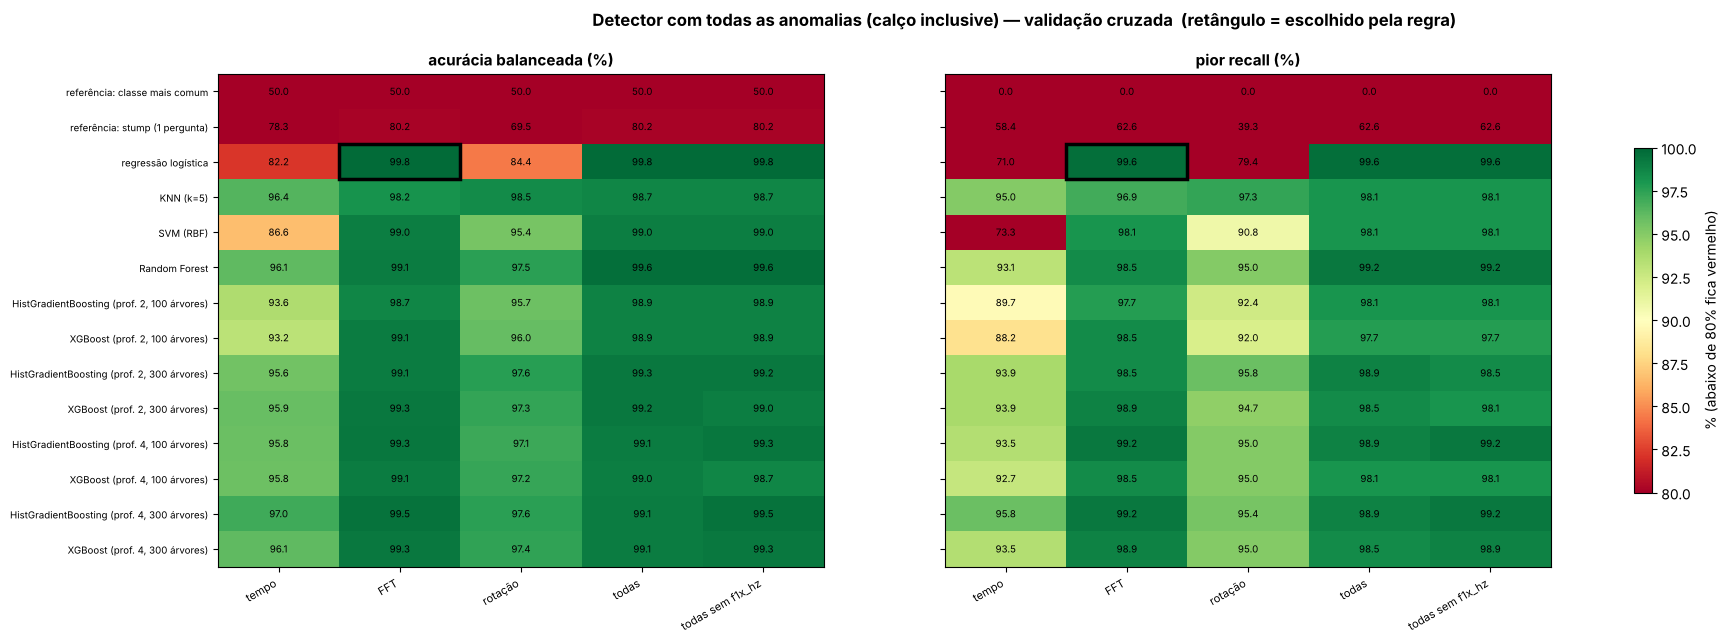

In [15]:
VIZINHOS = encontrar_vizinhos(ORDEM_GRAVACOES, GRAVACOES_NORMAIS)
CLASSES_BINARIAS = [NOME_NORMAL, NOME_ANOMALIA]

inicio = time.time()
tabela_b_completo, previsoes_b_completo = comparar_modelos(dev_completo, CONJUNTOS, "rotulo_binario", CLASSES_BINARIAS, folds_completo)
print(f"({time.time() - inicio:.0f} s)")
mostrar_comparacao(tabela_b_completo, CONJUNTOS, "Detector com todas as anomalias (calço inclusive)", escolha=melhor_real(tabela_b_completo))

Modelo escolhido pela regra do Passo 6: regressão logística, features 'FFT'
O calço passa na regra em 3 de 3 velocidades  ->  pela regra, ele FICARIA. Decisão do grupo nesta versão: só estudo.


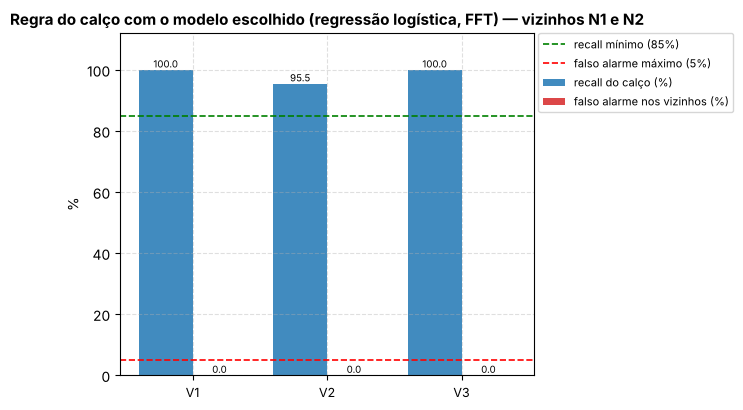

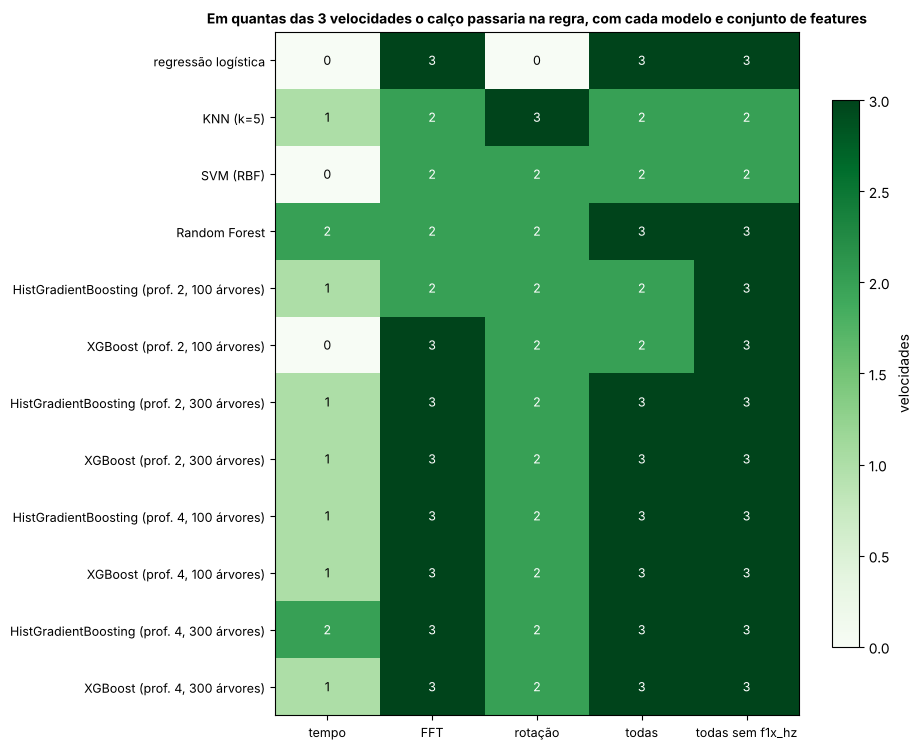

In [16]:
escolha_regra = melhor_real(tabela_b_completo)
previsto_regra = previsoes_b_completo[(escolha_regra["modelo"], escolha_regra["features"])]
regra_calco = avaliar_regra(dev_completo, previsto_regra, CONDICAO_EM_AVALIACAO, VIZINHOS[CONDICAO_EM_AVALIACAO])
CALCO_PASSA_NA_REGRA = int(regra_calco["passa"].sum()) >= VELOCIDADES_MINIMAS

print(f"Modelo escolhido pela regra do Passo 6: {escolha_regra['modelo']}, features '{escolha_regra['features']}'")
print(f"O calço passa na regra em {int(regra_calco['passa'].sum())} de {len(ORDEM_VELOCIDADES)} velocidades  ->  "
      f"pela regra, ele {'FICARIA' if CALCO_PASSA_NA_REGRA else 'SAIRIA'}. "
      f"Decisão do grupo nesta versão: {'só estudo' if CONDICAO_EM_AVALIACAO in CONDICOES_SO_ESTUDO else 'fica nos modelos'}.")
plotar_barras(regra_calco[["recall (%)", "falso alarme nos vizinhos (%)"]].rename(columns={"recall (%)": "recall do calço (%)"}),
              f"Regra do calço com o modelo escolhido ({escolha_regra['modelo']}, {escolha_regra['features']}) — vizinhos {' e '.join(VIZINHOS[CONDICAO_EM_AVALIACAO])}",
              linhas=[(RECALL_MINIMO, f"recall mínimo ({RECALL_MINIMO:.0f}%)", "green"), (FALSO_ALARME_MAXIMO, f"falso alarme máximo ({FALSO_ALARME_MAXIMO:.0f}%)", "red")],
              limites_y=(0, 112), formato="{:.1f}", cores=["tab:blue", "tab:red"])

velocidades_que_passam = pd.Series({chave: int(avaliar_regra(dev_completo, previsto, CONDICAO_EM_AVALIACAO, VIZINHOS[CONDICAO_EM_AVALIACAO])["passa"].sum())
                                    for chave, previsto in previsoes_b_completo.items()})
velocidades_que_passam.index.names = ["modelo", "features"]
plotar_mapa_simples(velocidades_que_passam.unstack("features").reindex(index=[m for m in MODELOS if not m.startswith("referência")], columns=list(CONJUNTOS)),
                    "Em quantas das 3 velocidades o calço passaria na regra, com cada modelo e conjunto de features",
                    vmin=0, vmax=len(ORDEM_VELOCIDADES), cmap="Greens", rotulo_barra="velocidades")

### Conclusões do Passo 7

**Modelo escolhido pela regra do Passo 6 para o detector com o calço:** regressão logística com as features de FFT (acurácia balanceada de 99,8%).

* **Pelas barras, o calço passa na regra nas 3 velocidades:** recall de 100%, 95,5% e 100%, com 0% de falso alarme nos vizinhos (N1 e N2). Pela regra combinada em 12 nov, ele **ficaria**.
* **Mesmo assim, ele sai dos modelos nesta versão, por decisão do grupo (13 nov).** A regra perguntava só "o calço se diferencia do normal **desta sessão**?". O Passo 14.2 mostra o custo que ela não media: com o calço no treino, o detector acusa de 69% a 90% do normal de outra sessão.
* **O resultado depende das features, e quase nada do modelo** (último mapa). Com FFT, todas ou todas sem `f1x_hz`, todos os modelos passam em 2 ou 3 velocidades. **Só com as features de tempo, 10 dos 12 modelos passam em 0 ou 1 velocidade.** O calço quase não muda a intensidade da vibração; ele aparece em algumas faixas do espectro.

### 7.1 — Placebo (informação, não muda a decisão): um lote normal passaria na mesma regra?

**O que buscamos:** o Notebook 04 mostrou que um lote normal pode ser separado dos outros **sem falha nenhuma**, só por ter sido gravado em outro momento da sessão. Como o detector é treinado e validado com blocos **da mesma gravação** do calço, ele pode ter aprendido "esta gravação" em vez de "esta falha". O placebo mede isso.

**Como:** repetimos o Passo 7 com o **mesmo modelo e as mesmas features**, mas chamando de "anomalia" um **lote normal** (N2, N3 ou N4, um por vez), e aplicamos a mesma regra, com os lotes normais vizinhos dele (por exemplo, N3 contra N2 e N4).

**Como ler:**

* **Se nenhum placebo passar:** a regra distingue falha de gravação, e o resultado do calço fica mais forte.
* **Se os placebos também passarem:** dentro desta sessão, **a regra não consegue distinguir "tem uma falha" de "é outra gravação"**. Nesse caso, passar na regra é necessário, mas não suficiente, e a evidência a favor do calço precisa vir de outro lugar (o placebo sem rótulos do Notebook 04, o Passo 12.3 e uma nova gravação do calço em outra sessão).

**Esta seção não altera a decisão do Passo 7.** A regra foi fixada antes dos resultados e é aplicada como combinada.

**Limitação:** os vizinhos do placebo ficam um pouco mais longe no tempo do que os do calço (dois blocos da sessão, contra um). Isso tende a deixar o placebo mais fácil de separar.

In [17]:
def rodar_placebo(dados, folds, lote, escolha, vizinhos):
    """Trata um lote normal como anomalia, valida o mesmo modelo nos mesmos folds e aplica a regra do Passo 7."""
    falso = dados.copy()
    falso.loc[falso["gravacao"] == lote, "rotulo_binario"] = NOME_ANOMALIA
    colunas = CONJUNTOS_TODOS[escolha["features"]]
    previsto = validar(lambda: criar_pipeline(MODELOS[escolha["modelo"]](), colunas), falso, colunas, "rotulo_binario", folds)
    return avaliar_regra(falso, previsto, lote, vizinhos[lote])

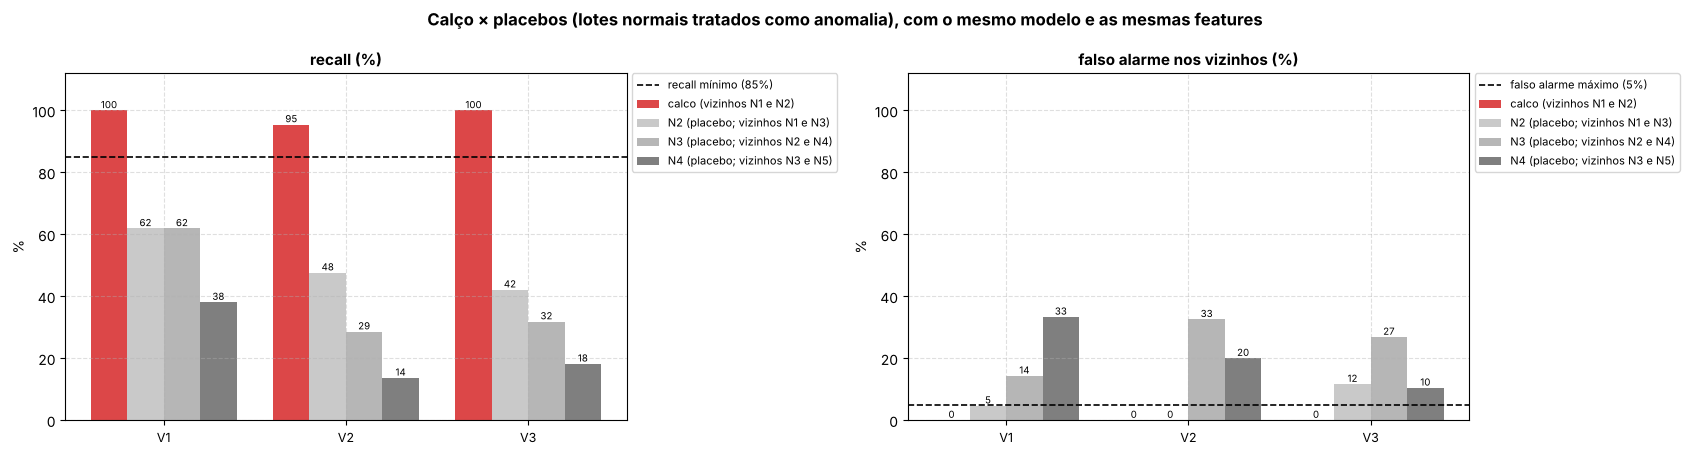

Velocidades em que cada um passa na regra: {'calco (vizinhos N1 e N2)': 3, 'N2 (placebo; vizinhos N1 e N3)': 0, 'N3 (placebo; vizinhos N2 e N4)': 0, 'N4 (placebo; vizinhos N3 e N5)': 0}


In [18]:
LOTES_PLACEBO = [g for g in GRAVACOES_NORMAIS if len(VIZINHOS[g]) == 2]
placebos = {f"{lote} (placebo; vizinhos {' e '.join(VIZINHOS[lote])})": rodar_placebo(dev_completo, folds_completo, lote, escolha_regra, VIZINHOS)
            for lote in LOTES_PLACEBO}
comparacao_placebo = pd.concat({f"{CONDICAO_EM_AVALIACAO} (vizinhos {' e '.join(VIZINHOS[CONDICAO_EM_AVALIACAO])})": regra_calco, **placebos},
                               names=["gravação testada"])
fig, axs = plt.subplots(1, 2, figsize=(17, 4.6))
for ax, coluna, limite, texto in ((axs[0], "recall (%)", RECALL_MINIMO, "recall mínimo"), (axs[1], "falso alarme nos vizinhos (%)", FALSO_ALARME_MAXIMO, "falso alarme máximo")):
    tabela = comparacao_placebo[coluna].unstack("gravação testada")[list(pd.unique(comparacao_placebo.index.get_level_values(0)))]
    plotar_barras(tabela, coluna, ax=ax, linhas=[(limite, f"{texto} ({limite:.0f}%)", "black")], limites_y=(0, 112), formato="{:.0f}",
                  cores=["tab:red", "silver", "darkgray", "dimgray"])
fig.suptitle("Calço × placebos (lotes normais tratados como anomalia), com o mesmo modelo e as mesmas features", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()
print("Velocidades em que cada um passa na regra:", comparacao_placebo["passa"].groupby("gravação testada", sort=False).sum().to_dict())

### Conclusões do Passo 7.1

* **Nenhum placebo passa na regra**, em nenhuma velocidade. Tratado como "anomalia", um lote normal tem recall de 14% a 62% (longe dos 85%) e falso alarme de até 33% nos vizinhos.
* **O calço é diferente de "só outra gravação desta sessão":** 95% a 100% de recall com 0% de falso alarme. **Dentro desta sessão**, o calço é separável do normal.
* **O que o placebo não responde:** se essa diferença se repete em outra sessão. O Passo 14.2 mostra que ensinar essa diferença ao detector custa caro fora desta sessão. Por isso o calço fica como estudo.

In [19]:
# A partir daqui, as Tarefas A a D deixam de fora as condições só de estudo (decisão do grupo, Passo 1).
CONDICOES_FORA = list(CONDICOES_SO_ESTUDO)
ORDEM_FALHAS = [f for f in ORDEM_FALHAS_TODAS if f not in CONDICOES_FORA]
ORDEM_CONDICOES = [NOME_NORMAL] + ORDEM_FALHAS
ORDEM_CLASSES = [f"{c} {v}" for v in ORDEM_VELOCIDADES for c in ORDEM_CONDICOES]

dev = dev_completo[~dev_completo["rotulo_condicao"].isin(CONDICOES_FORA)].copy()
trancado = trancado_completo[~trancado_completo["rotulo_condicao"].isin(CONDICOES_FORA)].copy()
folds = montar_folds(dev)
dev_falhas = dev[dev["rotulo_binario"] == NOME_ANOMALIA].copy()
trancado_falhas = trancado[trancado["rotulo_binario"] == NOME_ANOMALIA].copy()
folds_falhas = montar_folds(dev_falhas)

print(f"Condições nas Tarefas A a D: {ORDEM_CONDICOES}" + (f" (fora: {CONDICOES_FORA})" if CONDICOES_FORA else ""))
print(f"Desenvolvimento: {len(dev)} janelas ({len(dev_falhas)} de falha). Trancado: {len(trancado)} janelas ({len(trancado_falhas)} de falha).")

Condições nas Tarefas A a D: ['normal', 'fita_1g', 'fita_05g', 'papel'] (fora: ['calco'])
Desenvolvimento: 514 janelas (191 de falha). Trancado: 296 janelas (111 de falha).


## Passo 8 — Tarefa A: qual é a velocidade de uma janela?

**O que buscamos:** a etapa de velocidade da arquitetura "por velocidade" e da API. Além dos cinco conjuntos de features, testamos **só `f1x_hz`** (a rotação estimada), que foi a escolha da coleta anterior.

**Como ler:** os dois mapas de cor (acurácia balanceada e pior recall) têm uma linha por modelo e uma coluna por conjunto de features; verde = perto de 100%, e o retângulo preto é o escolhido. Os modelos mais fortes ficam nas últimas linhas. As barras mostram o melhor de cada família.

(51 s)


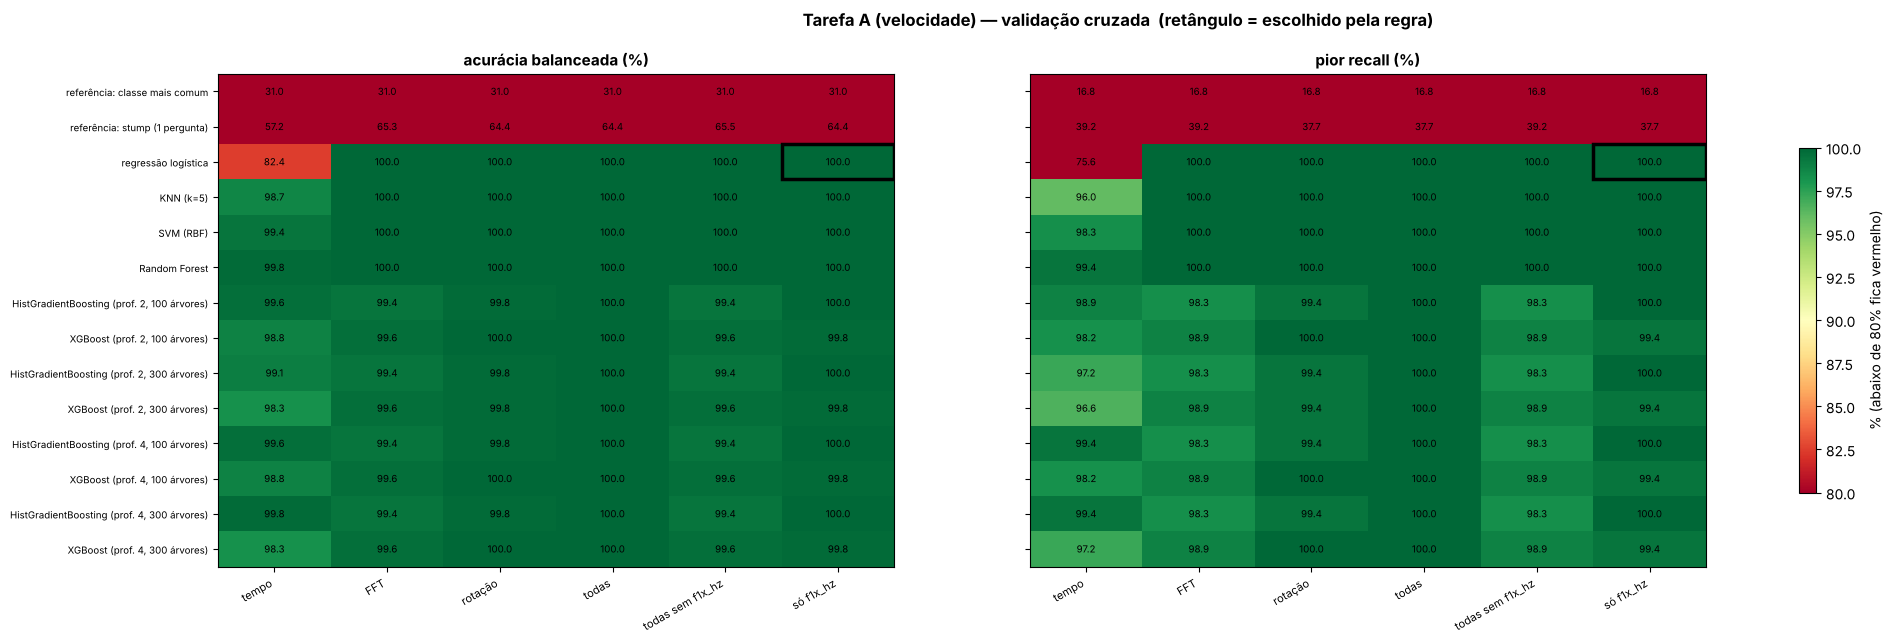

Escolhido pela regra: regressão logística, features 'só f1x_hz'


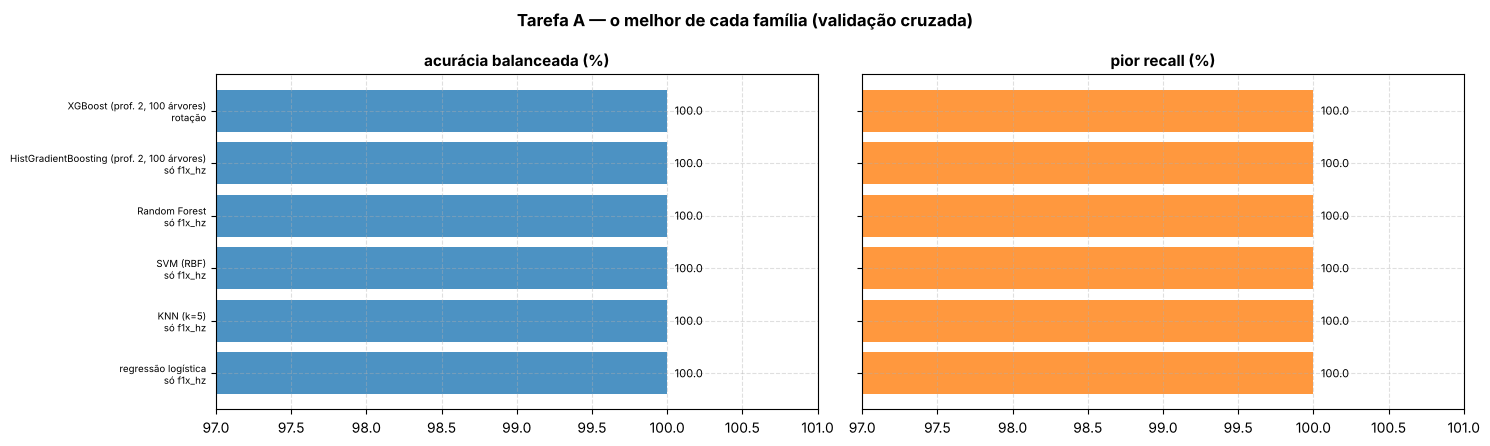

In [20]:
inicio = time.time()
tabela_a, previsoes_a = comparar_modelos(dev, CONJUNTOS_TODOS, "rotulo_velocidade", ORDEM_VELOCIDADES, folds)
print(f"({time.time() - inicio:.0f} s)")
escolha_a = melhor_real(tabela_a)
mostrar_comparacao(tabela_a, CONJUNTOS_TODOS, "Tarefa A (velocidade)", escolha=escolha_a)
print(f"Escolhido pela regra: {escolha_a['modelo']}, features '{escolha_a['features']}'")
plotar_familias(tabela_a, "Tarefa A")

### Conclusões do Passo 8

* **Só com `f1x_hz`, a regressão logística acerta 100%** (é a escolha pela regra, o conjunto com menos features entre os empatados). Com FFT, rotação ou todas, os modelos ficam entre 99,4% e 100%.
* **Só com as features de tempo, a regressão logística cai para 82,4%**; os outros modelos ficam entre 98,3% e 99,8%.
* **O melhor de cada família faz 100%.** Para a velocidade, não há o que um modelo mais forte possa acrescentar.

## Passo 9 — Tarefa B: normal ou anomalia? (o detector)

**O que buscamos:** o detector da arquitetura "um modelo chama o outro", agora **sem o calço** (normal × fita 1 g, fita 0,5 g e papel).

**Como ler o mapa "% chamada de anomalia":** a linha do **normal** é o **falso alarme** (quanto mais claro, melhor); as linhas das falhas são o **recall** de cada falha (quanto mais escuro, melhor), por velocidade.

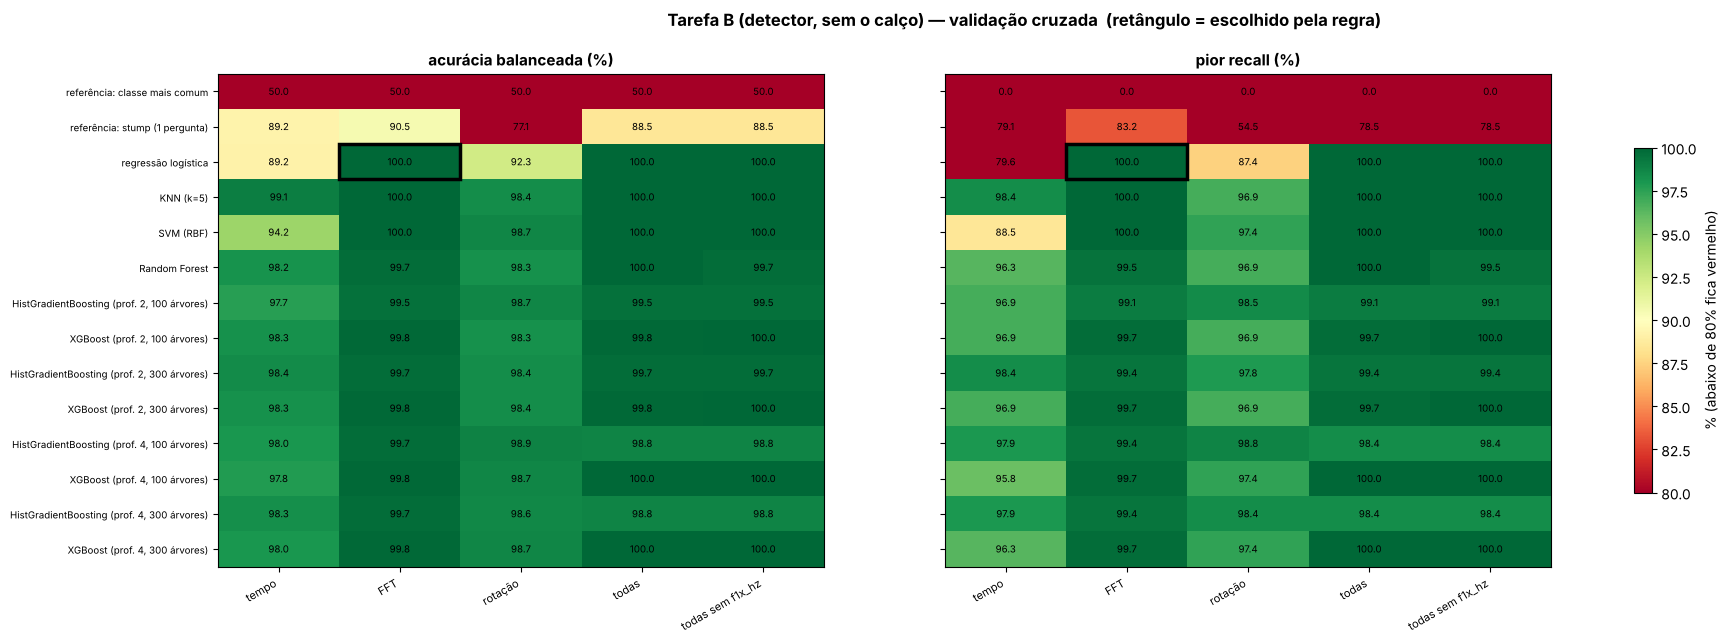

Escolhido pela regra: regressão logística, features 'FFT'


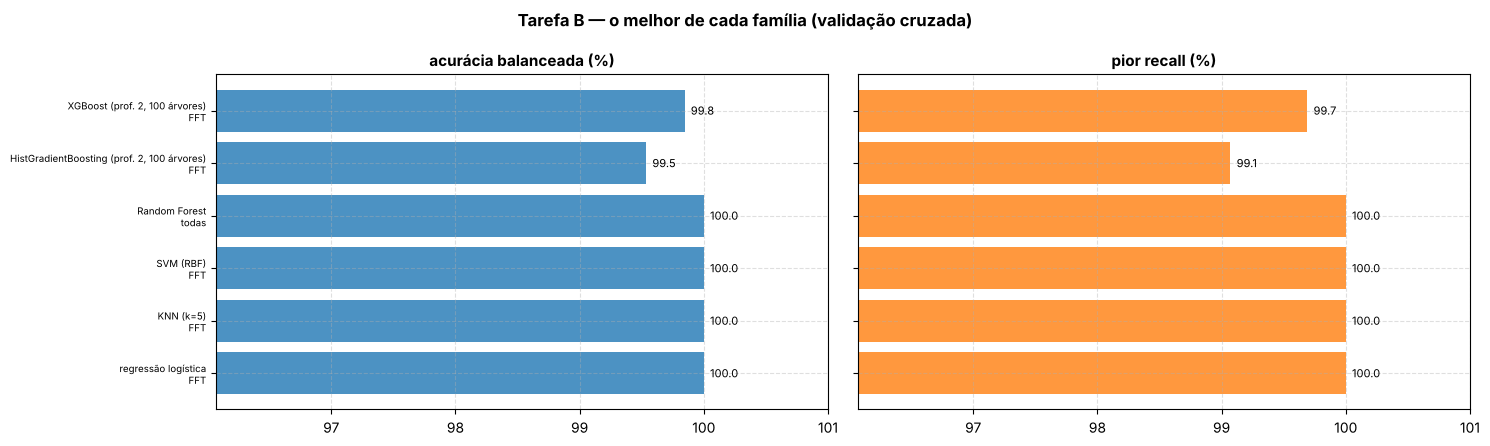

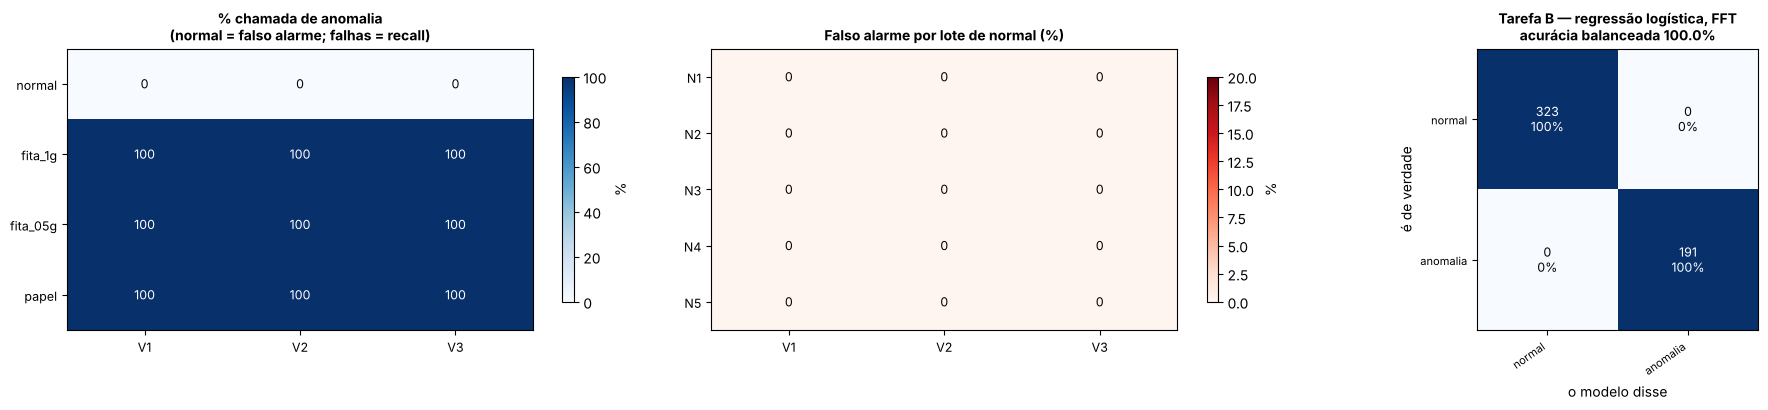

In [21]:
if not CONDICOES_FORA:
    tabela_b, previsoes_b = tabela_b_completo, previsoes_b_completo      # as mesmas condições do Passo 7: não precisa rodar de novo
else:
    tabela_b, previsoes_b = comparar_modelos(dev, CONJUNTOS, "rotulo_binario", CLASSES_BINARIAS, folds)
escolha_b = melhor_real(tabela_b)
previsto_b = previsoes_b[(escolha_b["modelo"], escolha_b["features"])]
mostrar_comparacao(tabela_b, CONJUNTOS, "Tarefa B (detector, sem o calço)", escolha=escolha_b)
print(f"Escolhido pela regra: {escolha_b['modelo']}, features '{escolha_b['features']}'")
plotar_familias(tabela_b, "Tarefa B")

normais_dev = (dev["rotulo_binario"] == NOME_NORMAL).to_numpy()
falso_alarme_por_lote = 100 * pd.Series(previsto_b[normais_dev] == NOME_ANOMALIA).groupby(
    [dev.loc[normais_dev, "gravacao"].to_numpy(), dev.loc[normais_dev, "rotulo_velocidade"].to_numpy()]).mean().unstack()
fig, axs = plt.subplots(1, 3, figsize=(19, 4.2), gridspec_kw={"width_ratios": [1, 1, 0.9]})
plotar_mapa_simples(tabela_por_condicao(dev, previsto_b == NOME_ANOMALIA, ORDEM_CONDICOES), "% chamada de anomalia\n(normal = falso alarme; falhas = recall)", ax=axs[0], cmap="Blues")
plotar_mapa_simples(falso_alarme_por_lote, "Falso alarme por lote de normal (%)", ax=axs[1], vmax=20)
plotar_matriz(dev["rotulo_binario"], previsto_b, CLASSES_BINARIAS,
              f"Tarefa B — {escolha_b['modelo']}, {escolha_b['features']}\nacurácia balanceada {escolha_b['acurácia balanceada (%)']:.1f}%", ax=axs[2])
plt.tight_layout()
plt.show()

### Conclusões do Passo 9

* **Sem o calço, o detector fica perfeito na validação cruzada:** regressão logística com FFT, **100% de acurácia balanceada e 100% de pior recall**. Falso alarme de **0% em todos os lotes e velocidades**, e recall de 100% em todas as falhas.
* **Com FFT, todas ou todas sem `f1x_hz`, quase todos os modelos ficam entre 99,5% e 100%.** O XGBoost chega a 100% em vários conjuntos; o HistGradientBoosting, a 99,7% no melhor caso.
* **Comparado à primeira versão (com o calço):** a acurácia passou de 99,8% para 100%, e o stump (uma pergunta só) subiu de 80,2% para 90,5%. A falha que segurava o detector era o calço.
* **Só com as features de tempo**, a regressão logística cai para 89,2% (pior recall de 79,6%), e os modelos de árvores ficam entre 97,7% e 98,4%.

## Passo 10 — Tarefa C: qual é a falha? (o diagnóstico)

**O que buscamos:** o segundo modelo da arquitetura "um modelo chama o outro". Ele é treinado e avaliado **só com janelas de falha**, e precisa dizer qual é.

**O par a vigiar** (Notebook 02): **fita 1 g × fita 0,5 g**, que é a mesma falha com massas diferentes.

(36 s)


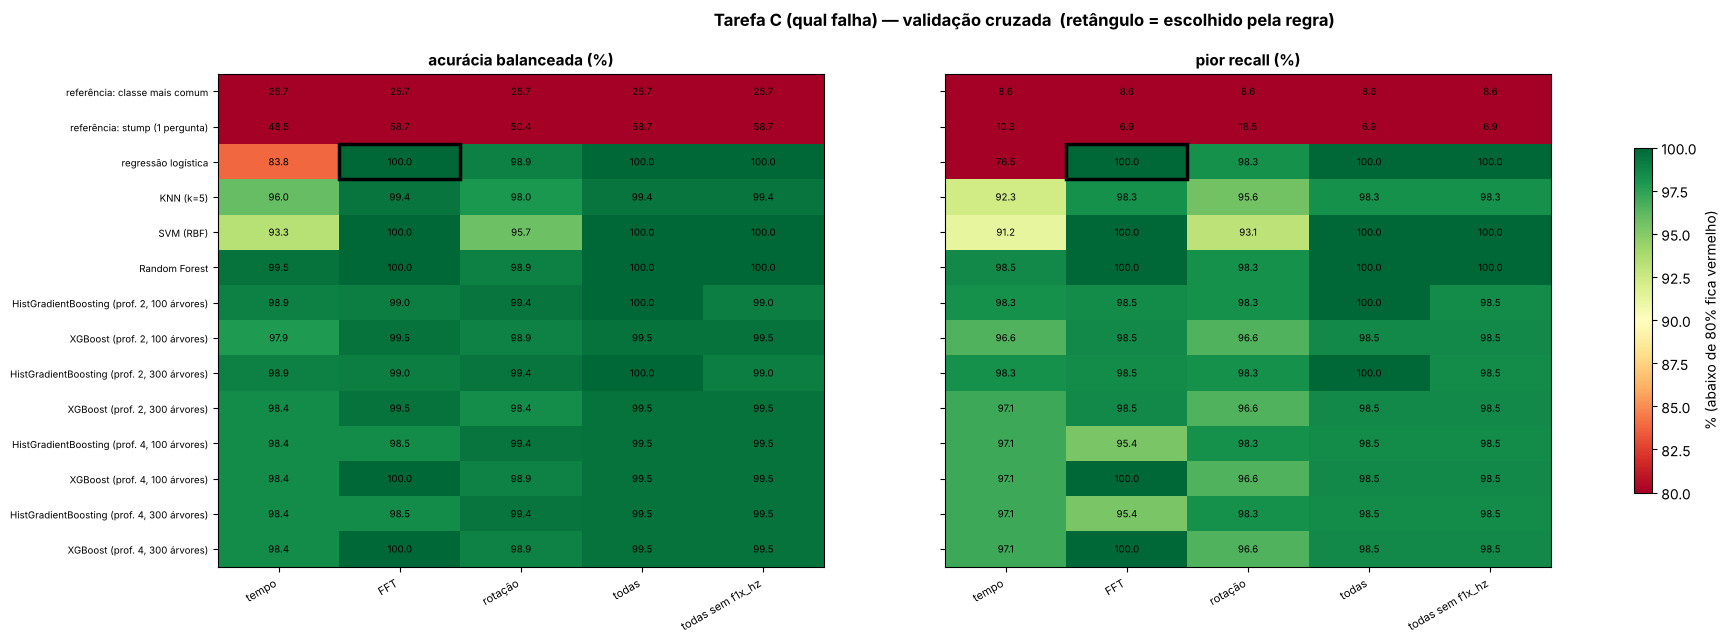

Escolhido pela regra: regressão logística, features 'FFT'


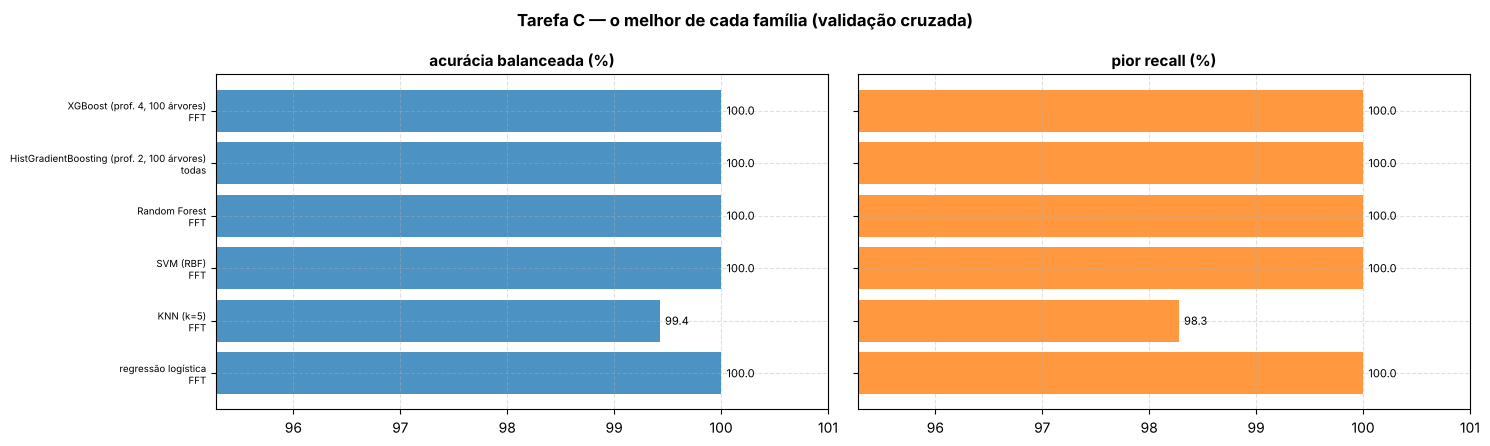

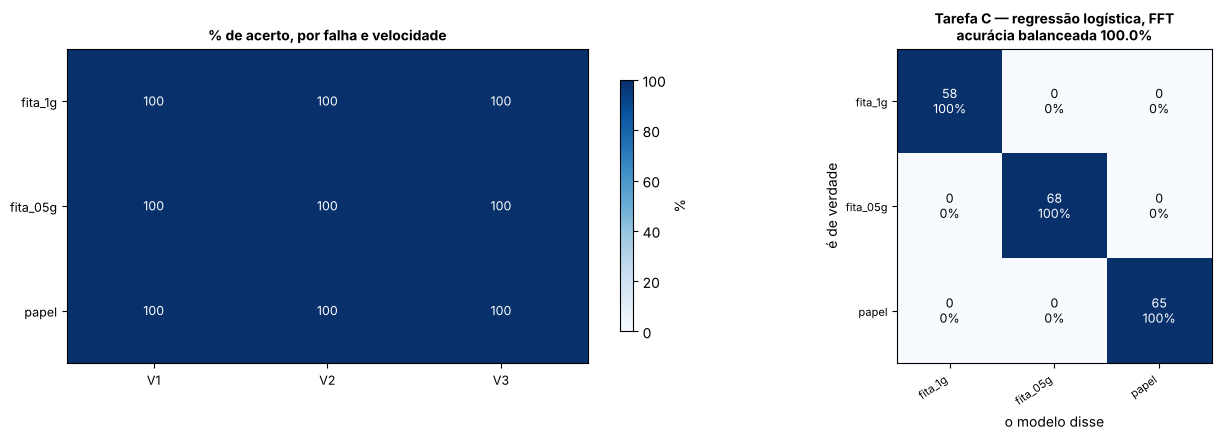

In [22]:
inicio = time.time()
tabela_c, previsoes_c = comparar_modelos(dev_falhas, CONJUNTOS, "rotulo_condicao", ORDEM_FALHAS, folds_falhas)
print(f"({time.time() - inicio:.0f} s)")
escolha_c = melhor_real(tabela_c)
previsto_c = previsoes_c[(escolha_c["modelo"], escolha_c["features"])]
mostrar_comparacao(tabela_c, CONJUNTOS, "Tarefa C (qual falha)", escolha=escolha_c)
print(f"Escolhido pela regra: {escolha_c['modelo']}, features '{escolha_c['features']}'")
plotar_familias(tabela_c, "Tarefa C")
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
plotar_mapa_simples(tabela_por_condicao(dev_falhas, previsto_c == dev_falhas["rotulo_condicao"].to_numpy(), ORDEM_FALHAS),
                    "% de acerto, por falha e velocidade", ax=axs[0], cmap="Blues")
plotar_matriz(dev_falhas["rotulo_condicao"], previsto_c, ORDEM_FALHAS,
              f"Tarefa C — {escolha_c['modelo']}, {escolha_c['features']}\nacurácia balanceada {escolha_c['acurácia balanceada (%)']:.1f}%", ax=axs[1])
plt.tight_layout()
plt.show()

### Conclusões do Passo 10

* **Escolhido: regressão logística com FFT, com 100%** em todas as falhas e velocidades. SVM, Random Forest e XGBoost (prof. 4, com FFT) também chegam a 100%. Pela regra, fica o mais simples dos empatados.
* **O par fita 1 g × fita 0,5 g** não deu trabalho na validação: 100% nas duas, nas três velocidades.
* **Os modelos de árvores ficam entre 98,4% e 100%,** quase sempre 0,5 a 1,5 ponto abaixo da regressão logística.
* **Diferença para a primeira versão:** lá o escolhido foi o SVM (a regressão logística perdia no pior recall por causa do calço). Sem o calço, a regressão logística empata em 100% e é a mais simples.

## Passo 11 — Tarefa D: a condição, com três arquiteturas

**O que buscamos:** o sistema completo. Cada modelo e conjunto de features é testado nas três arquiteturas do Passo 5, e a regra de escolha decide a combinação.

**Como ler:** os mapas de cor têm uma linha por modelo e arquitetura e uma coluna por conjunto de features. As barras comparam o melhor de cada arquitetura e o melhor de cada família de modelos.

In [23]:
def comparar_arquiteturas(dados, conjuntos, folds, modelos=MODELOS):
    """Valida cada modelo e conjunto nas três arquiteturas. Treina com 'rotulo_classe' e avalia a condição prevista."""
    linhas, previsoes = [], {}
    reais = dados["rotulo_condicao"].to_numpy()
    for nome_conjunto, colunas in conjuntos.items():
        for nome_modelo, fabrica in modelos.items():
            for nome_arquitetura in (["classificador único"] if nome_modelo.startswith("referência") else list(ARQUITETURAS)):
                construir = ARQUITETURAS[nome_arquitetura]
                previsto = validar(lambda: construir(fabrica, colunas), dados, colunas, "rotulo_classe", folds)
                previsoes[(nome_modelo, nome_conjunto, nome_arquitetura)] = previsto
                linhas.append({"features": nome_conjunto, "modelo": nome_modelo, "arquitetura": nome_arquitetura,
                               **metricas(reais, previsto, ORDEM_CONDICOES)})
    return pd.DataFrame(linhas).set_index(["features", "modelo", "arquitetura"]), previsoes

(282 s)


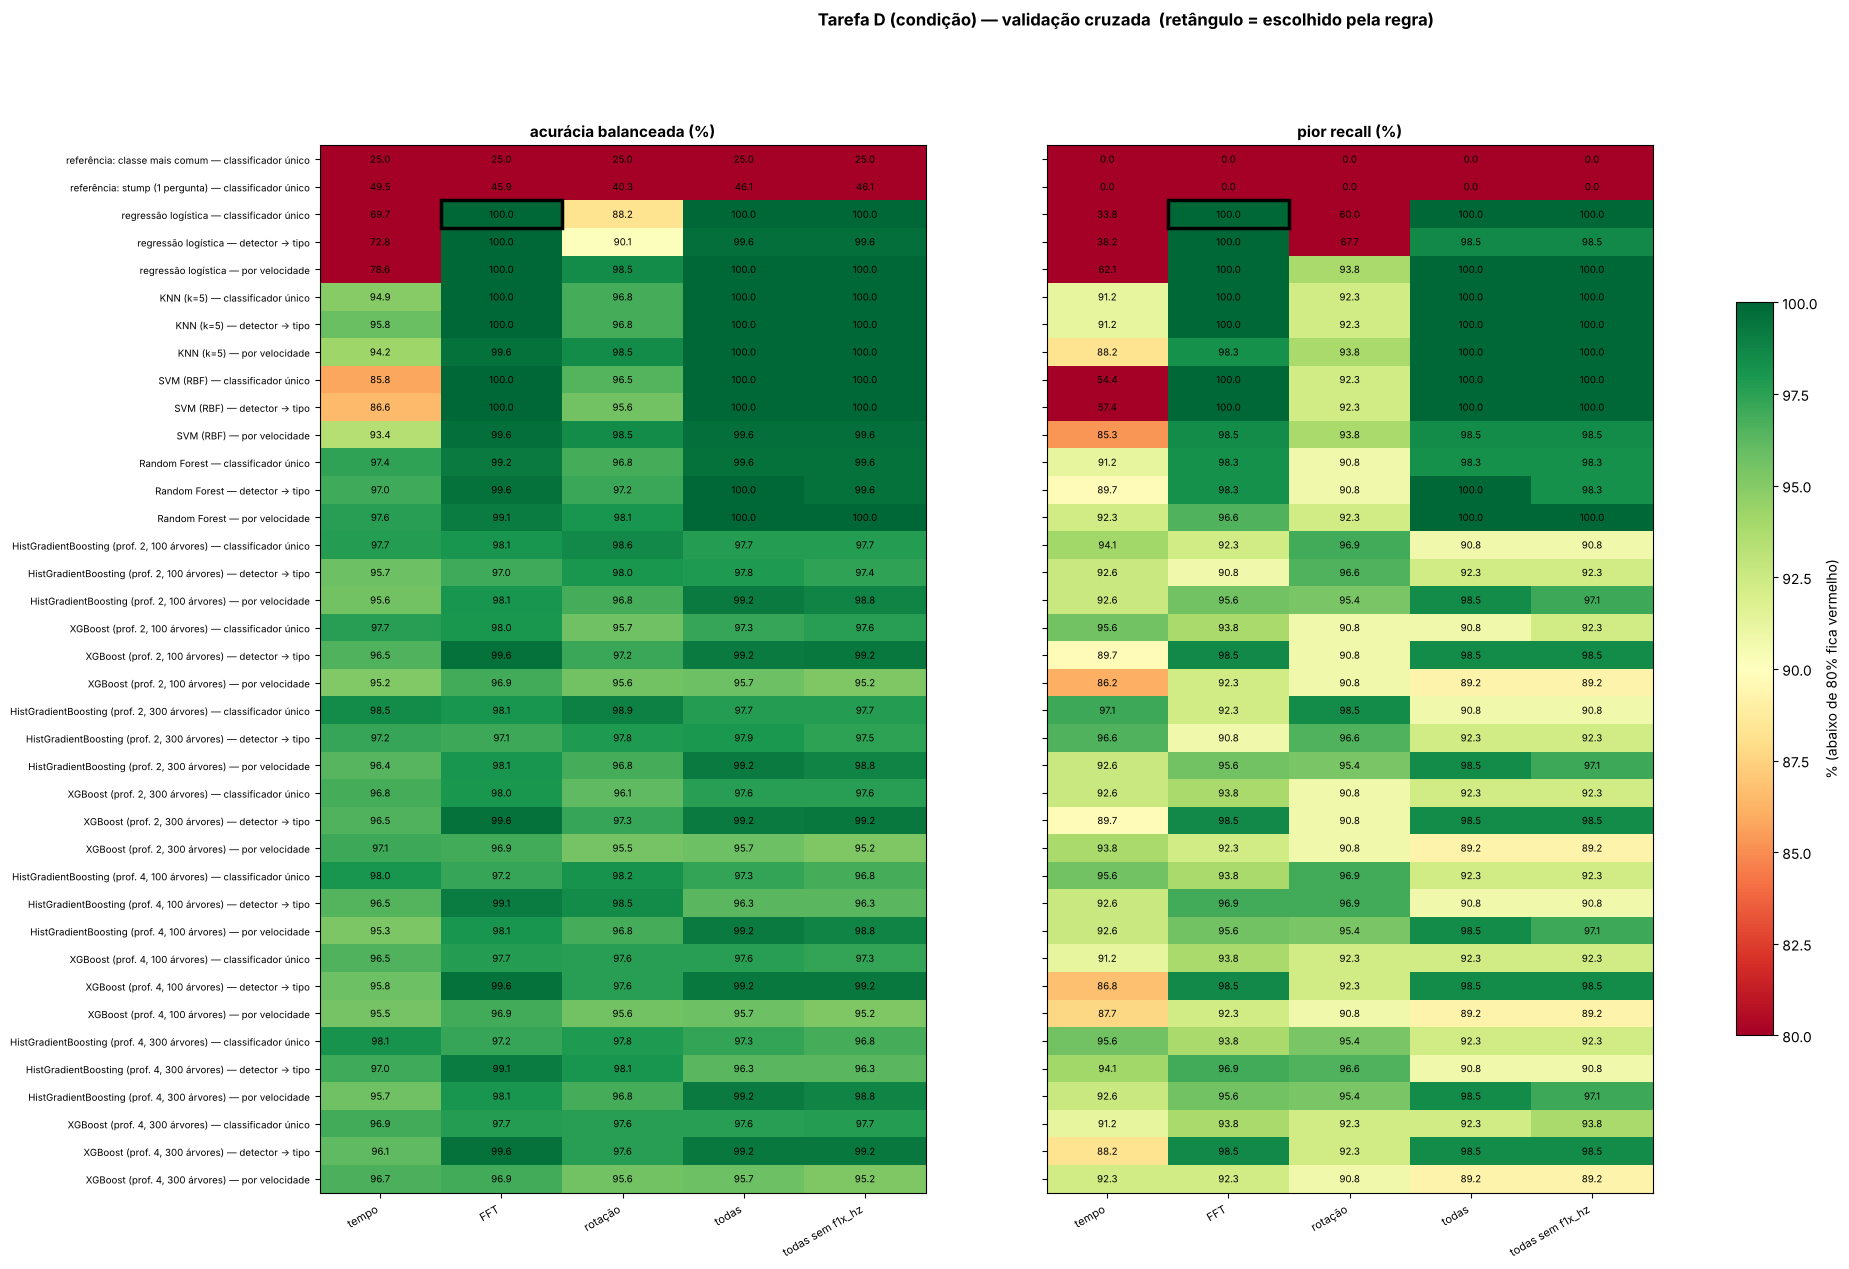

Escolhido pela regra: regressão logística, classificador único, features 'FFT'


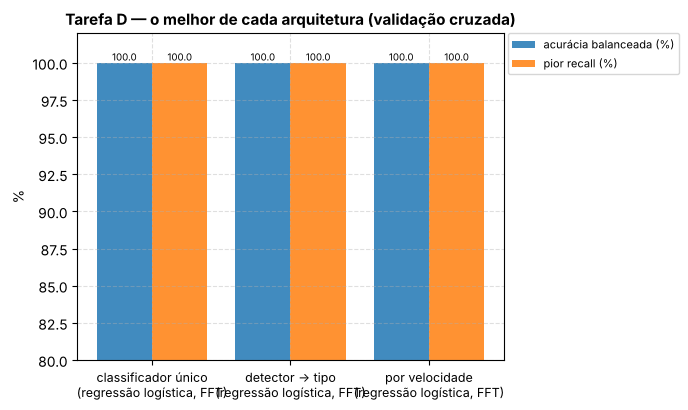

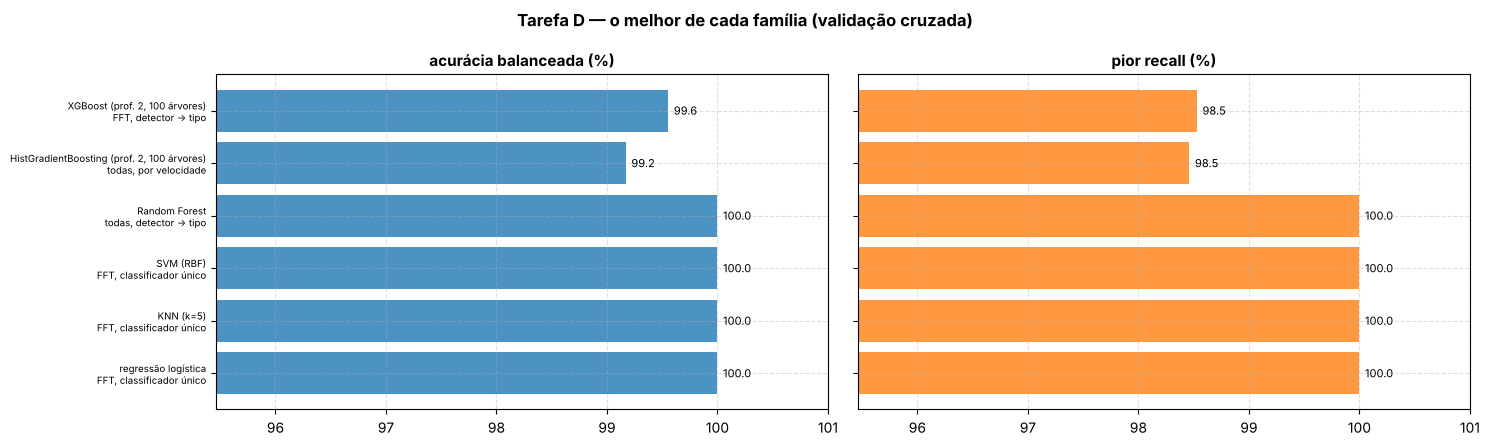

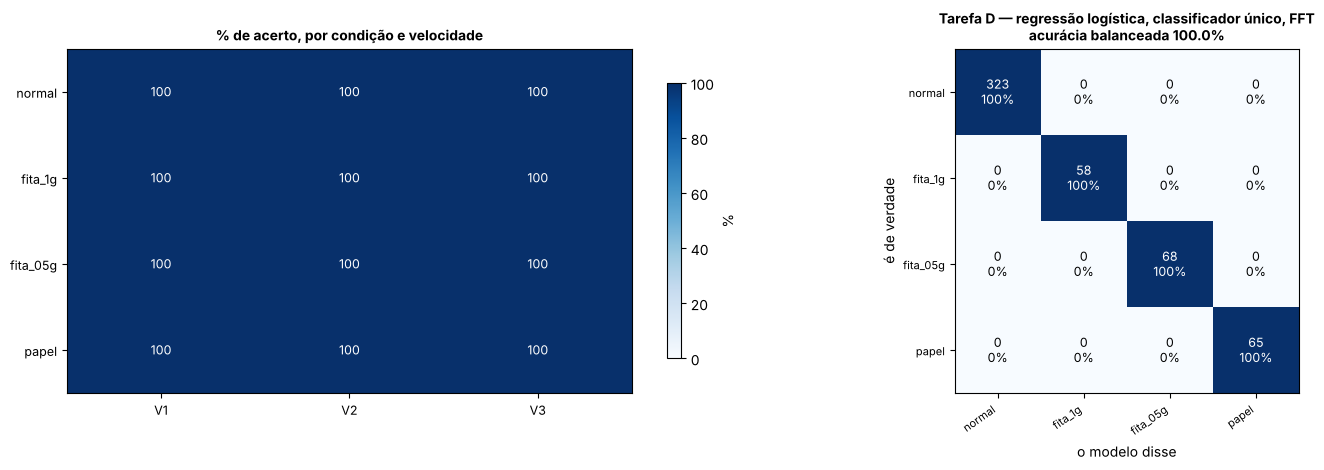

In [24]:
inicio = time.time()
tabela_d, previsoes_d = comparar_arquiteturas(dev, CONJUNTOS, folds)
print(f"({time.time() - inicio:.0f} s)")
escolha_d = melhor_real(tabela_d)
previsto_d = previsoes_d[(escolha_d["modelo"], escolha_d["features"], escolha_d["arquitetura"])]
mostrar_comparacao(tabela_d, CONJUNTOS, "Tarefa D (condição)", escolha=escolha_d)
print(f"Escolhido pela regra: {escolha_d['modelo']}, {escolha_d['arquitetura']}, features '{escolha_d['features']}'")

linhas_arquitetura = []
for arquitetura in ARQUITETURAS:
    e = aplicar_regra_de_escolha(sem_referencias(tabela_d)[sem_referencias(tabela_d).index.get_level_values("arquitetura") == arquitetura])
    linhas_arquitetura.append({"arquitetura": f"{arquitetura}\n({e['modelo']}, {e['features']})",
                               "acurácia balanceada (%)": e["acurácia balanceada (%)"], "pior recall (%)": e["pior recall (%)"]})
plotar_barras(pd.DataFrame(linhas_arquitetura).set_index("arquitetura"), "Tarefa D — o melhor de cada arquitetura (validação cruzada)",
              limites_y=(80, 102), formato="{:.1f}")
plotar_familias(tabela_d, "Tarefa D")
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
plotar_mapa_simples(tabela_por_condicao(dev, previsto_d == dev["rotulo_condicao"].to_numpy(), ORDEM_CONDICOES),
                    "% de acerto, por condição e velocidade", ax=axs[0], cmap="Blues")
plotar_matriz(dev["rotulo_condicao"], previsto_d, ORDEM_CONDICOES,
              f"Tarefa D — {escolha_d['modelo']}, {escolha_d['arquitetura']}, {escolha_d['features']}\n"
              f"acurácia balanceada {escolha_d['acurácia balanceada (%)']:.1f}%", ax=axs[1])
plt.tight_layout()
plt.show()

### Conclusões do Passo 11

* **Escolhido: regressão logística, classificador único, com FFT: 100%.** As três arquiteturas fazem 100% com regressão logística e FFT (barras). A regra fica com a mais simples: um modelo só.
* **Com FFT, regressão logística, KNN e SVM fazem 100%** nas três arquiteturas, ou quase.
* **Os modelos de árvores ficam atrás:** o melhor XGBoost faz 99,6% (FFT, detector → tipo) e o melhor HistGradientBoosting, 99,2%. Com **todas** as features e o classificador único, o XGBoost cai para 97,3% a 97,7%. Esse caso é investigado no Passo 12.6.
* **A escolha da arquitetura para a API** pode seguir o critério de engenharia (modularidade), já que as três empatam.

## Passo 12 — Testes anti-ilusão

**O que buscamos:** resultados altos pedem desconfiança. Seis testes, todos **só com o conjunto de desenvolvimento** (o trancado continua fechado):

| Teste | Pergunta |
| --- | --- |
| 12.1 Rótulos embaralhados | O procedimento "acerta" mesmo quando os rótulos não significam nada? |
| 12.2 Lote normal deixado de fora | O detector reconhece como normal um **momento da sessão que ele nunca viu**? |
| 12.3 Falha deixada de fora | O detector acusa uma **falha que ele nunca viu**? |
| 12.4 Stump e importâncias | O que os modelos estão olhando? |
| 12.5 Sensibilidade | O resultado depende das linhas elétricas (120 e 240 Hz) ou da rotação (`f1x_hz`)? |
| 12.6 O XGBoost | Ele ficou atrás por causa da profundidade, da taxa de aprendizado ou do número de árvores? |

Na coleta anterior, o teste do aquecimento era a divisão cronológica (treinar no começo e testar no fim de cada gravação). Aqui o Notebook 03 mostrou que **não há tendência dentro das gravações**: o aquecimento está **entre** os lotes. Por isso o teste equivalente é o 12.2.

### 12.1 — Rótulos embaralhados

Trocamos os rótulos **entre os blocos** ao acaso (cada bloco inteiro recebe o rótulo de outro) e repetimos a validação cruzada `N_EMBARALHAMENTOS` vezes. Com rótulos sem sentido, a acurácia balanceada deve cair para perto do **acaso** (100% dividido pelo número de classes). Se ficar alta, existe vazamento no procedimento.

In [25]:
def embaralhar_por_bloco(dados, coluna_rotulo, gerador):
    """Troca os rótulos entre os blocos: cada bloco inteiro recebe o rótulo de outro bloco, ao acaso."""
    chave = dados["base"] + "|" + dados["bloco"].astype(str)
    rotulo_por_bloco = dados.groupby(chave)[coluna_rotulo].first()
    novo = pd.Series(gerador.permutation(rotulo_por_bloco.to_numpy()), index=rotulo_por_bloco.index)
    copia = dados.copy()
    copia[coluna_rotulo] = chave.map(novo).to_numpy()
    return copia


def testar_rotulos_embaralhados(dados, colunas, fabrica_modelo, folds, coluna_rotulo, n=N_EMBARALHAMENTOS):
    """Acurácia balanceada real e com rótulos embaralhados por bloco; p-valor do teste de permutação."""
    gerador = np.random.default_rng(SEMENTE)
    real = 100 * balanced_accuracy_score(dados[coluna_rotulo], validar(fabrica_modelo, dados, colunas, coluna_rotulo, folds))
    embaralhados = []
    for _ in range(n):
        falso = embaralhar_por_bloco(dados, coluna_rotulo, gerador)
        embaralhados.append(100 * balanced_accuracy_score(falso[coluna_rotulo], validar(fabrica_modelo, falso, colunas, coluna_rotulo, folds)))
    return real, np.array(embaralhados), (1 + sum(e >= real for e in embaralhados)) / (n + 1)

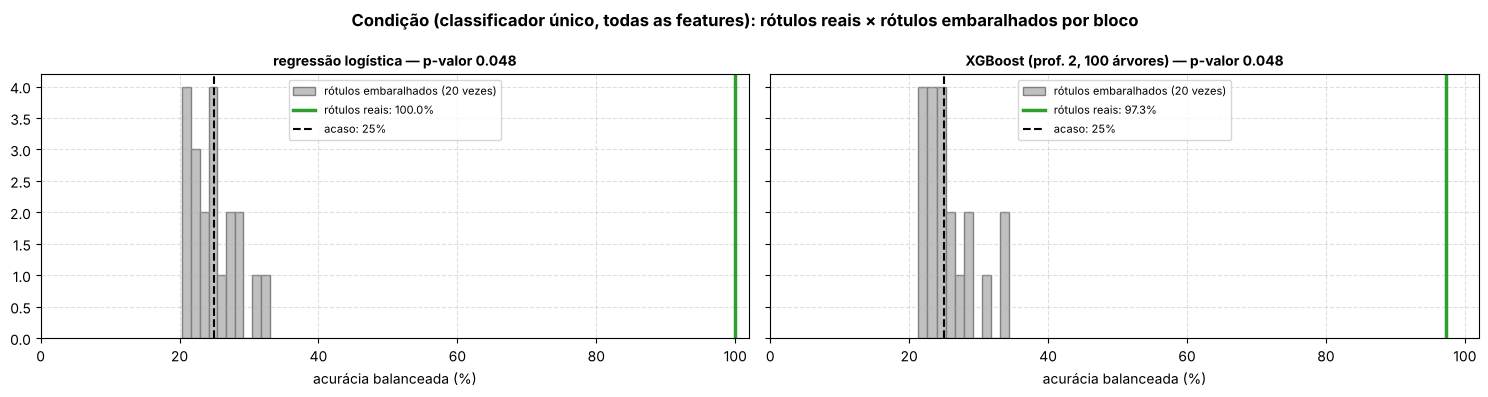

In [26]:
MODELOS_EMBARALHADOS = ["regressão logística", f"XGBoost (prof. {GRADE_PROFUNDIDADE[0]}, {GRADE_ARVORES[0]} árvores)"]
fig, axs = plt.subplots(1, len(MODELOS_EMBARALHADOS), figsize=(7.5 * len(MODELOS_EMBARALHADOS), 4), sharey=True)
for ax, nome_modelo in zip(np.atleast_1d(axs), MODELOS_EMBARALHADOS):
    real, embaralhados, p_valor = testar_rotulos_embaralhados(
        dev, COLUNAS_TODAS, lambda: criar_pipeline(MODELOS[nome_modelo](), COLUNAS_TODAS), folds, "rotulo_condicao")
    ax.hist(embaralhados, bins=10, color="silver", edgecolor="gray", label=f"rótulos embaralhados ({len(embaralhados)} vezes)")
    ax.axvline(real, color="tab:green", linewidth=2.5, label=f"rótulos reais: {real:.1f}%")
    ax.axvline(100 / len(ORDEM_CONDICOES), color="black", linestyle="--", label=f"acaso: {100 / len(ORDEM_CONDICOES):.0f}%")
    ax.set_xlim(0, 102)
    ax.set_xlabel("acurácia balanceada (%)")
    ax.legend(fontsize=8, loc="upper center")
    ax.set_title(f"{nome_modelo} — p-valor {p_valor:.3f}", fontsize=10, fontweight="bold")
fig.suptitle("Condição (classificador único, todas as features): rótulos reais × rótulos embaralhados por bloco", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### 12.2 — Lote normal deixado de fora: o detector aguenta um momento da sessão que não viu?

**O que buscamos:** o teste mais importante para o uso real. Tiramos **um lote inteiro de normal** do treino (as três velocidades), treinamos o detector escolhido com todo o resto e medimos quantas janelas desse lote ele acusa. É falso alarme num **estado do motor que o modelo nunca viu**.

* **Perto de 0%:** o detector aprendeu o que é normal de um jeito que vale para outros momentos.
* **Alto:** o detector só reconhece os momentos que viu. Fora desta sessão, ele tende a dar falso alarme.

Usamos só as janelas de desenvolvimento do lote (o trancado continua fechado).

**Com e sem o calço no treino:** a última tabela repete o teste com o calço e sem o calço entre as anomalias de treino. O calço foi gravado entre N1 e N2. Se ensinar o calço ao detector fizer subir o falso alarme justamente nesses lotes quando eles ficam de fora, o detector está confundindo "calço" com "começo da sessão".

In [27]:
def deixar_gravacao_de_fora(dados, gravacao, escolha):
    """Treina o detector escolhido sem a gravação e devolve a % das janelas dela chamadas de anomalia, por velocidade."""
    colunas = CONJUNTOS_TODOS[escolha["features"]]
    fora = (dados["gravacao"] == gravacao).to_numpy()
    modelo = criar_pipeline(MODELOS[escolha["modelo"]](), colunas).fit(dados.loc[~fora, colunas], dados.loc[~fora, "rotulo_binario"])
    acusada = pd.Series(modelo.predict(dados.loc[fora, colunas]) == NOME_ANOMALIA)
    return 100 * acusada.groupby(dados.loc[fora, "rotulo_velocidade"].to_numpy()).mean()

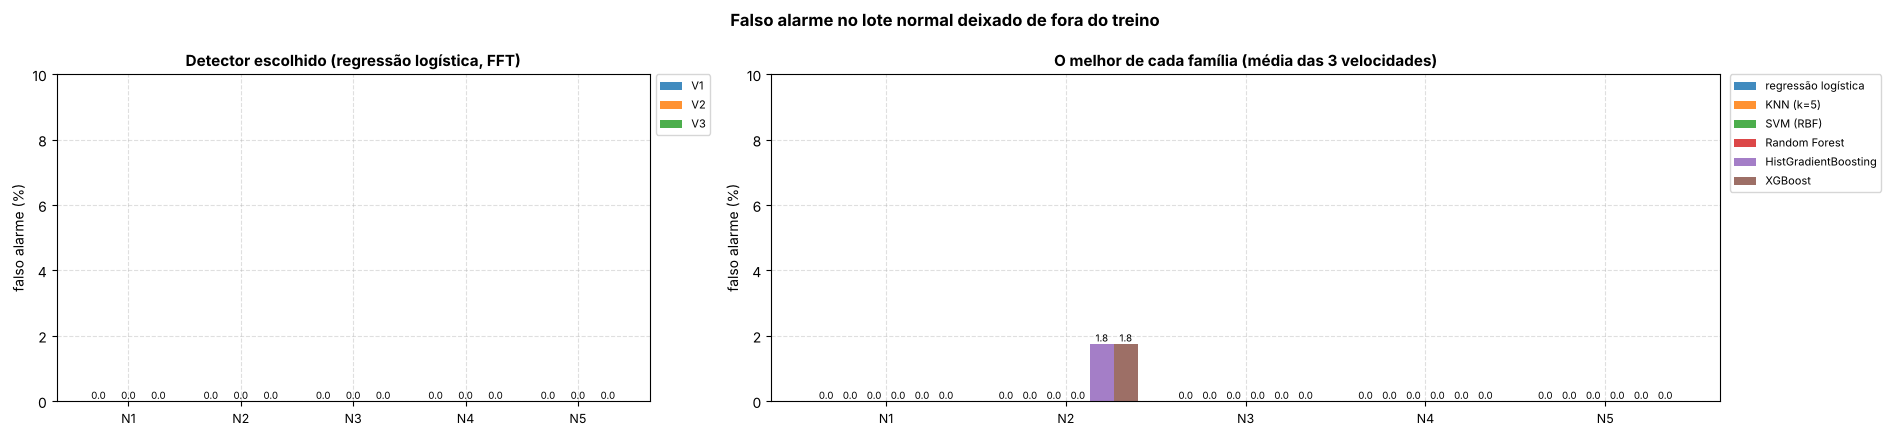

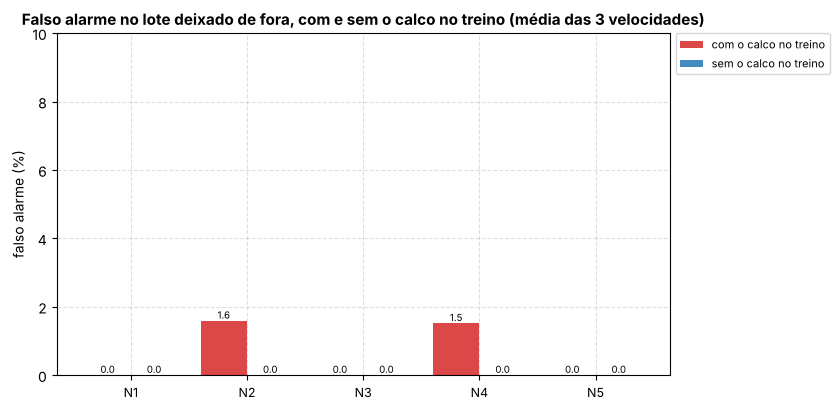

In [28]:
lote_de_fora = pd.DataFrame({lote: deixar_gravacao_de_fora(dev, lote, escolha_b) for lote in GRAVACOES_NORMAIS}).T
familias_b = melhores_por_familia(tabela_b)
lote_de_fora_familias = pd.DataFrame({
    familia: {lote: deixar_gravacao_de_fora(dev, lote, {"modelo": linha["melhor combinação"], "features": linha["features"]}).mean()
              for lote in GRAVACOES_NORMAIS}
    for familia, linha in familias_b.iterrows()})
fig, axs = plt.subplots(1, 2, figsize=(19, 4.4), gridspec_kw={"width_ratios": [1, 1.6]})
plotar_barras(lote_de_fora, f"Detector escolhido ({escolha_b['modelo']}, {escolha_b['features']})", rotulo_y="falso alarme (%)",
              ax=axs[0], limites_y=(0, 10), formato="{:.1f}", cores=["tab:blue", "tab:orange", "tab:green"])
plotar_barras(lote_de_fora_familias, "O melhor de cada família (média das 3 velocidades)", rotulo_y="falso alarme (%)",
              ax=axs[1], limites_y=(0, 10), formato="{:.1f}")
fig.suptitle("Falso alarme no lote normal deixado de fora do treino", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

sem_a_condicao = dev_completo[dev_completo["rotulo_condicao"] != CONDICAO_EM_AVALIACAO]
com_e_sem = pd.DataFrame({f"com o {CONDICAO_EM_AVALIACAO} no treino": pd.DataFrame({l: deixar_gravacao_de_fora(dev_completo, l, escolha_b) for l in GRAVACOES_NORMAIS}).T.mean(axis=1),
                          f"sem o {CONDICAO_EM_AVALIACAO} no treino": pd.DataFrame({l: deixar_gravacao_de_fora(sem_a_condicao, l, escolha_b) for l in GRAVACOES_NORMAIS}).T.mean(axis=1)})
plotar_barras(com_e_sem, f"Falso alarme no lote deixado de fora, com e sem o {CONDICAO_EM_AVALIACAO} no treino (média das 3 velocidades)",
              rotulo_y="falso alarme (%)", limites_y=(0, 10), formato="{:.1f}", cores=["tab:red", "tab:blue"])

### 12.3 — Falha deixada de fora: o detector acusa uma falha que nunca viu?

**O que buscamos:** o contrário do 12.2. Tiramos **uma falha inteira** do treino, treinamos o detector com o normal e as outras falhas, e medimos quantas janelas da falha retirada ele acusa.

Um classificador supervisionado aprende "normal" **contra as falhas que viu**. Ele não tem obrigação de acusar uma falha diferente: se ela não se parecer com nenhuma das conhecidas, pode passar por normal. Este teste mostra o tamanho desse limite, e é o motivo de existir o **Notebook 06** (um detector treinado só com o normal, que acusa tudo o que foge dele).

Para o calço, este teste também responde: **um detector que nunca viu o calço o acha estranho?**

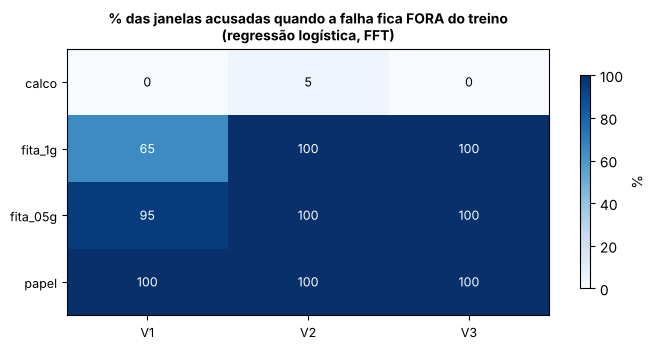

In [29]:
falha_de_fora = pd.DataFrame({falha: deixar_gravacao_de_fora(dev_completo, falha, escolha_b) for falha in ORDEM_FALHAS_TODAS}).T
plotar_mapa_simples(falha_de_fora, f"% das janelas acusadas quando a falha fica FORA do treino\n({escolha_b['modelo']}, {escolha_b['features']})", cmap="Blues")

### 12.4 — O que os modelos estão olhando? (stump e importâncias)

* **O stump** é a árvore de uma pergunta só. Mostramos a pergunta que ele escolhe para as Tarefas A, B e C e o quanto ela acerta sozinha.
* **As importâncias do Random Forest** mostram as 10 features mais usadas nas Tarefas B e C, com o tipo de cada uma.

In [30]:
def nomes_na_esteira(colunas):
    """A ordem das colunas depois da etapa de log (as sem log vão para o fim)."""
    return [c for c in colunas if c not in COLUNAS_SEM_LOG] + [c for c in colunas if c in COLUNAS_SEM_LOG]


def descrever_stump(dados, colunas, coluna_rotulo):
    """Treina o stump e devolve a pergunta que ele faz (feature e limite, na escala original)."""
    pipeline = criar_pipeline(MODELOS["referência: stump (1 pergunta)"](), colunas).fit(dados[colunas], dados[coluna_rotulo])
    arvore, scaler = pipeline.named_steps["modelo"], pipeline.named_steps["scaler"]
    indice = arvore.tree_.feature[0]
    feature = nomes_na_esteira(colunas)[indice]
    limite = arvore.tree_.threshold[0] * scaler.scale_[indice] + scaler.mean_[indice]
    return feature, (limite if feature in COLUNAS_SEM_LOG else np.exp(limite))


def importancias_random_forest(dados, colunas, coluna_rotulo, n=10):
    """As n features mais importantes de um Random Forest treinado em todo o conjunto."""
    pipeline = criar_pipeline(MODELOS["Random Forest"](), colunas).fit(dados[colunas], dados[coluna_rotulo])
    importancias = pd.Series(pipeline.named_steps["modelo"].feature_importances_, index=nomes_na_esteira(colunas))
    return importancias.sort_values(ascending=False).head(n)

,pergunta do stump,acurácia balanceada na validação (%)
tarefa,,
A: velocidade,f1x_hz > 21.6?,64.4
B: normal x anomalia,fft_225_235Hz_z > 0.0359?,88.5
C: qual falha,fft_225_235Hz_z > 0.1?,58.7


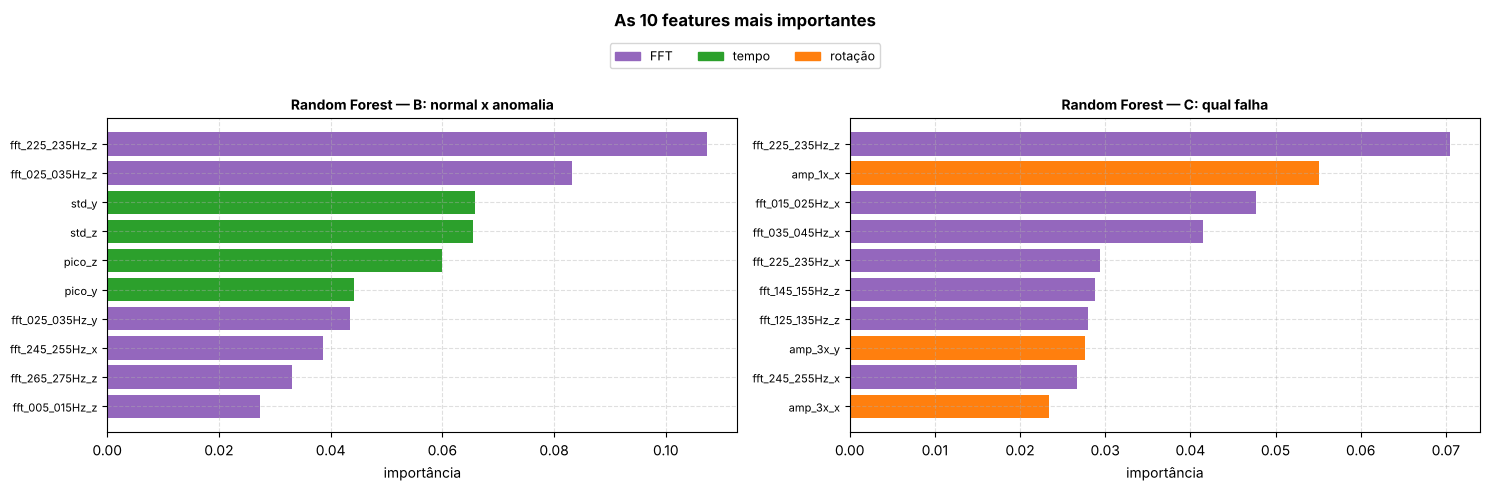

In [31]:
linhas = []
for tarefa, dados, coluna, tabela in (("A: velocidade", dev, "rotulo_velocidade", tabela_a),
                                      ("B: normal x anomalia", dev, "rotulo_binario", tabela_b),
                                      ("C: qual falha", dev_falhas, "rotulo_condicao", tabela_c)):
    feature, limite = descrever_stump(dados, COLUNAS_TODAS, coluna)
    linhas.append({"tarefa": tarefa, "pergunta do stump": f"{feature} > {limite:.3g}?",
                   "acurácia balanceada na validação (%)": tabela.loc[("todas", "referência: stump (1 pergunta)"), "acurácia balanceada (%)"]})
display(pd.DataFrame(linhas).set_index("tarefa").round(1))

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (tarefa, dados, coluna) in zip(axs, (("B: normal x anomalia", dev, "rotulo_binario"), ("C: qual falha", dev_falhas, "rotulo_condicao"))):
    importancias = importancias_random_forest(dados, COLUNAS_TODAS, coluna)
    cores = ["tab:purple" if f.startswith("fft_") else ("tab:orange" if f.startswith(("amp_", "f1x")) else "tab:green") for f in importancias.index]
    ax.barh(range(len(importancias)), importancias, color=cores)
    ax.set_yticks(range(len(importancias)))
    ax.set_yticklabels(importancias.index, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("importância")
    ax.set_title(f"Random Forest — {tarefa}", fontsize=10, fontweight="bold")
fig.legend(handles=[Patch(color="tab:purple", label="FFT"), Patch(color="tab:green", label="tempo"), Patch(color="tab:orange", label="rotação")],
           loc="upper center", ncol=3, fontsize=9, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("As 10 features mais importantes", fontsize=12, fontweight="bold", y=1.08)
plt.tight_layout()
plt.show()

### 12.5 — Sensibilidade: sem as linhas elétricas e sem a rotação

**O que buscamos:** duas perguntas que a banca pode fazer.

* **As linhas de 120 e 240 Hz** são elétricas (confirmado pelo orientador), não mecânicas. O resultado depende delas? Refazemos a validação dos modelos escolhidos **sem as 6 features** das faixas de 115–125 Hz e 235–245 Hz.
* **A rotação (`f1x_hz`)** mistura o efeito da falha com o aquecimento (Notebook 02). O resultado depende dela? Refazemos sem ela.

Se a acurácia balanceada quase não mudar, o modelo não depende dessas features.

In [32]:
def validar_escolha(escolha, dados, folds, coluna_treino, coluna_real, classes, tirar=()):
    """Valida de novo a combinação escolhida, opcionalmente sem algumas features. Devolve as métricas."""
    colunas = [c for c in CONJUNTOS_TODOS[escolha["features"]] if c not in tirar]
    fabrica = MODELOS[escolha["modelo"]]
    if isinstance(escolha.get("arquitetura"), str):
        construir = lambda: ARQUITETURAS[escolha["arquitetura"]](fabrica, colunas)
    else:
        construir = lambda: criar_pipeline(fabrica(), colunas)
    return metricas(dados[coluna_real], validar(construir, dados, colunas, coluna_treino, folds), classes)

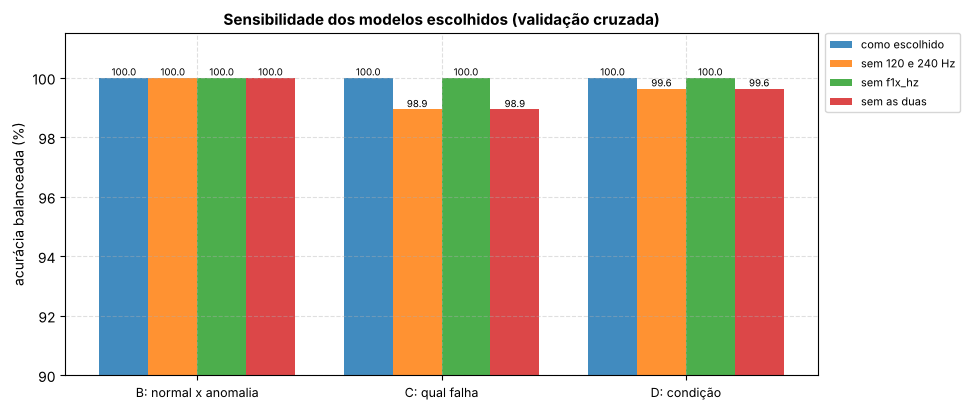

In [33]:
TAREFAS_SENSIBILIDADE = {
    "B: normal x anomalia": (escolha_b, dev, folds, "rotulo_binario", "rotulo_binario", CLASSES_BINARIAS),
    "C: qual falha": (escolha_c, dev_falhas, folds_falhas, "rotulo_condicao", "rotulo_condicao", ORDEM_FALHAS),
    "D: condição": (escolha_d, dev, folds, "rotulo_classe", "rotulo_condicao", ORDEM_CONDICOES),
}
linhas = []
for tarefa, (escolha, dados, folds_tarefa, coluna_treino, coluna_real, classes) in TAREFAS_SENSIBILIDADE.items():
    for nome, tirar in (("como escolhido", ()), ("sem 120 e 240 Hz", COLUNAS_ELETRICAS), ("sem f1x_hz", ["f1x_hz"]),
                        ("sem as duas", COLUNAS_ELETRICAS + ["f1x_hz"])):
        m = validar_escolha(escolha, dados, folds_tarefa, coluna_treino, coluna_real, classes, tirar)
        linhas.append({"tarefa": tarefa, "versão": nome, "acurácia balanceada (%)": m["acurácia balanceada (%)"], "pior recall (%)": m["pior recall (%)"]})
sensibilidade = pd.DataFrame(linhas).set_index(["tarefa", "versão"])
plotar_barras(sensibilidade["acurácia balanceada (%)"].unstack("versão")[["como escolhido", "sem 120 e 240 Hz", "sem f1x_hz", "sem as duas"]],
              "Sensibilidade dos modelos escolhidos (validação cruzada)", rotulo_y="acurácia balanceada (%)", limites_y=(90, 101.5), formato="{:.1f}")

### 12.6 — Por que o XGBoost ficou atrás? Profundidade, taxa de aprendizado ou outra coisa?

**A pergunta:** na Tarefa D, o XGBoost da grade fixada antes (profundidade 2 ou 4, 100 ou 300 árvores, taxa de aprendizado 0,1) fica cerca de 2 pontos abaixo da regressão logística. Será que a grade era fraca demais?

**O que fazemos, em três partes:**

1. **Grade ampliada:** profundidade de **2 a 8**, taxa de aprendizado de **0,03, 0,1 e 0,3** e **100, 300 ou 1.000** árvores (36 combinações), na Tarefa D com o classificador único e todas as features, nos mesmos folds.
2. **Onde ele erra:** quais janelas o XGBoost de referência erra e a regressão logística acerta, desenhadas ao longo da gravação.
3. **Por que erra:** para cada janela da validação, contamos em quantas das 109 features ela fica **fora da faixa** (do mínimo ao máximo) que a **própria classe** tinha no treino daquela rodada.

**A ideia por trás da parte 3:** uma árvore de decisão divide as features em faixas ("`std_y` maior que 2,3?") e dá a cada faixa uma resposta. **Fora da faixa que viu no treino, ela repete a resposta da faixa mais próxima**: ela não extrapola. A regressão logística traça uma fronteira reta e continua valendo além dos dados de treino. Se os erros do XGBoost forem janelas "fora da faixa", o problema não é a grade: é o tipo de modelo diante de poucos dados.

**Importante:** esta grade foi montada **depois** de ver os resultados. Ela serve para **explicar**, e **não muda a escolha** do Passo 13. Escolher o modelo por ela, depois de olhar, deixaria a validação otimista.

In [34]:
def avaliar_grade_xgboost(dados, colunas, coluna_rotulo, classes, folds):
    """Valida o XGBoost em todas as combinações da grade ampliada (classificador único). Devolve uma linha por combinação."""
    linhas = []
    for profundidade in GRADE_AMPLIADA_PROFUNDIDADE:
        for taxa in GRADE_AMPLIADA_TAXA:
            for arvores in GRADE_AMPLIADA_ARVORES:
                fabrica = lambda p=profundidade, t=taxa, n=arvores: ComRotulosNumericos(XGBClassifier(
                    max_depth=p, n_estimators=n, learning_rate=t, subsample=SUBAMOSTRA, colsample_bytree=SUBAMOSTRA,
                    random_state=SEMENTE, n_jobs=-1))
                previsto = validar(lambda: criar_pipeline(fabrica(), colunas), dados, colunas, coluna_rotulo, folds)
                linhas.append({"profundidade": profundidade, "taxa de aprendizado": taxa, "árvores": arvores,
                               **metricas(dados[coluna_rotulo], previsto, classes)})
    return pd.DataFrame(linhas)


def plotar_grade_xgboost(grade, referencia, nome_referencia, coluna="acurácia balanceada (%)"):
    """Um mapa por número de árvores: profundidade (linhas) x taxa de aprendizado (colunas). O título traz a referência."""
    fig, axs = plt.subplots(1, len(GRADE_AMPLIADA_ARVORES), figsize=(5.2 * len(GRADE_AMPLIADA_ARVORES), 3.8), sharey=True)
    minimo = min(grade[coluna].min(), referencia) - 1
    for ax, arvores in zip(axs, GRADE_AMPLIADA_ARVORES):
        mapa = grade[grade["árvores"] == arvores].pivot(index="profundidade", columns="taxa de aprendizado", values=coluna)
        imagem = ax.imshow(mapa.to_numpy(), cmap="RdYlGn", vmin=minimo, vmax=100, aspect="auto")
        for i in range(mapa.shape[0]):
            for j in range(mapa.shape[1]):
                ax.text(j, i, f"{mapa.iat[i, j]:.1f}", ha="center", va="center", fontsize=10)
        ax.set_xticks(range(mapa.shape[1]))
        ax.set_xticklabels(mapa.columns)
        ax.set_yticks(range(mapa.shape[0]))
        ax.set_yticklabels(mapa.index)
        ax.set_xlabel("taxa de aprendizado")
        ax.grid(False)
        ax.set_title(f"{arvores} árvores", fontsize=11, fontweight="bold")
    axs[0].set_ylabel("profundidade máxima")
    fig.colorbar(imagem, ax=axs.tolist(), shrink=0.8, label=coluna)
    fig.suptitle(f"XGBoost na grade ampliada — {coluna} (Tarefa D, classificador único, todas as features)\n"
                 f"referência: {nome_referencia} = {referencia:.1f}%", fontsize=12, fontweight="bold", y=1.06)
    plt.show()

(115 s)


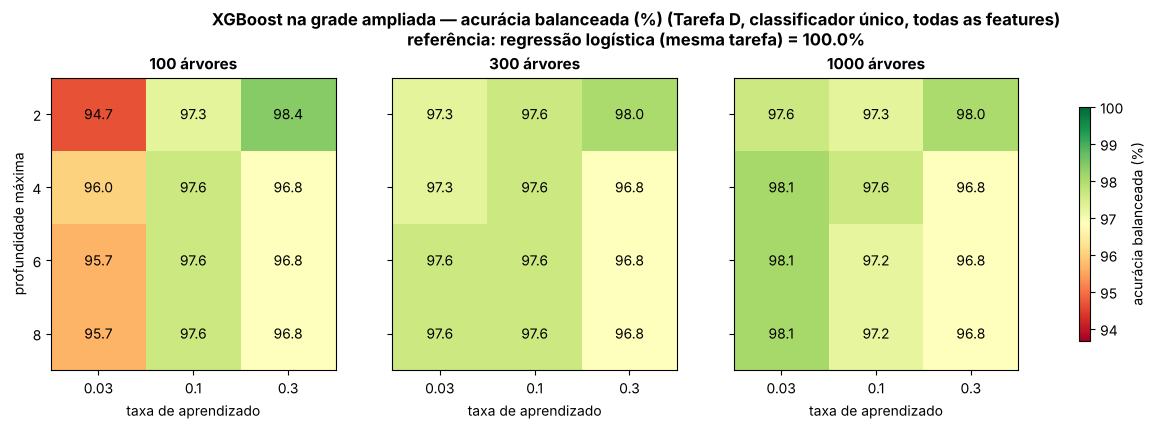

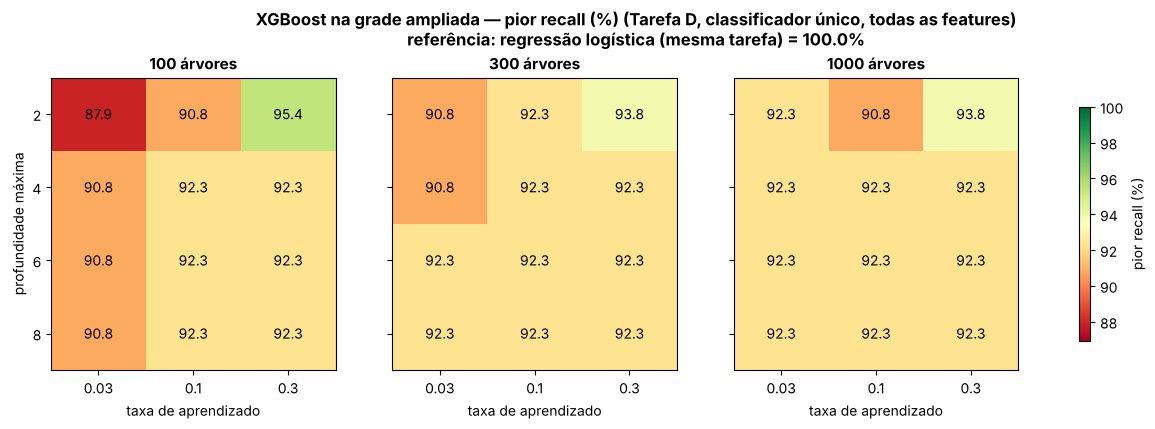

Melhor combinação da grade ampliada: profundidade 2, taxa 0.3, 100 árvores -> 98.4% (regressão logística: 100.0%). Faixa da grade: 94.7% a 98.4%.


In [35]:
inicio = time.time()
grade_xgboost = avaliar_grade_xgboost(dev, COLUNAS_TODAS, "rotulo_condicao", ORDEM_CONDICOES, folds)
print(f"({time.time() - inicio:.0f} s)")
referencia_lr = tabela_d.loc[("todas", "regressão logística", "classificador único")]
plotar_grade_xgboost(grade_xgboost, referencia_lr["acurácia balanceada (%)"], "regressão logística (mesma tarefa)")
plotar_grade_xgboost(grade_xgboost, referencia_lr["pior recall (%)"], "regressão logística (mesma tarefa)", coluna="pior recall (%)")
melhor_grade = grade_xgboost.sort_values(["acurácia balanceada (%)", "pior recall (%)"], ascending=False).iloc[0]
print(f"Melhor combinação da grade ampliada: profundidade {melhor_grade['profundidade']:.0f}, taxa {melhor_grade['taxa de aprendizado']}, "
      f"{melhor_grade['árvores']:.0f} árvores -> {melhor_grade['acurácia balanceada (%)']:.1f}% "
      f"(regressão logística: {referencia_lr['acurácia balanceada (%)']:.1f}%). "
      f"Faixa da grade: {grade_xgboost['acurácia balanceada (%)'].min():.1f}% a {grade_xgboost['acurácia balanceada (%)'].max():.1f}%.")

### Conclusões do Passo 12.6, parte 1 (grade ampliada)

* **Nenhuma combinação alcança a regressão logística.** As 36 combinações ficam entre **94,7% e 98,4%** de acurácia balanceada, contra 100% da regressão logística na mesma tarefa. O pior recall fica entre 87,9% e 95,4%, quase sempre em 92,3%.
* **A profundidade não é o problema.** Nas linhas de profundidade 4, 6 e 8, os números são praticamente iguais. A melhor combinação usa profundidade **2**.
* **A taxa de aprendizado só pesa quando ela é baixa e há poucas árvores.** Com taxa 0,03 e 100 árvores, o XGBoost ainda não aprendeu o bastante (94,7% a 96,0%). Com 300 ou 1.000 árvores, isso se corrige, mas o resultado **para em cerca de 98%**.
* **Leitura:** há um teto de cerca de 98% que não depende dos hiperparâmetros. Se fosse falta de ajuste, ele subiria com mais árvores ou mais profundidade, e não sobe. A parte 2 mostra o que causa esse teto.

#### Onde o XGBoost erra e por quê

**Os gráficos:**

* **Esquerda:** a feature `FEATURE_EXEMPLO_EXTRAPOLACAO` ao longo da gravação em que o XGBoost mais erra, com um **X vermelho** em cada janela que ele errou (na validação cruzada). A faixa cinza é o trecho dessa gravação que ficou no **trancado** e não entra na validação.
* **Direita:** para cada janela da validação, em quantas features ela ficou fora da faixa que a própria classe tinha no treino da rodada. **Acertos à esquerda, erros à direita.** Se os erros ficarem bem mais "fora da faixa" que os acertos, a causa é a falta de extrapolação das árvores.

In [36]:
def contar_fora_da_faixa_da_classe(dados, folds, colunas, coluna_classe="rotulo_condicao"):
    """Para cada janela da validação: em quantas features ela fica fora da faixa (mínimo a máximo) da sua classe no treino da rodada."""
    fora = np.zeros(len(dados), dtype=int)
    for treino, validacao, _ in folds:
        treino_dados = dados.iloc[treino]
        for classe, grupo in dados.iloc[validacao].groupby(coluna_classe):
            referencia = treino_dados[treino_dados[coluna_classe] == classe][colunas]
            fora_classe = ((grupo[colunas] < referencia.min()) | (grupo[colunas] > referencia.max())).sum(axis=1)
            fora[dados.index.get_indexer(grupo.index)] = fora_classe.to_numpy()
    return fora


def plotar_onde_o_xgboost_erra(dados, previsoes, feature, fora, nome_xgboost, nome_simples):
    """Esquerda: a feature ao longo da gravação com mais erros do XGBoost, com os erros marcados.
    Direita: features fora da faixa da própria classe, em acertos e erros de cada modelo."""
    reais = dados["rotulo_condicao"].to_numpy()
    erros_xgb = previsoes[nome_xgboost] != reais
    pior = dados[erros_xgb].groupby("base").size().idxmax() if erros_xgb.any() else dados["base"].iloc[0]
    fig, axs = plt.subplots(1, 2, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
    completa = features[features["base"] == pior]
    axs[0].plot(completa["janela"] * JANELA_S, completa[feature], color="lightgray", linewidth=1)
    trancadas = completa[completa["papel"] != "desenvolvimento"]
    axs[0].scatter(trancadas["janela"] * JANELA_S, trancadas[feature], color="silver", s=25, label="trancado ou guarda (fora da validação)")
    da_base = (dados["base"] == pior).to_numpy()
    axs[0].scatter(dados.loc[da_base, "janela"] * JANELA_S, dados.loc[da_base, feature], color="tab:blue", s=25, label="validação")
    marcar = da_base & erros_xgb
    axs[0].scatter(dados.loc[marcar, "janela"] * JANELA_S, dados.loc[marcar, feature], color="red", marker="x", s=110, linewidths=2.5,
                   label=f"erro do {nome_xgboost} ({int(marcar.sum())})")
    marcar_simples = da_base & (previsoes[nome_simples] != reais)
    if marcar_simples.any():
        axs[0].scatter(dados.loc[marcar_simples, "janela"] * JANELA_S, dados.loc[marcar_simples, feature], facecolor="none", edgecolor="black",
                       s=150, linewidths=1.5, label=f"erro da {nome_simples} ({int(marcar_simples.sum())})")
    axs[0].set_xlabel("tempo dentro da gravação (s)")
    axs[0].set_ylabel(feature)
    axs[0].legend(fontsize=8)
    axs[0].set_title(f"{pior}: onde o XGBoost erra", fontsize=11, fontweight="bold")
    grupos, rotulos = [], []
    for nome in (nome_simples, nome_xgboost):
        acertou = previsoes[nome] == reais
        grupos += [fora[acertou], fora[~acertou]]
        curto = nome.replace(" (", "\n(")
        rotulos += [f"{curto}\nacertos ({int(acertou.sum())})", f"{curto}\nerros ({int((~acertou).sum())})"]
    caixa = axs[1].boxplot([g if len(g) else [np.nan] for g in grupos], patch_artist=True, widths=0.6)
    for parte, cor in zip(caixa["boxes"], ["tab:green", "tab:red", "tab:green", "tab:red"]):
        parte.set_facecolor(cor)
        parte.set_alpha(0.5)
    for k, g in enumerate(grupos, start=1):
        if len(g):
            axs[1].scatter(np.full(len(g), k) + np.random.default_rng(0).uniform(-0.15, 0.15, len(g)), g, s=8, color="black", alpha=0.4)
    axs[1].set_xticks(range(1, len(rotulos) + 1))
    axs[1].set_xticklabels(rotulos, fontsize=8)
    axs[1].set_ylabel(f"features fora da faixa da própria classe (de {len(COLUNAS_TODAS)})")
    axs[1].set_title("Janelas fora da faixa do treino", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()

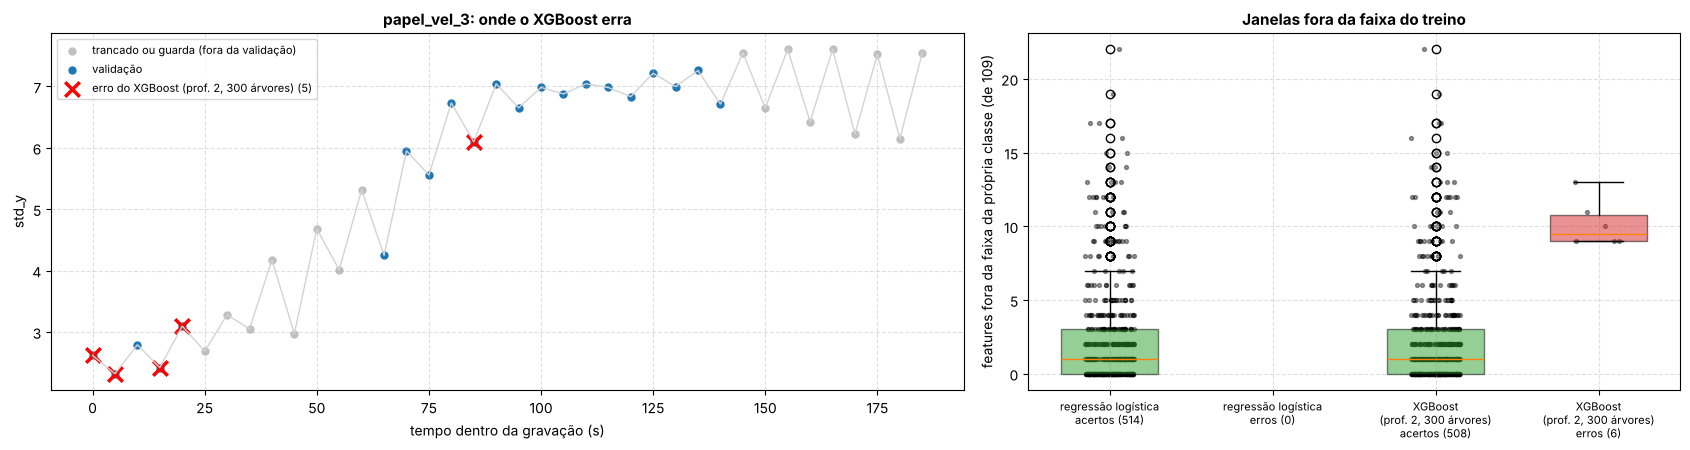

Erros do XGBoost (prof. 2, 300 árvores) (todas as features, classificador único): 6 de 514 janelas
gravação velocidade  janela o XGBoost disse  features fora da faixa
 fita_1g         V1       1        fita_05g                      10
   papel         V3       0          normal                      11
   papel         V3       1          normal                       9
   papel         V3       3         fita_1g                      13
   papel         V3       4         fita_1g                       9
   papel         V3      17         fita_1g                       9
Features fora da faixa da própria classe — mediana nos acertos: 1; mediana nos erros: 10


In [37]:
NOME_SIMPLES = "regressão logística"
previsoes_xgb_estudo = {NOME_SIMPLES: previsoes_d[(NOME_SIMPLES, "todas", "classificador único")],
                        XGBOOST_REFERENCIA: previsoes_d[(XGBOOST_REFERENCIA, "todas", "classificador único")]}
fora_da_faixa = contar_fora_da_faixa_da_classe(dev, folds, COLUNAS_TODAS)
plotar_onde_o_xgboost_erra(dev, previsoes_xgb_estudo, FEATURE_EXEMPLO_EXTRAPOLACAO, fora_da_faixa, XGBOOST_REFERENCIA, NOME_SIMPLES)

erros = dev[previsoes_xgb_estudo[XGBOOST_REFERENCIA] != dev["rotulo_condicao"].to_numpy()]
print(f"Erros do {XGBOOST_REFERENCIA} (todas as features, classificador único): {len(erros)} de {len(dev)} janelas")
print(pd.DataFrame({"gravação": erros["gravacao"], "velocidade": erros["rotulo_velocidade"], "janela": erros["janela"],
                    "o XGBoost disse": previsoes_xgb_estudo[XGBOOST_REFERENCIA][dev.index.get_indexer(erros.index)],
                    "features fora da faixa": fora_da_faixa[dev.index.get_indexer(erros.index)]}).to_string(index=False))
acertos_xgb = previsoes_xgb_estudo[XGBOOST_REFERENCIA] == dev["rotulo_condicao"].to_numpy()
print(f"Features fora da faixa da própria classe — mediana nos acertos: {np.median(fora_da_faixa[acertos_xgb]):.0f}; "
      f"mediana nos erros: {np.median(fora_da_faixa[~acertos_xgb]) if (~acertos_xgb).any() else float('nan'):.0f}")

### Conclusões do Passo 12.6, parte 2 (onde e por que erra)

* **O XGBoost erra só 6 das 514 janelas**, e 5 delas estão na mesma gravação: o **papel na Vel 3**, nas janelas 0, 1, 3, 4 e 17. Ele chama as duas primeiras de normal e as outras de fita 1 g. A sexta é a janela 1 da fita 1 g na Vel 1, chamada de fita 0,5 g. **A regressão logística acerta todas.**
* **O gráfico da esquerda mostra a causa:** no papel da Vel 3, o `std_y` começa em cerca de 2,5 e só chega ao patamar de cerca de 7 depois de uns 100 s. As primeiras janelas têm a vibração de uma condição "mais calma". A janela 17 (85 s) está num vale da subida.
* **O gráfico da direita confirma a explicação:** nas janelas que o XGBoost acerta, a mediana é de **1 feature** fora da faixa da própria classe no treino; nas que ele erra, **de 9 a 13 (mediana 10)**. **Ele erra justamente as janelas que ficam fora do que viu no treino.**
* **Por que isso derruba o XGBoost e não a regressão logística:**
  * o bloco do começo do papel V3 ficou na validação, e o treino daquela rodada só tinha papel "já estabilizado";
  * uma árvore, fora da faixa que viu, devolve a resposta da faixa mais próxima. Um `std_y` baixo cai na faixa do normal ou das fitas;
  * a regressão logística usa as 90 faixas de FFT juntas, numa fronteira reta. O "jeito" espectral do papel aparece mesmo com a vibração ainda baixa.
* **Resposta à pergunta do grupo:** não é profundidade baixa, nem taxa de aprendizado baixa. **É pouco dado para um modelo de árvores:** uma gravação por falha e velocidade, e uma delas com um começo que não se repete no resto. Com mais gravações por condição, a diferença tende a diminuir. Hoje, o modelo linear generaliza melhor.
* **Um alerta para o protocolo de coleta:** o papel na Vel 3 levou cerca de 100 s para estabilizar. Vale conferir nas próximas coletas se as gravações começam depois de a condição estabilizar, ou registrar esse transitório de propósito.

### Conclusões do Passo 12

**12.1 — Rótulos embaralhados:** com os rótulos reais, a regressão logística faz 100% e o XGBoost faz 97,3%. Com os rótulos embaralhados por bloco, os dois caem para a região do **acaso (25%)**: as 20 repetições ficam entre cerca de 20% e 34%. p = 0,048, o menor possível com 20 repetições. **Não há vazamento no procedimento.**

**12.2 — Lote normal deixado de fora:** o detector escolhido tem **0% de falso alarme** em todos os lotes e velocidades, mesmo num lote que nunca viu. Entre os outros modelos, só o HistGradientBoosting e o XGBoost erram algo (1,8% no N2, na média das três velocidades). **Com o calço no treino**, aparecem 1,6% (N2) e 1,5% (N4), contra 0% sem ele. Dentro desta sessão, o efeito do calço é pequeno; fora dela, é grande (Passo 14.2).

**12.3 — Falha deixada de fora:**
* **Fitas e papel são acusados mesmo sem terem sido vistos no treino:** 95% a 100%, menos a fita 1 g na Vel 1 (65%).
* **O calço não:** um detector que nunca o viu o acusa em 0% a 5% das janelas. **O calço só é detectado quando o modelo é ensinado a procurar exatamente aquele padrão.**

**12.4 — O que os modelos olham:** o stump da Tarefa B pergunta por `fft_225_235Hz_z` e acerta 88,5%. Essa faixa também é a mais importante do Random Forest nas Tarefas B e C. Na B, ela vem seguida de `fft_025_035Hz_z`, `std_y`, `std_z` e `pico_z`. Na C, aparecem também as amplitudes da rotação (`amp_1x_x`, `amp_3x_y` e `amp_3x_x`).

**12.5 — Sensibilidade:**
* **Tirar as faixas de 120 e 240 Hz:** a Tarefa B continua em 100%, a C cai para 98,9% e a D para 99,6%. **O resultado não depende das linhas elétricas**, que ajudam só um pouco a separar as fitas.
* **Tirar `f1x_hz`** não muda nada: os modelos escolhidos para B, C e D usam só FFT.

## Passo 13 — Escolha final e abertura do teste trancado

**O que buscamos:** a prova final. As escolhas abaixo vêm **só da validação cruzada**, pela regra do Passo 6. Cada modelo escolhido é treinado com **todo o desenvolvimento** da sua tarefa e avaliado **uma vez** nas janelas trancadas, que não participaram de nenhuma escolha.

**Lembrete do limite:** o trancado vem das **mesmas gravações** do treino. Ele mede "o modelo acerta trechos que não viu destas gravações", e não "o modelo acerta outra gravação". Essa segunda pergunta é a do Passo 14.

**Lembrete desta versão:** o trancado já foi aberto uma vez (primeira versão, com o calço). As escolhas abaixo continuam vindo só da validação cruzada, sem olhar o trancado.

In [38]:
escolhas = {"A: velocidade": escolha_a, "B: normal x anomalia": escolha_b, "C: qual falha": escolha_c, "D: condição": escolha_d}
display(pd.DataFrame({tarefa: {"modelo": e["modelo"], "features": e["features"], "arquitetura": e.get("arquitetura", "—"),
                               "acurácia balanceada na validação (%)": round(e["acurácia balanceada (%)"], 2),
                               "pior recall na validação (%)": round(e["pior recall (%)"], 2)}
                      for tarefa, e in escolhas.items()}).T)

,modelo,features,arquitetura,acurácia balanceada na validação (%),pior recall na validação (%)
A: velocidade,regressão logística,só f1x_hz,—,100.0,100.0
B: normal x anomalia,regressão logística,FFT,—,100.0,100.0
C: qual falha,regressão logística,FFT,—,100.0,100.0
D: condição,regressão logística,FFT,classificador único,100.0,100.0


### 13.1 — Abrindo o teste trancado (uma vez só)

In [39]:
TAREFAS = {
    "A: velocidade": {"treino": dev, "teste": trancado, "rotulo_treino": "rotulo_velocidade", "rotulo_real": "rotulo_velocidade", "classes": ORDEM_VELOCIDADES},
    "B: normal x anomalia": {"treino": dev, "teste": trancado, "rotulo_treino": "rotulo_binario", "rotulo_real": "rotulo_binario", "classes": CLASSES_BINARIAS},
    "C: qual falha": {"treino": dev_falhas, "teste": trancado_falhas, "rotulo_treino": "rotulo_condicao", "rotulo_real": "rotulo_condicao", "classes": ORDEM_FALHAS},
    "D: condição": {"treino": dev, "teste": trancado, "rotulo_treino": "rotulo_classe", "rotulo_real": "rotulo_condicao", "classes": ORDEM_CONDICOES},
}


def treinar_escolha(escolha, tarefa):
    """Treina a combinação escolhida (esteira simples ou arquitetura da Tarefa D) com todo o desenvolvimento da tarefa."""
    colunas = CONJUNTOS_TODOS[escolha["features"]]
    fabrica = MODELOS[escolha["modelo"]]
    modelo = ARQUITETURAS[escolha["arquitetura"]](fabrica, colunas) if isinstance(escolha.get("arquitetura"), str) else criar_pipeline(fabrica(), colunas)
    return modelo.fit(tarefa["treino"][colunas], tarefa["treino"][tarefa["rotulo_treino"]])

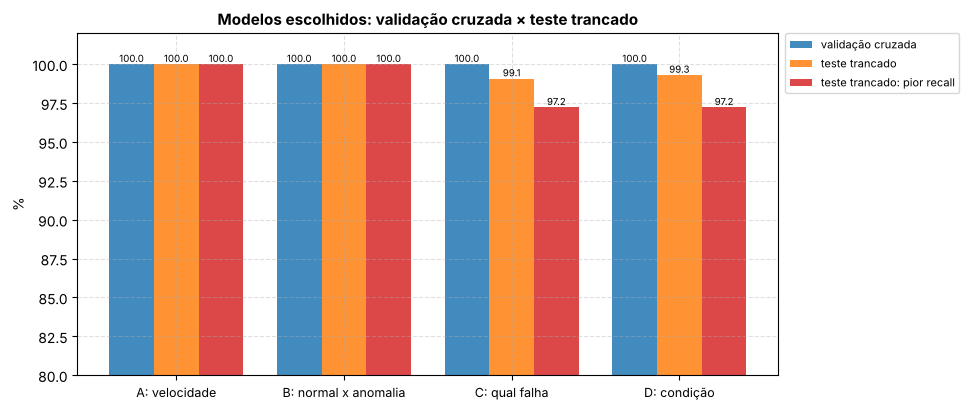

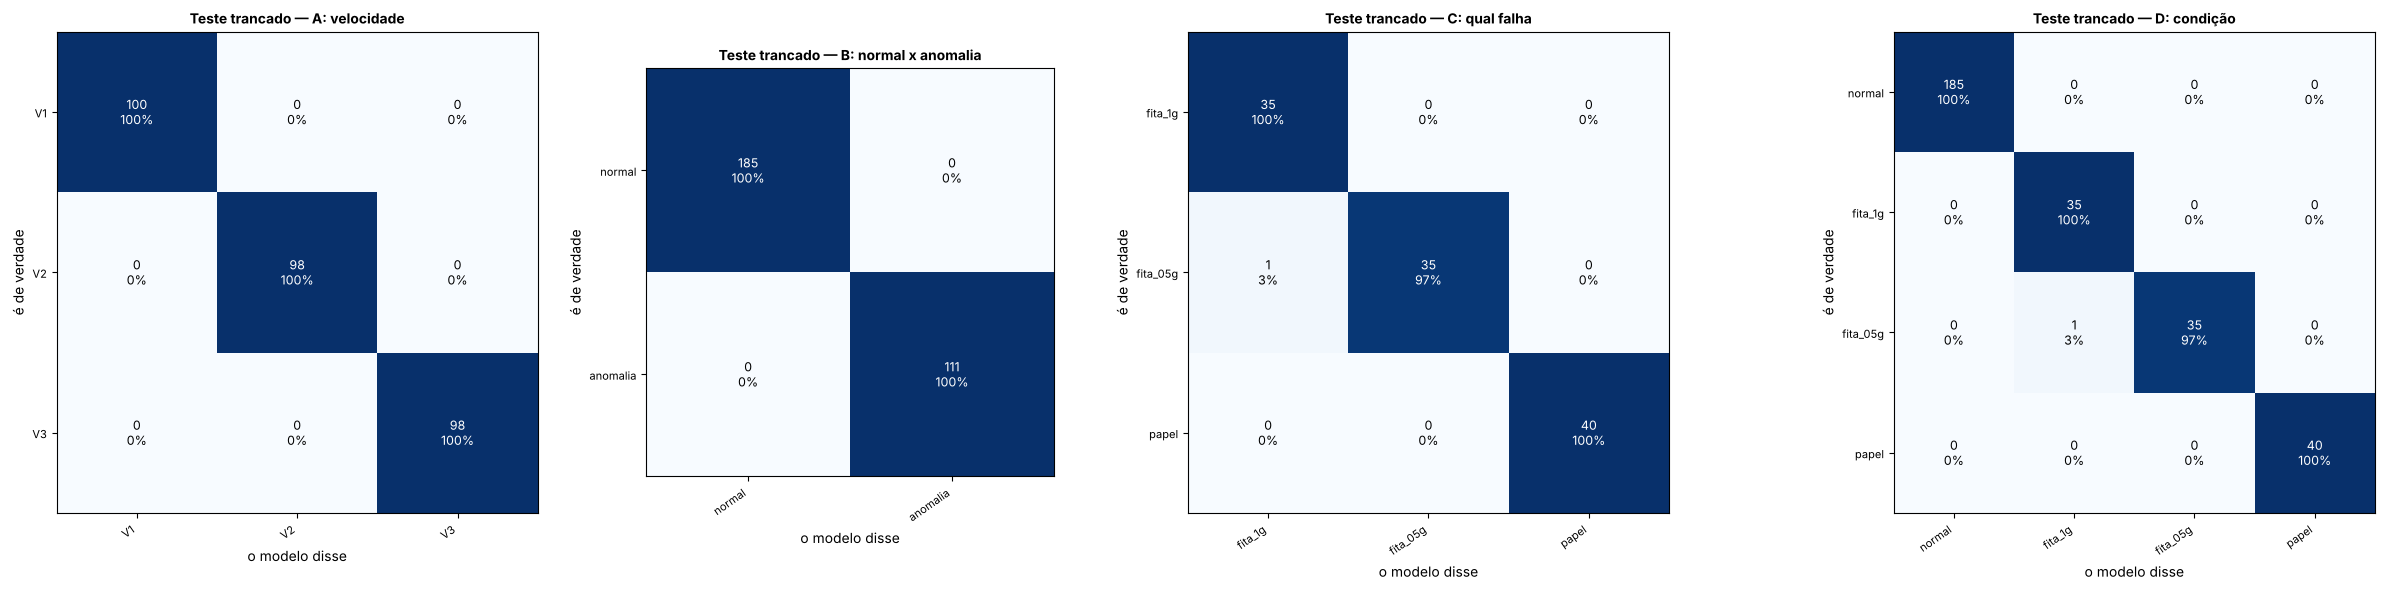

In [40]:
modelos_finais = {tarefa: treinar_escolha(escolhas[tarefa], TAREFAS[tarefa]) for tarefa in TAREFAS}

resultados_trancado, linhas = {}, []
for tarefa, t in TAREFAS.items():
    previsto = modelos_finais[tarefa].predict(t["teste"][CONJUNTOS_TODOS[escolhas[tarefa]["features"]]])
    resultados_trancado[tarefa] = previsto
    m = metricas(t["teste"][t["rotulo_real"]], previsto, t["classes"])
    linhas.append({"tarefa": tarefa, "modelo": escolhas[tarefa]["modelo"], "features": escolhas[tarefa]["features"],
                   "arquitetura": escolhas[tarefa].get("arquitetura", "—"),
                   "validação cruzada: acurácia balanceada (%)": escolhas[tarefa]["acurácia balanceada (%)"],
                   "teste trancado: acurácia balanceada (%)": m["acurácia balanceada (%)"],
                   "teste trancado: pior recall (%)": m["pior recall (%)"], "janelas no trancado": len(t["teste"])})
resumo_trancado = pd.DataFrame(linhas).set_index("tarefa")
plotar_barras(resumo_trancado[["validação cruzada: acurácia balanceada (%)", "teste trancado: acurácia balanceada (%)", "teste trancado: pior recall (%)"]]
              .rename(columns=lambda c: c.replace(": acurácia balanceada (%)", "").replace(": pior recall (%)", ": pior recall")),
              "Modelos escolhidos: validação cruzada × teste trancado", rotulo_y="%", limites_y=(80, 102), formato="{:.1f}",
              cores=["tab:blue", "tab:orange", "tab:red"])

fig, axs = plt.subplots(1, 4, figsize=(25, 6), gridspec_kw={"width_ratios": [1, 0.8, 1.1, 1.3]})
for ax, (tarefa, t) in zip(axs, TAREFAS.items()):
    plotar_matriz(t["teste"][t["rotulo_real"]], resultados_trancado[tarefa], t["classes"], f"Teste trancado — {tarefa}", ax=ax)
plt.tight_layout()
plt.show()

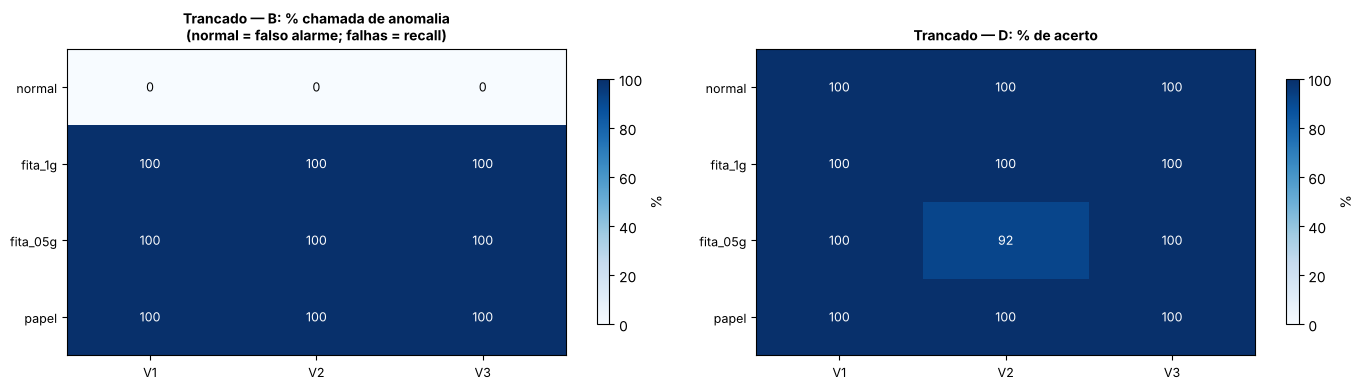

Erros no trancado — A: velocidade: nenhum
Erros no trancado — B: normal x anomalia: nenhum
Erros no trancado — C: qual falha: 1 de 111 janelas


,,,janelas
gravação,velocidade,o modelo disse,
fita_05g,V2,fita_1g,1


Erros no trancado — D: condição: 1 de 296 janelas


,,,janelas
gravação,velocidade,o modelo disse,
fita_05g,V2,fita_1g,1


In [41]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
plotar_mapa_simples(tabela_por_condicao(trancado, resultados_trancado["B: normal x anomalia"] == NOME_ANOMALIA, ORDEM_CONDICOES),
                    "Trancado — B: % chamada de anomalia\n(normal = falso alarme; falhas = recall)", ax=axs[0], cmap="Blues")
plotar_mapa_simples(tabela_por_condicao(trancado, resultados_trancado["D: condição"] == trancado["rotulo_condicao"].to_numpy(), ORDEM_CONDICOES),
                    "Trancado — D: % de acerto", ax=axs[1], cmap="Blues")
plt.tight_layout()
plt.show()

for tarefa, t in TAREFAS.items():
    errou = resultados_trancado[tarefa] != t["teste"][t["rotulo_real"]].to_numpy()
    if not errou.any():
        print(f"Erros no trancado — {tarefa}: nenhum")
        continue
    erros = pd.DataFrame({"gravação": t["teste"]["gravacao"].to_numpy()[errou], "velocidade": t["teste"]["rotulo_velocidade"].to_numpy()[errou],
                          "o modelo disse": resultados_trancado[tarefa][errou]})
    print(f"Erros no trancado — {tarefa}: {int(errou.sum())} de {len(errou)} janelas")
    display(erros.groupby(["gravação", "velocidade", "o modelo disse"]).size().rename("janelas").to_frame())

### 13.2 — Modelos simples × modelos fortes no trancado

**O que buscamos:** a resposta à pergunta do orientador e da banca: **um modelo mais forte separaria melhor?** Para cada tarefa, pegamos o **melhor de cada família** na validação cruzada (pela mesma regra), treinamos com todo o desenvolvimento e medimos no trancado.

**Esta tabela não escolhe nada.** A escolha já foi feita no começo do Passo 13, só com a validação. Ela serve para mostrar, lado a lado, o quanto cada família acerta nas janelas trancadas.

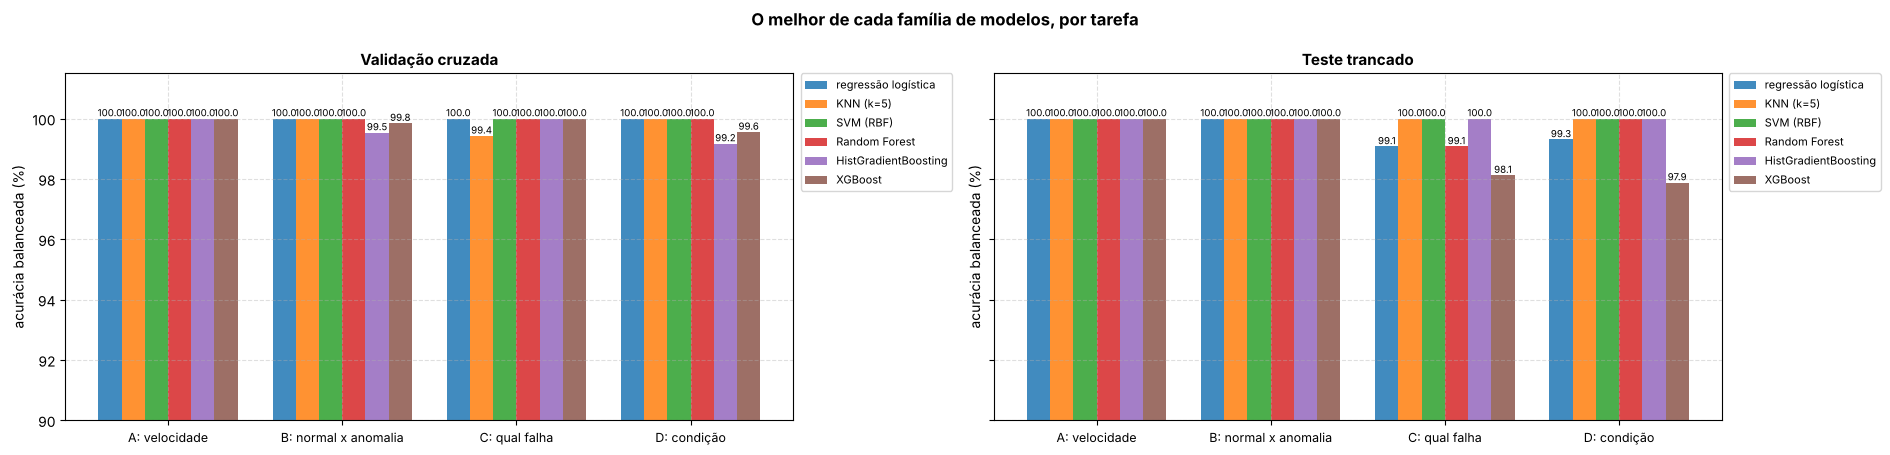

In [42]:
partes = {}
for tarefa, tabela in (("A: velocidade", tabela_a), ("B: normal x anomalia", tabela_b), ("C: qual falha", tabela_c), ("D: condição", tabela_d)):
    t, linhas = TAREFAS[tarefa], {}
    for familia, linha in melhores_por_familia(tabela).iterrows():
        escolha = {"modelo": linha["melhor combinação"], "features": linha["features"]}
        if linha["arquitetura"] != "—":
            escolha["arquitetura"] = linha["arquitetura"]
        previsto = treinar_escolha(escolha, t).predict(t["teste"][CONJUNTOS_TODOS[escolha["features"]]])
        m = metricas(t["teste"][t["rotulo_real"]], previsto, t["classes"])
        linhas[familia] = {"validação": linha["acurácia balanceada (%)"], "trancado": m["acurácia balanceada (%)"], "trancado: pior recall": m["pior recall (%)"]}
    partes[tarefa] = pd.DataFrame(linhas).T
trancado_familias = pd.DataFrame({tarefa: parte["trancado"] for tarefa, parte in partes.items()})
validacao_familias = pd.DataFrame({tarefa: parte["validação"] for tarefa, parte in partes.items()})
fig, axs = plt.subplots(1, 2, figsize=(19, 4.6), sharey=True)
plotar_barras(validacao_familias.T, "Validação cruzada", rotulo_y="acurácia balanceada (%)", ax=axs[0], limites_y=(90, 101.5), formato="{:.1f}")
plotar_barras(trancado_familias.T, "Teste trancado", rotulo_y="acurácia balanceada (%)", ax=axs[1], limites_y=(90, 101.5), formato="{:.1f}")
fig.suptitle("O melhor de cada família de modelos, por tarefa", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### 13.3 — O calço como estudo: o que o detector final faz com ele?

**O que buscamos:** o detector final foi treinado **sem o calço**. Aplicamos esse detector às janelas do calço (as de desenvolvimento e as trancadas, nenhuma usada no treino) e medimos quantas ele acusa como anomalia. É a resposta prática para "o sistema final percebe o calço?".

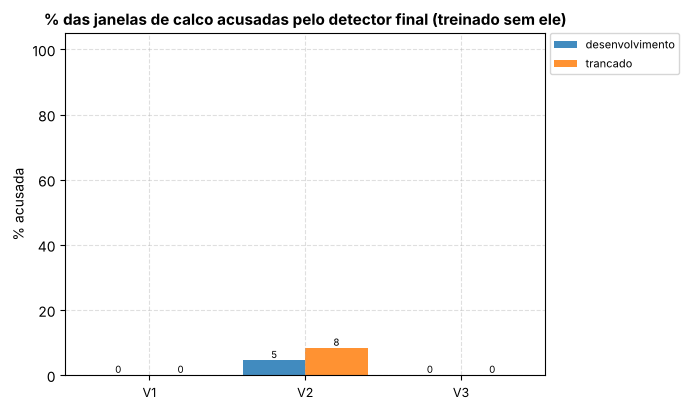

In [43]:
colunas_b = CONJUNTOS_TODOS[escolha_b["features"]]
estudo_calco = {}
for papel, dados in (("desenvolvimento", dev_completo), ("trancado", trancado_completo)):
    do_calco = dados[dados["rotulo_condicao"].isin(CONDICOES_SO_ESTUDO)]
    if len(do_calco):
        acusada = pd.Series(modelos_finais["B: normal x anomalia"].predict(do_calco[colunas_b]) == NOME_ANOMALIA)
        estudo_calco[papel] = 100 * acusada.groupby(do_calco["rotulo_velocidade"].to_numpy()).mean()
if estudo_calco:
    plotar_barras(pd.DataFrame(estudo_calco), f"% das janelas de {', '.join(CONDICOES_SO_ESTUDO)} acusadas pelo detector final (treinado sem ele)",
                  rotulo_y="% acusada", limites_y=(0, 105), formato="{:.0f}", cores=["tab:blue", "tab:orange"])

### Resultado do teste trancado

| Tarefa | Modelo escolhido | Validação cruzada | **Teste trancado** |
| --- | --- | --- | --- |
| A: velocidade | regressão logística, só `f1x_hz` | 100% | **100%** |
| B: normal × anomalia | regressão logística, FFT | 100% | **100%** |
| C: qual falha | regressão logística, FFT | 100% | **99,1%** (pior recall de 97,2%) |
| D: condição | regressão logística, classificador único, FFT | 100% | **99,3%** (pior recall de 97,2%) |

* **Um único erro, e é o mesmo nas Tarefas C e D:** uma janela da fita 0,5 g na Vel 2 chamada de fita 1 g. É o par que o Notebook 02 apontava como o mais parecido, e o erro fica dentro da mesma falha (a fita, com outra massa). **O detector (B) não erra nenhuma das 296 janelas.**
* **Diferença para a primeira versão:** lá, C e D fizeram 100% com o SVM e com a arquitetura por velocidade. Agora a regra (empate → o mais simples) escolheu a regressão logística com o classificador único, e ela erra essa janela. **KNN e SVM fazem 100% no trancado em C e D** (13.2). É uma janela em 111 (C) e em 296 (D), uma diferença pequena demais para trocar o modelo. E trocá-lo depois de olhar o trancado o deixaria otimista.
* **Modelos simples × modelos fortes (13.2):** o XGBoost é o mais fraco no trancado em C (98,1%) e em D (97,9%), como na validação. O HistGradientBoosting faz 100%. **Nenhum modelo forte supera o melhor simples.**
* **O calço como estudo (13.3):** o detector final, treinado sem o calço, acusa só **0% a 8%** das janelas do calço, com o pico na Vel 2. **O sistema final não detecta o calço.** É o preço da decisão, e ele precisa estar no texto do TCC.
* **Lembrete:** o trancado vem das mesmas gravações do treino e já tinha sido aberto na primeira versão. Ele mostra que os modelos acertam trechos não vistos destas gravações, e não que acertam outra gravação.

## Passo 14 — Teste em outra sessão: treinar no NOVOS_2.0, testar na coleta anterior

**O que buscamos:** a pergunta que o trancado não responde: **os modelos funcionam numa gravação feita em outro dia?** Usamos a coleta anterior (NOVOS_DADOS), que **nunca entrou em treino nem em escolha** deste notebook.

**As duas sessões são bem diferentes, e isso é de propósito:**

| | NOVOS_2.0 (treino) | NOVOS_DADOS (teste) |
| --- | --- | --- |
| Motor | já aquecido entre os blocos | **frio** no começo de cada gravação (1 h de espera) |
| Gravações | cerca de 3 min | cerca de 10 min, com a rotação subindo ao longo delas |
| Condições | normal, calço, fita 0,5 g, fita 1 g, papel | normal, fita 1 g, papel e **porca frouxa** |

**Como ler cada tarefa:**

* **A (velocidade):** todas as janelas.
* **B (detector):** a linha do normal é o falso alarme. **A porca frouxa é uma falha que o modelo nunca viu**; o recall dela mostra o limite do classificador supervisionado.
* **C (qual falha):** só fita 1 g e papel, que existem nas duas sessões. Confundir a fita 1 g com a fita 0,5 g é um erro "pequeno" (é a mesma falha).
* **D (condição):** normal, fita 1 g e papel. A porca aparece na matriz só para vermos como ela é chamada; ela não conta na nota, porque o modelo não conhece essa classe.

In [44]:
outra_sessao = montar_tabela(PASTAS_OUTRA_SESSAO)
CONDICOES_CONHECIDAS = [c for c in ORDEM_CONDICOES if (outra_sessao["rotulo_condicao"] == c).any()]
CONDICOES_NOVAS = [c for c in pd.unique(outra_sessao["rotulo_condicao"]) if c not in ORDEM_CONDICOES]
outra_conhecida = outra_sessao[outra_sessao["rotulo_condicao"].isin(CONDICOES_CONHECIDAS)]
outra_falhas_conhecidas = outra_conhecida[outra_conhecida["rotulo_binario"] == NOME_ANOMALIA]
print(f"Condições que o modelo conhece: {CONDICOES_CONHECIDAS}. Condições que ele nunca viu: {CONDICOES_NOVAS}.")
display(outra_sessao.groupby(["rotulo_velocidade", "rotulo_condicao"]).size().unstack())

Condições que o modelo conhece: ['normal', 'fita_1g', 'papel']. Condições que ele nunca viu: ['porca_frouxa'].


rotulo_condicao,fita_1g,normal,papel,porca_frouxa
rotulo_velocidade,,,,
V1,123,127,125,127
V2,129,129,126,127
V3,126,124,128,128


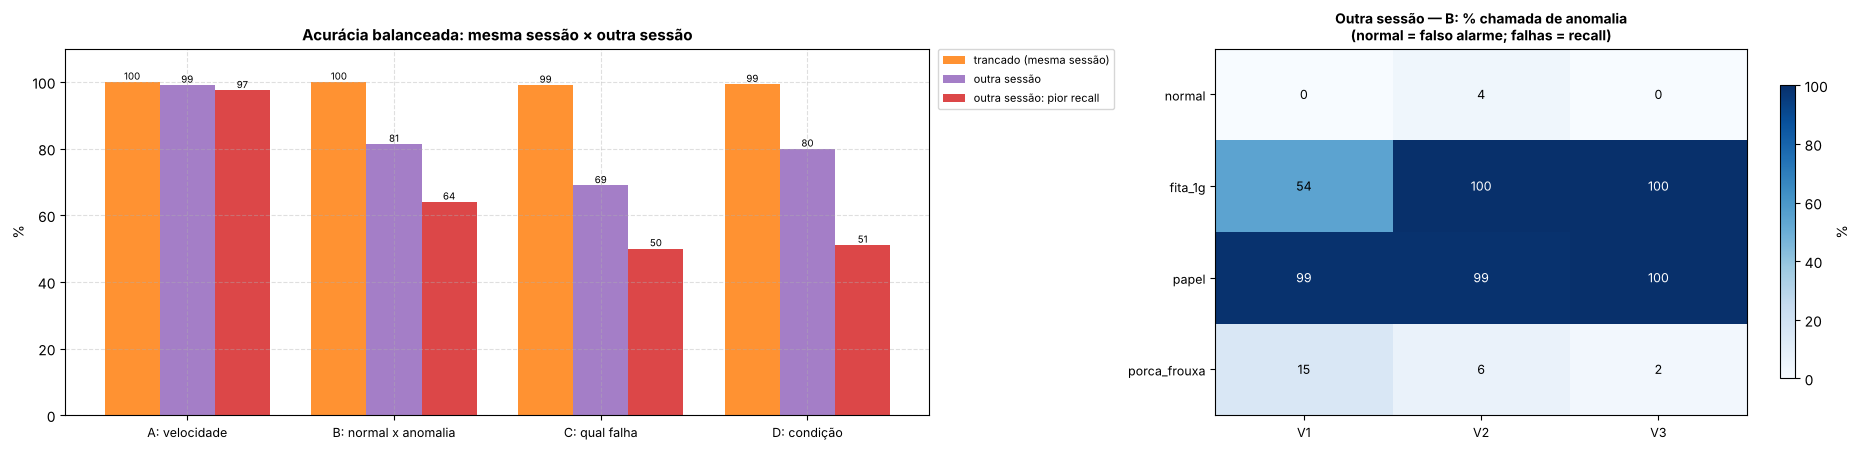

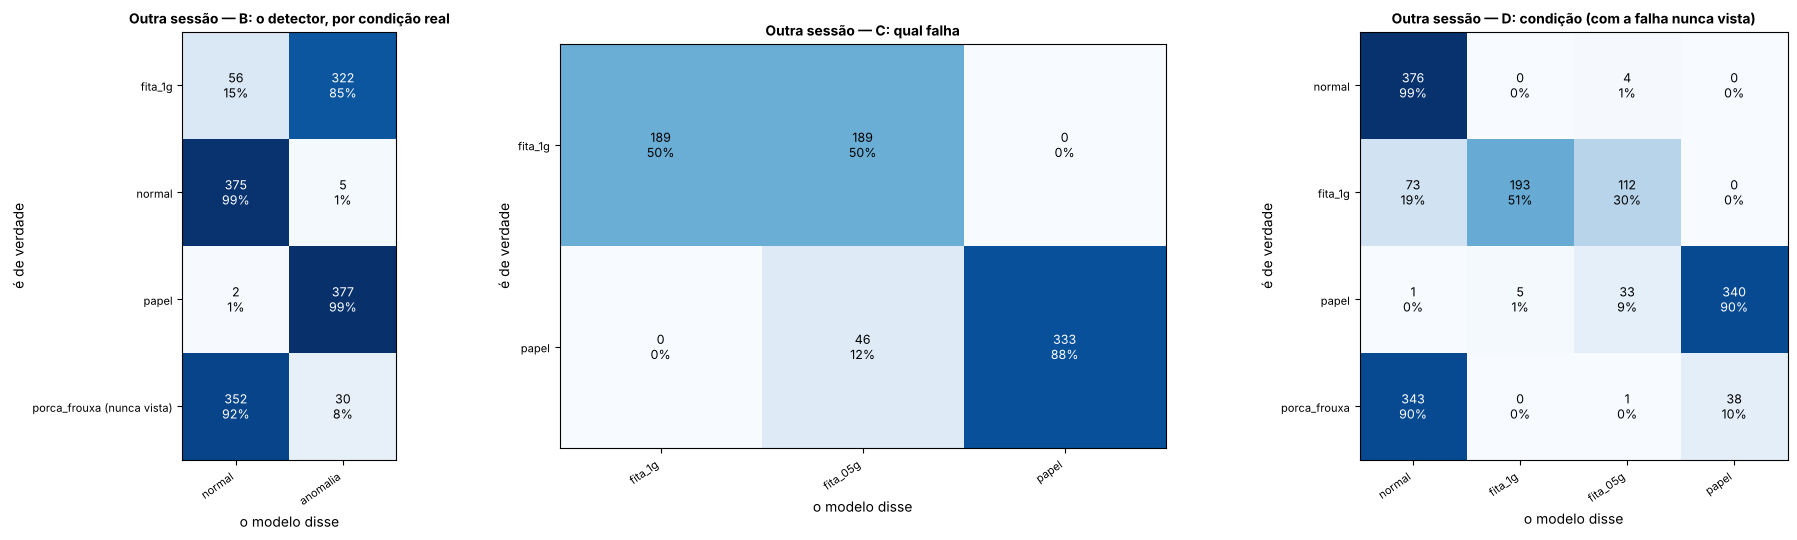

In [45]:
TAREFAS_OUTRA = {
    "A: velocidade": (outra_sessao, "rotulo_velocidade", ORDEM_VELOCIDADES),
    "B: normal x anomalia": (outra_sessao, "rotulo_binario", CLASSES_BINARIAS),
    "C: qual falha": (outra_falhas_conhecidas, "rotulo_condicao", ORDEM_FALHAS),
    "D: condição": (outra_conhecida, "rotulo_condicao", ORDEM_CONDICOES),
}
resultados_outra, linhas = {}, []
for tarefa, (dados, coluna, classes) in TAREFAS_OUTRA.items():
    previsto = modelos_finais[tarefa].predict(dados[CONJUNTOS_TODOS[escolhas[tarefa]["features"]]])
    resultados_outra[tarefa] = previsto
    m = metricas(dados[coluna], previsto, classes)
    linhas.append({"tarefa": tarefa, "classes avaliadas": ", ".join(c for c in classes if (dados[coluna] == c).any()),
                   "teste trancado (mesma sessão): acurácia balanceada (%)": resumo_trancado.loc[tarefa, "teste trancado: acurácia balanceada (%)"],
                   "outra sessão: acurácia balanceada (%)": m["acurácia balanceada (%)"], "outra sessão: pior recall (%)": m["pior recall (%)"]})
resumo_outra = pd.DataFrame(linhas).set_index("tarefa")
previsto_b_outra = resultados_outra["B: normal x anomalia"]
fig, axs = plt.subplots(1, 2, figsize=(19, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
plotar_barras(resumo_outra[["teste trancado (mesma sessão): acurácia balanceada (%)", "outra sessão: acurácia balanceada (%)", "outra sessão: pior recall (%)"]]
              .rename(columns={"teste trancado (mesma sessão): acurácia balanceada (%)": "trancado (mesma sessão)",
                               "outra sessão: acurácia balanceada (%)": "outra sessão", "outra sessão: pior recall (%)": "outra sessão: pior recall"}),
              "Acurácia balanceada: mesma sessão × outra sessão", ax=axs[0], limites_y=(0, 110), formato="{:.0f}", cores=["tab:orange", "tab:purple", "tab:red"])
plotar_mapa_simples(tabela_por_condicao(outra_sessao, previsto_b_outra == NOME_ANOMALIA, ORDEM_CONDICOES + CONDICOES_NOVAS),
                    "Outra sessão — B: % chamada de anomalia\n(normal = falso alarme; falhas = recall)", ax=axs[1], cmap="Blues")
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={"width_ratios": [0.8, 1.1, 1.3]})
reais_b = np.where(outra_sessao["rotulo_condicao"].isin(CONDICOES_NOVAS), outra_sessao["rotulo_condicao"] + " (nunca vista)", outra_sessao["rotulo_condicao"])
plotar_matriz(reais_b, previsto_b_outra, list(pd.unique(reais_b)), "Outra sessão — B: o detector, por condição real", ax=axs[0], classes_previstas=CLASSES_BINARIAS)
falhas_reais = [c for c in ORDEM_FALHAS if (outra_falhas_conhecidas["rotulo_condicao"] == c).any()]
plotar_matriz(outra_falhas_conhecidas["rotulo_condicao"], resultados_outra["C: qual falha"], falhas_reais, "Outra sessão — C: qual falha", ax=axs[1], classes_previstas=ORDEM_FALHAS)
previsto_d_tudo = modelos_finais["D: condição"].predict(outra_sessao[CONJUNTOS_TODOS[escolhas["D: condição"]["features"]]])
plotar_matriz(outra_sessao["rotulo_condicao"], previsto_d_tudo, CONDICOES_CONHECIDAS + CONDICOES_NOVAS, "Outra sessão — D: condição (com a falha nunca vista)",
              ax=axs[2], classes_previstas=ORDEM_CONDICOES)
plt.tight_layout()
plt.show()

### 14.1 — O detector ao longo das gravações da outra sessão

**O que buscamos:** na coleta anterior o motor começa frio e esquenta durante os 10 min de cada gravação. Dividimos cada gravação em **começo, meio e fim** e medimos a % de janelas acusadas em cada trecho. Se os erros se concentrarem no começo (motor frio, um estado que o treino não tem), o problema é o estado térmico.

A segunda tabela repete o teste com o **melhor de cada família** de modelos: os mais fortes se saem melhor em outra sessão?

In [46]:
def terco_da_janela(dados):
    """Em qual terço da gravação (começo, meio, fim) cada janela está."""
    posicao = dados.groupby("base")["janela"].rank(pct=True)
    return np.select([posicao <= 1 / 3, posicao <= 2 / 3], ["começo", "meio"], "fim")

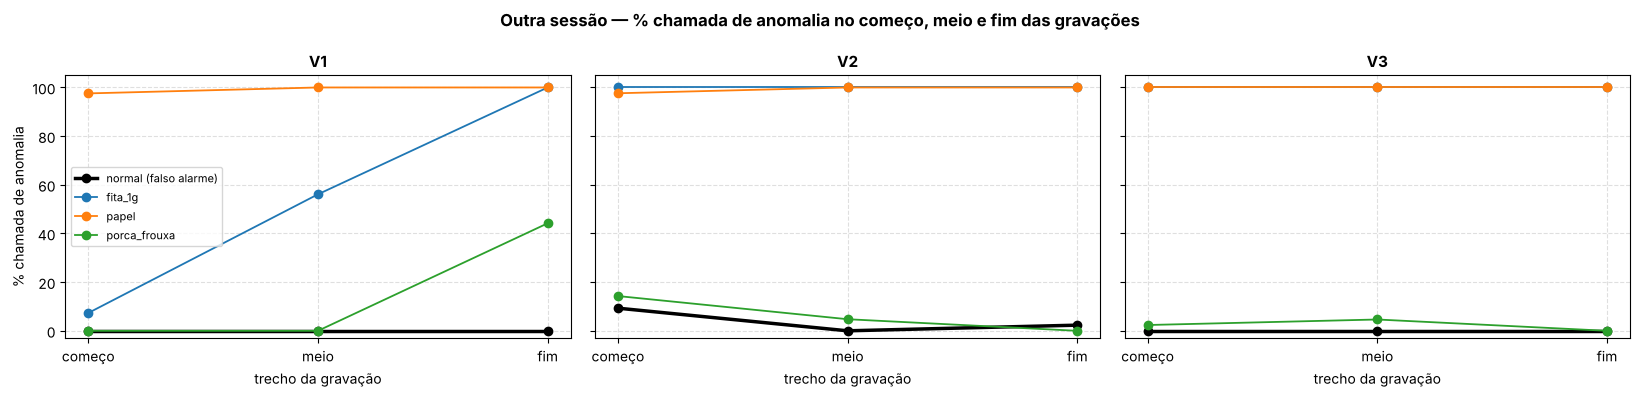

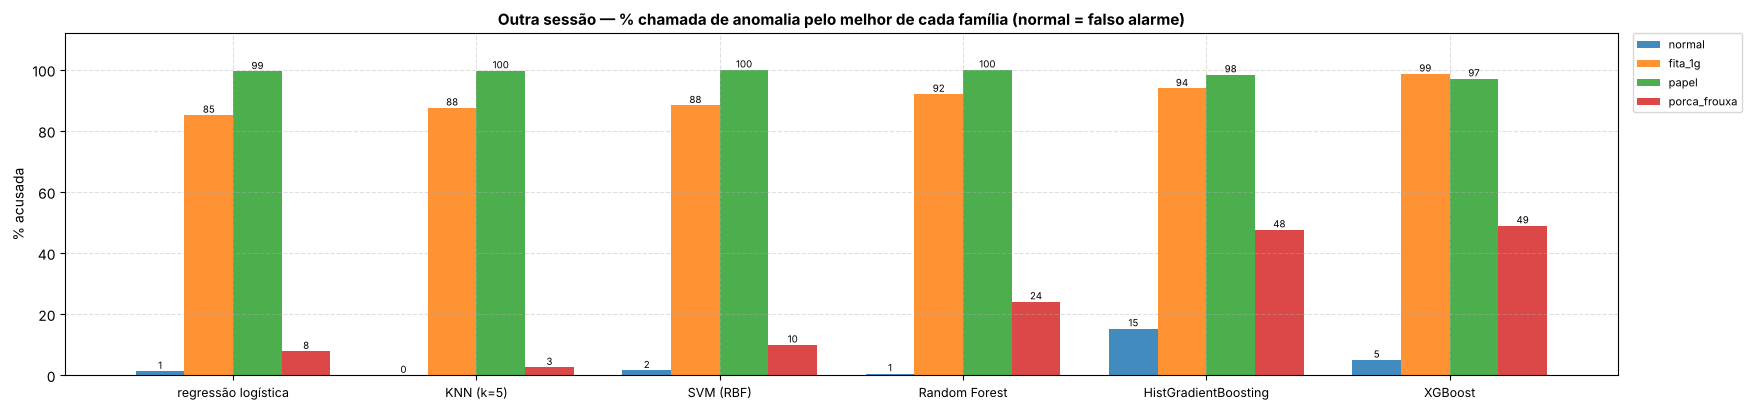

In [47]:
por_terco = pd.DataFrame({"condicao": outra_sessao["rotulo_condicao"].to_numpy(), "velocidade": outra_sessao["rotulo_velocidade"].to_numpy(),
                          "terço": terco_da_janela(outra_sessao), "acusada": previsto_b_outra == NOME_ANOMALIA})
por_terco_tabela = 100 * por_terco.pivot_table(index=["condicao", "velocidade"], columns="terço", values="acusada", aggfunc="mean")[["começo", "meio", "fim"]]
fig, axs = plt.subplots(1, len(ORDEM_VELOCIDADES), figsize=(5.5 * len(ORDEM_VELOCIDADES), 4), sharey=True)
for ax, velocidade in zip(axs, ORDEM_VELOCIDADES):
    for condicao in [c for c in CONDICOES_CONHECIDAS + CONDICOES_NOVAS if (c, velocidade) in por_terco_tabela.index]:
        linha = por_terco_tabela.loc[(condicao, velocidade)]
        ax.plot(linha.index, linha.values, marker="o", linewidth=2.5 if condicao == NOME_NORMAL else 1.3,
                color="black" if condicao == NOME_NORMAL else None, label=condicao + (" (falso alarme)" if condicao == NOME_NORMAL else ""))
    ax.set_ylim(-3, 105)
    ax.set_title(velocidade, fontsize=11, fontweight="bold")
    ax.set_xlabel("trecho da gravação")
axs[0].set_ylabel("% chamada de anomalia")
axs[0].legend(fontsize=8)
fig.suptitle("Outra sessão — % chamada de anomalia no começo, meio e fim das gravações", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

linhas = {}
for familia, linha in melhores_por_familia(tabela_b).iterrows():
    escolha = {"modelo": linha["melhor combinação"], "features": linha["features"]}
    previsto = treinar_escolha(escolha, TAREFAS["B: normal x anomalia"]).predict(outra_sessao[CONJUNTOS_TODOS[escolha["features"]]])
    acusada = pd.Series(previsto == NOME_ANOMALIA).groupby(outra_sessao["rotulo_condicao"].to_numpy()).mean() * 100
    linhas[familia] = {"combinação": f"{linha['melhor combinação']}, {linha['features']}",
                       "acurácia balanceada (%)": metricas(outra_sessao["rotulo_binario"], previsto, CLASSES_BINARIAS)["acurácia balanceada (%)"],
                       **{f"% acusada: {c}": acusada[c] for c in CONDICOES_CONHECIDAS + CONDICOES_NOVAS}}
familias_outra = pd.DataFrame(linhas).T
plotar_barras(familias_outra[[f"% acusada: {c}" for c in CONDICOES_CONHECIDAS + CONDICOES_NOVAS]].astype(float)
              .rename(columns=lambda c: c.replace("% acusada: ", "")),
              "Outra sessão — % chamada de anomalia pelo melhor de cada família (normal = falso alarme)", rotulo_y="% acusada",
              limites_y=(0, 112), formato="{:.0f}")

### 14.2 — O que acontece na outra sessão se o calço entrar no detector?

**O que buscamos:** registrar o motivo da decisão de tirar o calço, com o detector desta versão, e medir a distância entre as sessões.

**1. Com e sem o calço no treino.** O calço é uma falha fraca: para aprendê-lo, o detector precisa tratar como anomalia **desvios pequenos** em relação ao normal desta sessão. Um normal gravado em outro dia também tem desvios pequenos. Treinamos o mesmo detector (o escolhido nesta versão) **com e sem o calço** e medimos a % de janelas acusadas na outra sessão.

**2. A distância entre as sessões.** Para cada velocidade, contamos em quantas das 109 features a **mediana** de uma gravação fica **fora da faixa** (do mínimo ao máximo) de um conjunto de referência:

* o **normal da outra sessão** contra os 5 lotes de normal desta sessão;
* como régua, **cada lote normal desta sessão** contra os outros 4 (mostramos o maior valor);
* o **calço** contra os 5 lotes de normal desta sessão.

Se o normal da outra sessão ficar fora da faixa em muito mais features do que um lote desta sessão fica dos outros, as duas sessões são "mundos" diferentes para o modelo, e nenhum classificador treinado só nesta sessão tem como saber que aquilo também é normal.

**Estes testes são diagnósticos.** Eles usam a outra sessão para **explicar** o resultado, não para escolher modelo.

In [48]:
def acusadas_na_outra_sessao(dados_treino, outra, escolha):
    """Treina o detector escolhido em dados_treino e devolve, para cada janela de 'outra', se foi acusada de anomalia."""
    colunas = CONJUNTOS_TODOS[escolha["features"]]
    modelo = criar_pipeline(MODELOS[escolha["modelo"]](), colunas).fit(dados_treino[colunas], dados_treino["rotulo_binario"])
    return modelo.predict(outra[colunas]) == NOME_ANOMALIA


def features_fora_da_faixa(referencia, testada, colunas):
    """Em quantas features a mediana de 'testada' fica fora da faixa (mínimo a máximo) de 'referencia'."""
    mediana = testada[colunas].median()
    return int(((mediana < referencia[colunas].min()) | (mediana > referencia[colunas].max())).sum())


def comparar_sessoes(esta, outra, colunas):
    """Por velocidade: features fora da faixa (normal da outra sessão, o pior lote desta sessão e a condição em avaliação)
    e a rotação mediana do normal nas duas sessões."""
    linhas = []
    for velocidade in ORDEM_VELOCIDADES:
        e, o = esta[esta["rotulo_velocidade"] == velocidade], outra[outra["rotulo_velocidade"] == velocidade]
        normais, normal_outra = e[e["rotulo_binario"] == NOME_NORMAL], o[o["rotulo_binario"] == NOME_NORMAL]
        lotes = [features_fora_da_faixa(normais[normais["gravacao"] != lote], normais[normais["gravacao"] == lote], colunas)
                 for lote in GRAVACOES_NORMAIS]
        linhas.append({
            "velocidade": velocidade,
            "normal da outra sessão": features_fora_da_faixa(normais, normal_outra, colunas),
            "lote normal desta sessão × outros 4 (maior)": max(lotes),
            f"{CONDICAO_EM_AVALIACAO} desta sessão": features_fora_da_faixa(normais, e[e["rotulo_condicao"] == CONDICAO_EM_AVALIACAO], colunas),
            "rotação do normal, esta sessão (Hz)": normais["f1x_hz"].median(),
            "rotação do normal, outra sessão (Hz)": normal_outra["f1x_hz"].median(),
        })
    return pd.DataFrame(linhas).set_index("velocidade")

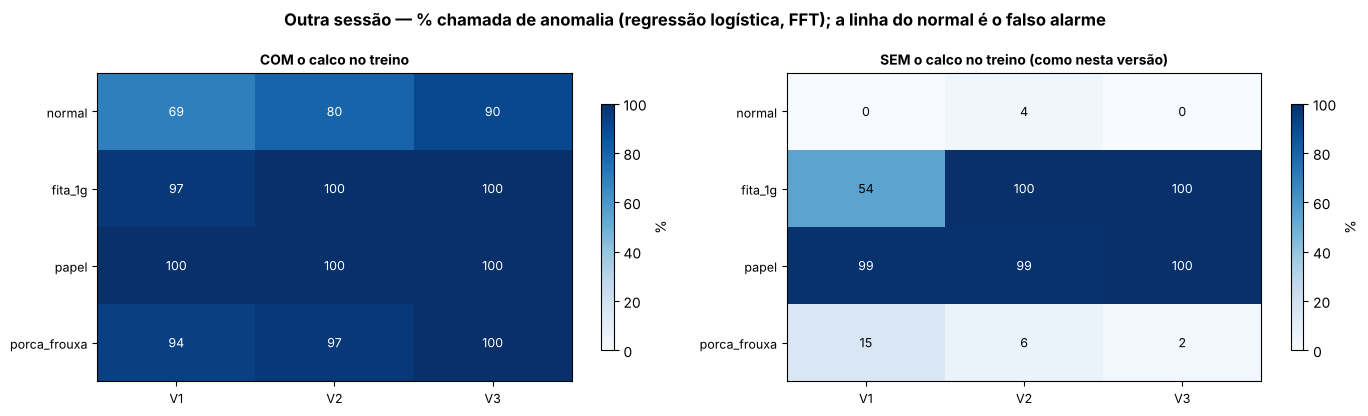

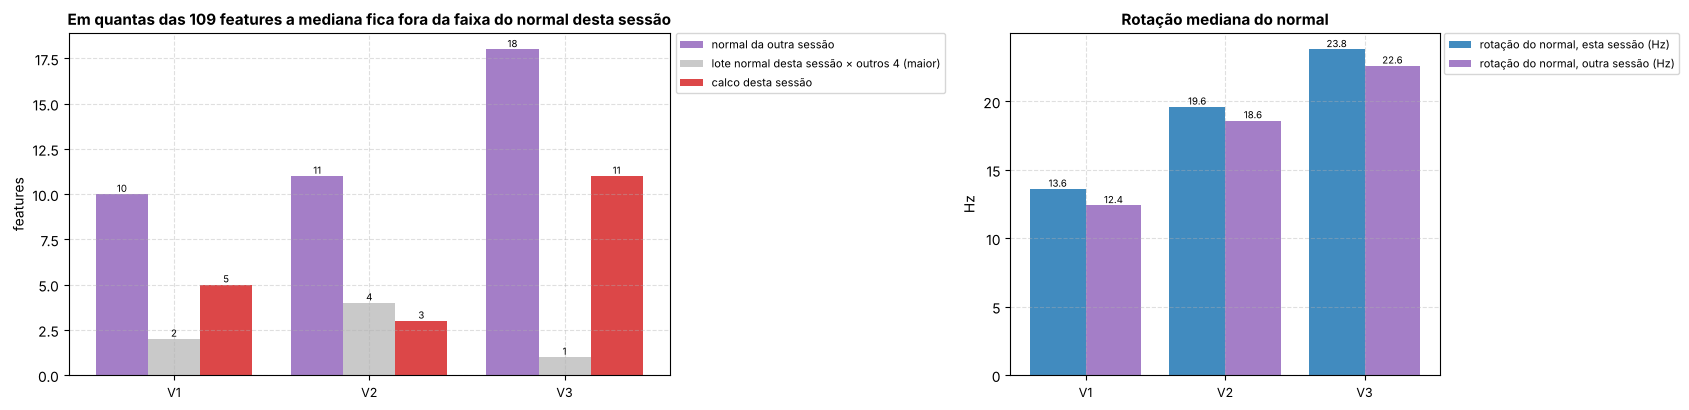

In [49]:
sem_a_condicao = dev_completo[dev_completo["rotulo_condicao"] != CONDICAO_EM_AVALIACAO]
ordem_outra = CONDICOES_CONHECIDAS + CONDICOES_NOVAS
com_calco = tabela_por_condicao(outra_sessao, acusadas_na_outra_sessao(dev_completo, outra_sessao, escolha_b), ordem_outra)
sem_calco = tabela_por_condicao(outra_sessao, acusadas_na_outra_sessao(sem_a_condicao, outra_sessao, escolha_b), ordem_outra)
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
plotar_mapa_simples(com_calco, f"COM o {CONDICAO_EM_AVALIACAO} no treino", ax=axs[0], cmap="Blues")
plotar_mapa_simples(sem_calco, f"SEM o {CONDICAO_EM_AVALIACAO} no treino (como nesta versão)", ax=axs[1], cmap="Blues")
fig.suptitle(f"Outra sessão — % chamada de anomalia ({escolha_b['modelo']}, {escolha_b['features']}); a linha do normal é o falso alarme",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

distancia = comparar_sessoes(features, outra_sessao, COLUNAS_TODAS)
fig, axs = plt.subplots(1, 2, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
plotar_barras(distancia.iloc[:, :3], f"Em quantas das {len(COLUNAS_TODAS)} features a mediana fica fora da faixa do normal desta sessão",
              rotulo_y="features", ax=axs[0], formato="{:.0f}", cores=["tab:purple", "silver", "tab:red"])
plotar_barras(distancia.iloc[:, 3:], "Rotação mediana do normal", rotulo_y="Hz", ax=axs[1], formato="{:.1f}", cores=["tab:blue", "tab:purple"])
plt.tight_layout()
plt.show()

### Resultado do teste em outra sessão

| Tarefa | Trancado (mesma sessão) | **Outra sessão** | Primeira versão (com o calço), outra sessão |
| --- | --- | --- | --- |
| A: velocidade | 100% | **99%** | 99,1% |
| B: normal × anomalia | 100% | **81%** | 59,4% |
| C: qual falha (fita 1 g e papel) | 99% | **69%** | 79,9% |
| D: condição (normal, fita 1 g, papel) | 99% | **80%** | 55,5% |

**O detector (B) agora funciona em outra sessão:**
* **Falso alarme de 0%, 4% e 0%** (Vel 1, 2 e 3), contra 69% a 90% na primeira versão. O normal da outra sessão é reconhecido como normal.
* **O papel é detectado em 99% a 100%** das janelas. **A fita 1 g, em 100% nas Vel 2 e 3, mas em só 54% na Vel 1**: é o caso difícil entre sessões, como na coleta anterior (13,6% na Vel 1).
* **A porca frouxa (nunca vista) quase não é detectada:** 2% a 15%. Na primeira versão, ela era "acusada" de carona porque o detector acusava tudo.
* **14.1, por trecho da gravação:** na Vel 1, a fita 1 g sobe de 7% no começo para 56% no meio e 100% no fim, e a porca vai de 0% a 44% no fim. A outra sessão foi gravada com o motor frio, e as falhas só aparecem depois que o conjunto aquece. **O normal fica em 0% do começo ao fim** (exceto 9% no começo da Vel 2).
* **Modelos mais fortes:** HistGradientBoosting e XGBoost acusam mais a porca (48% e 49%), mas com **mais falso alarme** (15% e 5%). Os modelos simples ficam com 0% a 2% de falso alarme e 3% a 10% de porca.

**Diagnóstico entre sessões (C e D):**
* **C:** a fita 1 g vai metade para "fita 1 g" e metade para "fita 0,5 g": **100% são chamadas de fita**, mas a massa não se transfere entre sessões. O papel é reconhecido em 88%; os outros 12% vão para fita 0,5 g.
* **D:** normal 99%, papel 90%, fita 1 g 51% (30% vão para fita 0,5 g e 19% para normal). **A porca vai 90% para "normal".**

**14.2 — Por que tirar o calço:** com o mesmo modelo e as mesmas features, colocar o calço no treino leva o falso alarme na outra sessão de 0%–4% para **69%–90%**. A mediana do normal da outra sessão fica fora da faixa dos 5 lotes desta sessão em **10, 11 e 18 features**. Para comparação, a do calço fica fora em 5, 3 e 11, e a de um lote desta sessão contra os outros, em no máximo 4. **O normal de outro dia está mais longe do normal desta sessão do que o calço.** Um detector ensinado a pegar o calço acusa, por tabela, qualquer normal de outro dia. A rotação do normal também é cerca de 1 Hz menor na outra sessão (12,4 × 13,6 Hz na Vel 1).

**Ressalva importante:** a decisão de tirar o calço foi tomada **depois** de ver este resultado. O 81% da Tarefa B em outra sessão não é uma prova independente: ele é, em parte, o motivo da decisão. A prova independente virá de uma sessão nova.

## Resumo e decisões

**O que este notebook mostra, em quatro frases:**

1. **Sem o calço, dentro da sessão tudo funciona:** 100% na validação cruzada nas quatro tarefas, e no trancado só um erro (fita 0,5 g → fita 1 g, uma janela).
2. **Em outra sessão, o detector agora funciona:** falso alarme de 0% a 4% (contra 69% a 90% com o calço), papel e fita 1 g detectados (menos a fita 1 g na Vel 1 com motor frio, 54%).
3. **O XGBoost não ficou atrás por causa da profundidade nem da taxa de aprendizado.** Uma grade de 36 combinações fica entre 94,7% e 98,4%, e os erros são janelas fora da faixa do treino (o começo do papel na Vel 3). Árvores não extrapolam; com uma gravação por condição, o modelo linear generaliza melhor.
4. **Os limites que ficam:** o calço não é detectado (0% a 8%), a porca frouxa nunca vista também não (2% a 15%), e a massa da fita não se transfere entre sessões.

### Decisões e indicações

| Item | Resultado |
| --- | --- |
| Calço | **Fora dos modelos, só como estudo** (decisão do grupo em 13 nov). Pela regra, ficaria; o custo em outra sessão pesou mais |
| Modelo | **Regressão logística** em A, B, C e D (com `f1x_hz` em A e FFT nas outras) |
| Arquitetura | As três empatam em 100%; a escolha para a API pode seguir a modularidade |
| Modelos mais fortes | Sem ganho; o XGBoost é o mais fraco com todas as features, por falta de dados (12.6) |
| Linhas elétricas (120 e 240 Hz) | Não sustentam o resultado |
| Protocolo de coleta | Conferir se as gravações começam com a condição estável (o papel na Vel 3 levou cerca de 100 s) |

### O que entra no texto do TCC

* **O calço como resultado honesto:** ele inclina o ventilador e muda pouco a vibração. Dentro da sessão ele é separável (regra e placebos), mas um detector que nunca o viu não o acusa, e ensiná-lo ao detector o deixa inútil em outro dia.
* **A comparação com modelos fortes:** foi feita na mesma esteira, com grade fixada antes e uma grade ampliada depois (como explicação). Sem ganho.

### Ressalvas desta versão

* O teste trancado já tinha sido aberto na primeira versão. Ele continua fora das escolhas, mas é uma segunda leitura.
* A decisão de tirar o calço veio do resultado em outra sessão. Por isso o resultado em outra sessão sem o calço não é independente.
* A grade ampliada do XGBoost foi feita depois de ver os resultados. Ela explica e não escolhe modelo.

### O que isso muda para o Notebook 06

* **O normal de uma sessão não cobre o normal de outra:** é a lição principal, e é a razão de juntar todas as sessões num normal mais largo.
* **A avaliação por sessão inteira deixada de fora é obrigatória.**
* **Os casos de teste difíceis para um detector só de normal:** o calço, a porca frouxa e a fita 1 g na Vel 1 com motor frio.

## O que conferir antes de seguir para o Notebook 06

* [ ] **Passo 7:** o calço passa na regra (3 velocidades), nenhum placebo passa e, mesmo assim, o calço ficou fora dos modelos por decisão do grupo.
* [ ] **Passos 9 a 11:** sem o calço, 100% na validação cruzada com regressão logística.
* [ ] **Passo 12.6:** a grade do XGBoost não chega à regressão logística, e os erros são janelas fora da faixa do treino.
* [ ] **Passo 13:** um erro no trancado (fita 0,5 g → fita 1 g), e o detector final não acusa o calço.
* [ ] **Passo 14:** falso alarme de 0% a 4% em outra sessão; a porca e a fita 1 g na Vel 1 como limites.
* [ ] **Ressalvas:** o trancado foi aberto duas vezes, e a decisão do calço veio da outra sessão.

**Próximo passo:** o **Notebook 06**, com a base concatenada de todas as sessões, um detector treinado só com o normal e a avaliação com uma sessão inteira deixada de fora.